# 02 · Exploratory Data Analysis & Business Insight Discovery
**Customer Revenue Intelligence**, Step 4

> ⚠️ **SYNTHETIC DATA.** The analysis runs on `data/processed/customer_sales_cleaned.csv`, the Step 3 output. No real customers or transactions are represented.

This notebook presents the analysis implemented in `src/eda.py`:
- **Code cells** show the computed tables and charts.
- **Observation** cells describe what the data shows.
- **Interpretation** cells give the business meaning. These are hypotheses to test, not proven causes.

Every number quoted in the text also appears in the code output directly above it.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import pandas as pd
from IPython.display import Image, display, Markdown
import config
from src import eda

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
FIG = config.FIGURES_DIR

# Runs every analysis once, saves all tables / figures / the summary report
R = eda.run_eda(make_plots=True, verbose=False)
df = R["df"]
print(f"Loaded {config.CLEAN_DATA_FILE.name}: {df.shape[0]:,} rows x {df.shape[1]} columns")

Loaded customer_sales_cleaned.csv: 18,670 rows x 51 columns


## 1. EDA Objective
The aim is to understand **how revenue and profit are generated** before any modelling:
- trends over time and seasonality;
- which categories, products, regions and customers matter most;
- how discounts relate to profit;
- which questions the RFM, segmentation, CLV, prediction and forecasting steps should answer.

**Measurement rules (applied throughout)**

| Rule | Why |
|---|---|
| Revenue, cost, profit and units = **Delivered** lines only | Cancelled and returned sales were never realised. They are analysed separately in Section 10.3. |
| Order = distinct `Order_ID` with ≥ 1 Delivered line | Verified below. One row is one product in an order, so rows ≠ orders. |
| Customer age is summarised **per customer** | Otherwise frequent buyers would be counted many times. |
| Correlation = association only | Nothing in this notebook proves causation. |

In [2]:
R['order_definition']

,Check,Value,Meaning
0,Order lines (rows),18670,One row = one product in one order
1,Duplicate Order_Line_ID,0,Must be 0 - no double counting
2,Distinct Order_ID,13251,Candidate order count
3,"Distinct (Customer, Date) pairs",13251,Equals Order_ID count -> one checkout per customer per day
4,Order_IDs with >1 customer / date / payment,0,Must be 0 - Order_ID is a single checkout
5,Orders with >1 line (multi-product),4214,Why rows != orders
6,Orders with >= 1 Delivered line,12212,Order count used for AOV and order KPIs
7,Orders with no Delivered line,1039,Fully cancelled / returned - excluded from realised KPIs


**Observation.** The 13,251 `Order_ID`s match 13,251 distinct (customer, date) pairs exactly. No Order_ID has more than one customer, date or payment method. 4,214 orders contain more than one product.

**Conclusion.** `Order_ID` is a valid order key. Counting rows instead would overstate orders by about 41% (18,670 rows vs 13,251 orders). A further 1,039 orders were entirely cancelled or returned, which leaves **12,212 realised orders**.

## 2. Dataset Overview

In [3]:
R['dataset_summary']

,Item,Value
0,"Rows (order lines, all statuses)","18,670"
1,Columns,51
2,Date range,01 Jan 2023 - 31 Dec 2025
3,Months covered,36
4,Unique customers,"2,000"
5,Unique products,61
6,Categories,6
7,Sub-categories,26
8,Cities,34 (+ 'Unknown' for 1 customer)
9,States / UTs,21


In [4]:
R['kpis'][['KPI', 'Display', 'Formula']]

,KPI,Display,Formula
0,Total Revenue,₹6.01 Cr,"Sum of Sales, Delivered lines"
1,Total Cost,₹4.60 Cr,"Sum of Cost, Delivered lines"
2,Total Profit,₹1.40 Cr,"Sum of Profit, Delivered lines"
3,Overall Profit Margin,23.3%,Total Profit / Total Revenue
4,Total Quantity Sold,"22,772 units","Sum of Quantity, Delivered lines"
5,Number of Orders,"12,212",Distinct Order_ID with >= 1 Delivered line
6,Purchasing Customers,"1,984",Distinct Customer_ID with >= 1 Delivered line
7,Average Order Value (AOV),"₹4,918",Total Revenue / Number of Orders
8,Average Revenue per Customer,"₹30,270",Total Revenue / Purchasing Customers
9,Average Profit per Order,"₹1,148",Total Profit / Number of Orders


**Observation.**
- Realised revenue is **₹6.01 Cr**, with profit of ₹1.40 Cr, an overall margin of **23.3%**.
- There are 12,212 orders from 1,984 purchasing customers.
- AOV is ₹4,918, and customers place 6.16 orders on average over three years.
- ₹6.63 Cr was booked in total, but **9.4% (₹62.55 L) was never realised**.

**Interpretation.** The business depends on repeat purchases rather than one-off baskets. Cancellations and returns are a material leak, equal to about 2.8 months of average 2025 monthly revenue.

## 3. Descriptive Statistics

In [5]:
R['descriptive_stats']

,Variable,Count,Mean,Median,Std,Min,Q1,Q3,Max,Skewness,Kurtosis,Shape
0,Quantity,16860,1.351,1.000,1.415,1.000,1.000,1.000,50.000,24.479,742.175,strongly right-skewed
1,Unit_Price,16860,"3,343.115","1,612.000","7,080.692",291.000,907.000,"2,713.250","98,119.000",6.928,63.335,strongly right-skewed
2,Discount,16860,0.121,0.100,0.100,0.000,0.000,0.200,0.400,0.358,-0.751,approximately symmetric
3,Sales,16860,"3,562.074","1,706.225","7,596.344",219.050,"1,013.900","3,122.825","176,942.000",7.751,88.215,strongly right-skewed
4,Cost,16860,"2,730.369","1,046.360","7,153.263",127.850,554.138,"1,982.060","167,369.260",7.888,89.400,strongly right-skewed
5,Profit,16860,831.705,638.520,"1,113.862","-14,964.800",388.538,"1,014.110","45,435.740",10.805,304.321,strongly right-skewed
6,Customer_Age (per customer),2000,32.146,32.000,8.915,18.000,26.000,38.000,61.000,0.366,-0.338,approximately symmetric


**Observation.**
- **Sales, Cost, Profit, Unit_Price and Quantity are strongly right-skewed** (skewness 6.9 to 24.5). Mean Sales per line is ₹3,562, more than double the median of ₹1,706.
- **Discount** is roughly symmetric, from 0% to 40% in 5% steps, with a median of 10%.
- **Customer age** is roughly symmetric: median 32, range 18 to 61.

**Interpretation.**
- A few premium lines (laptops, phones, TVs) pull the average up. **Medians describe a typical transaction better than means**, so both are reported.
- Skewed variables need log transforms or robust scaling in the ML steps.

## 4. Univariate Analysis
### 4.1 Numeric variables

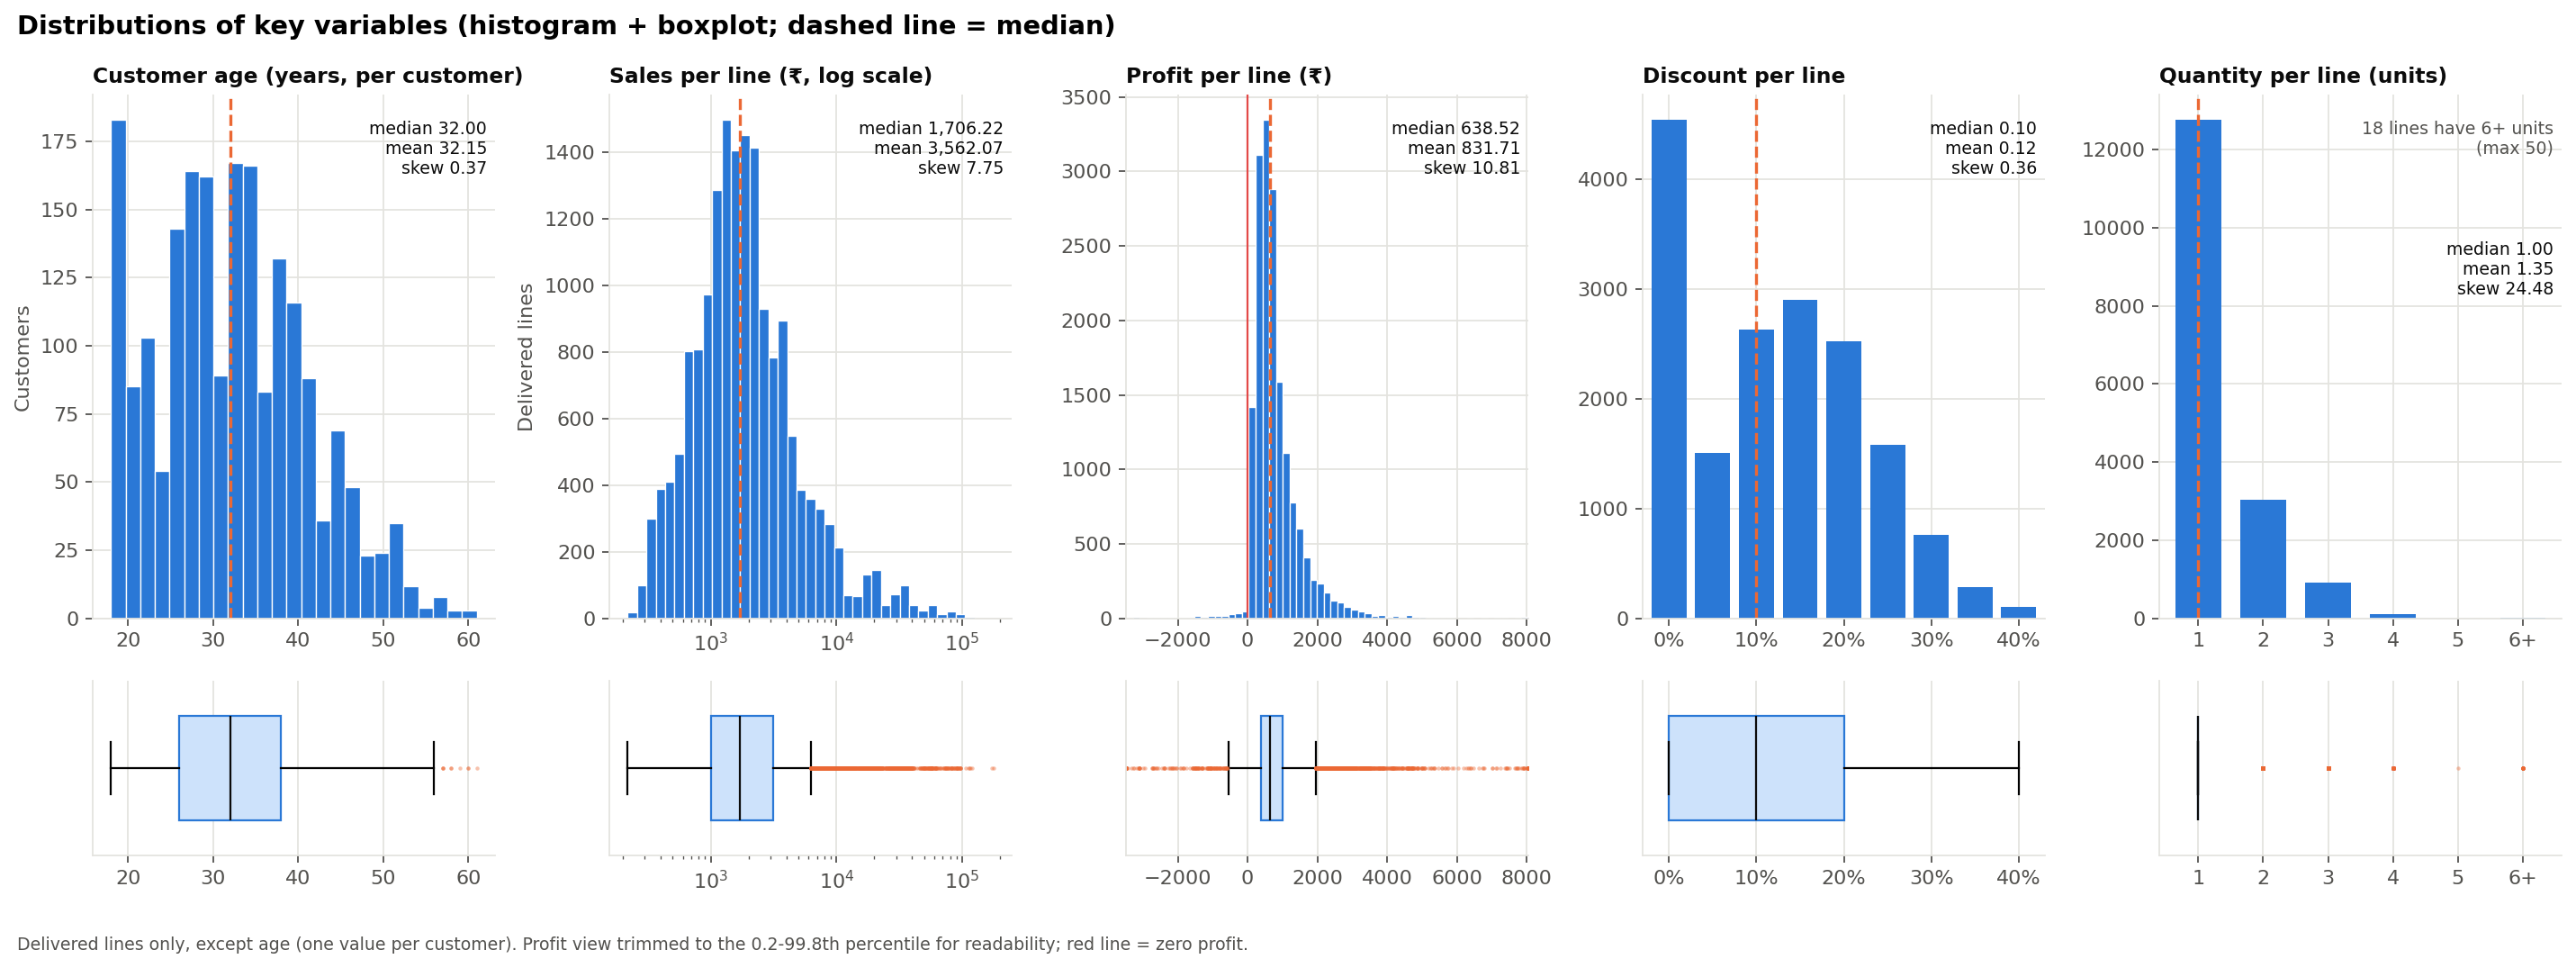

In [6]:
Image(str(FIG / "univariate_distributions.png"))

In [7]:
display(R['univariate']['age_summary']); display(R['univariate']['age_bands']); R['univariate']['quantity_dist'].head(6)

,Metric,Value
0,Customers,"2,000.000"
1,Mean age,32.100
2,Median age,32.000
3,Youngest,18.000
4,Oldest,61.000
5,Share aged 25-34,0.406


,Age_Band,Customers,Share
0,18-24,425,0.212
1,25-34,813,0.406
2,35-49,685,0.343
3,50+,77,0.038


,Quantity,Lines,Share
0,1,12767,0.757
1,2,3039,0.180
2,3,926,0.055
3,4,109,0.006
4,5,1,0.000
5,21,2,0.000


**Observation.**
- **Age:** 41% of customers are 25-34 and 34% are 35-49. Only 3.9% are 50+.
- **Sales per line** is log-normal-like. Its long right tail comes from premium Electronics.
- **Profit** is concentrated between ₹390 and ₹1,010 (the interquartile range), with a thin tail of losses.
- **Discount:** 27% of lines are at full price, and deep discounts of 30% or more are rare (6.8% of lines).
- **Quantity:** 76% of lines have 1 unit, and 18 lines have 6 or more (bulk orders, kept on purpose).

**Interpretation.** This is a young customer base (75% aged 25-49) buying mostly single items. Revenue therefore depends on how often customers buy, not on basket size.

### 4.2 Categorical variables

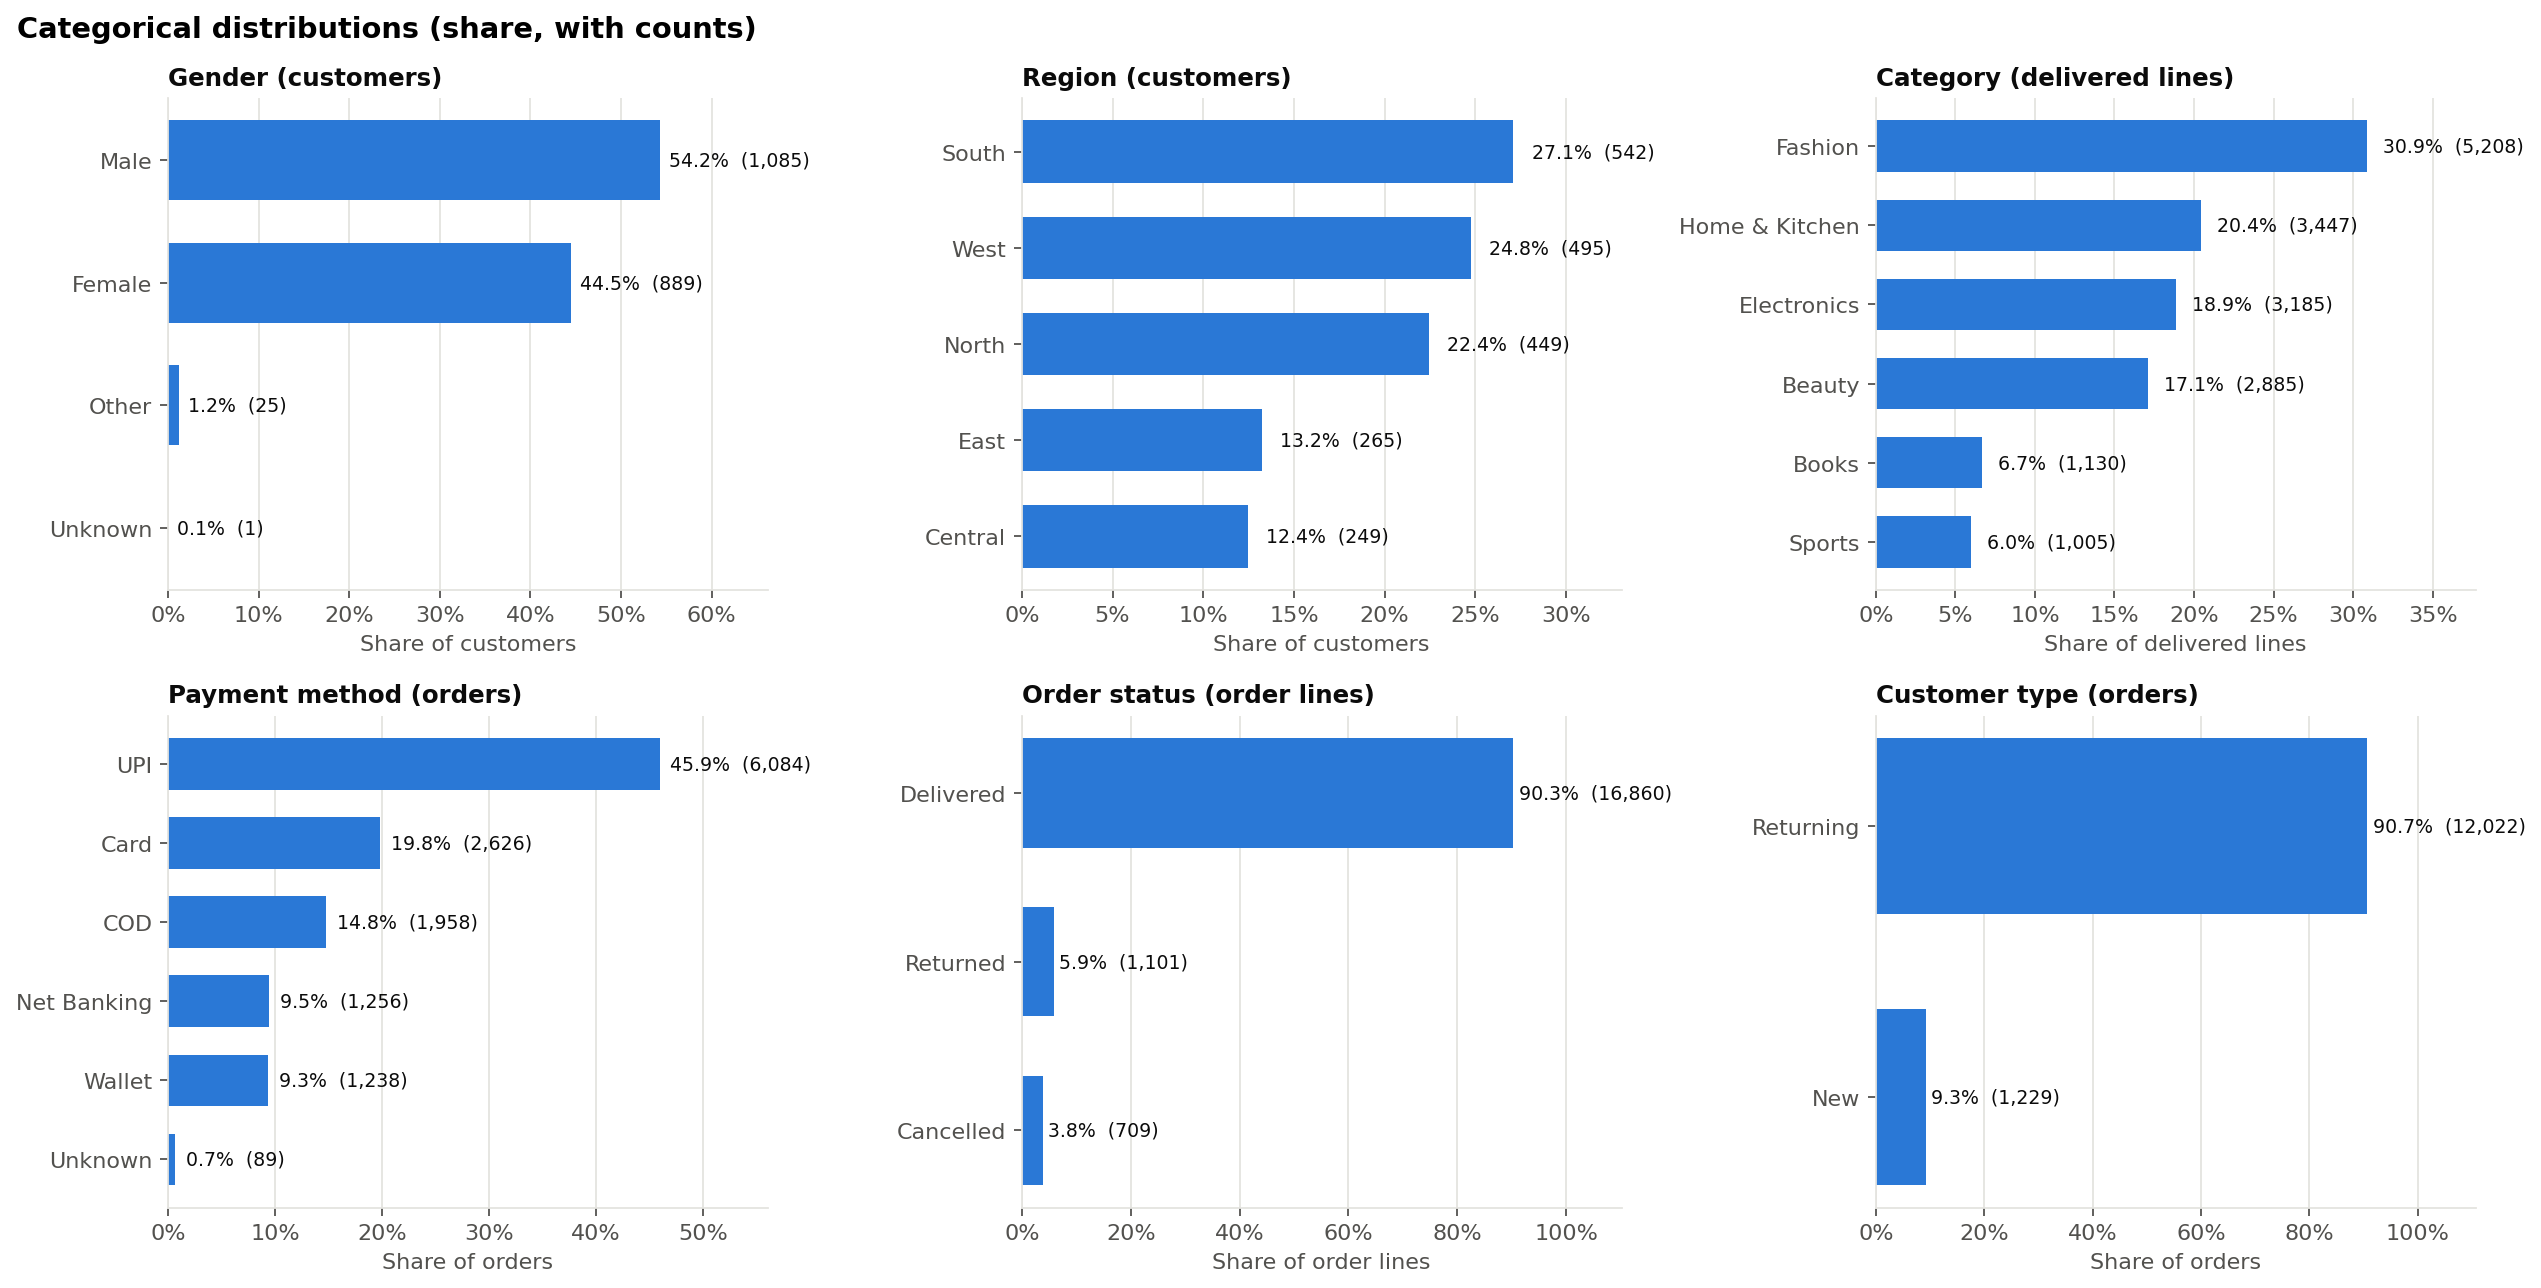

In [8]:
Image(str(FIG / "categorical_distributions.png"))

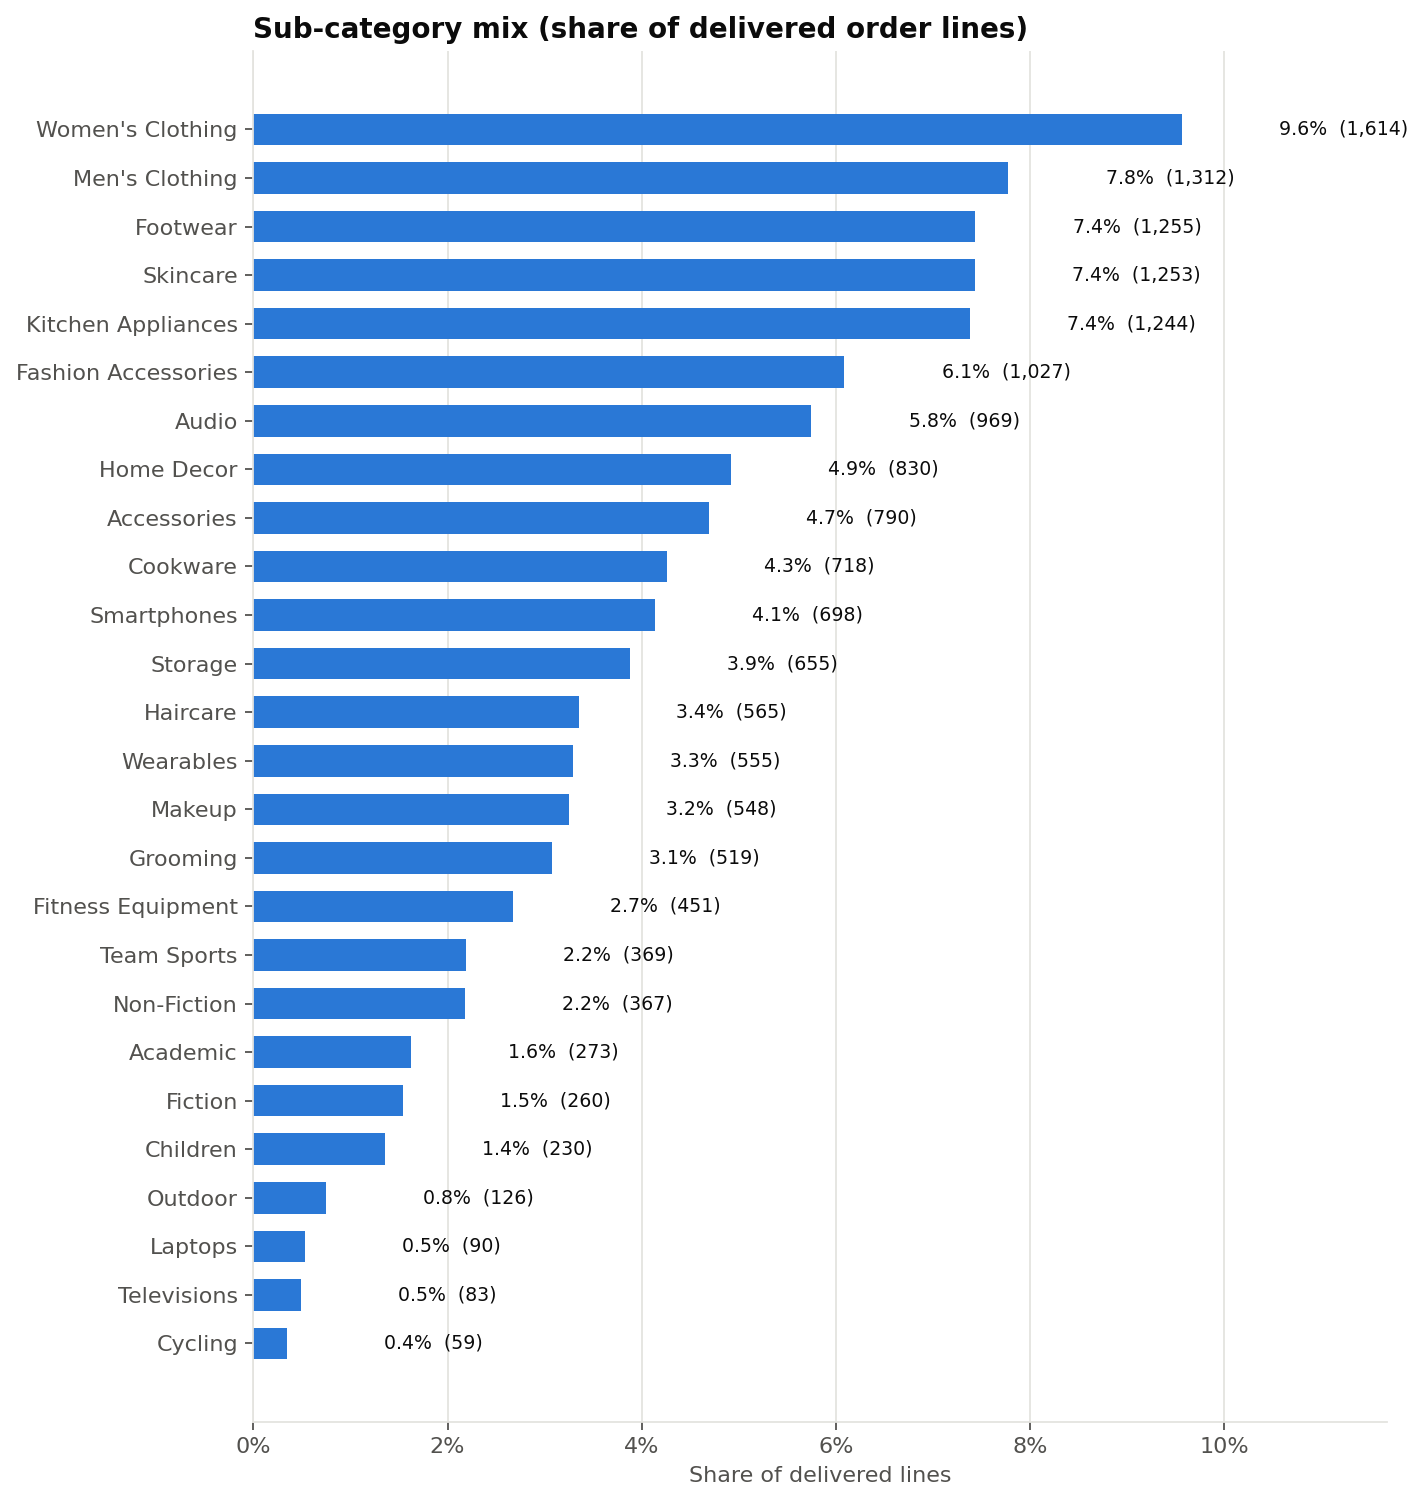

In [9]:
Image(str(FIG / "subcategory_distribution.png"))

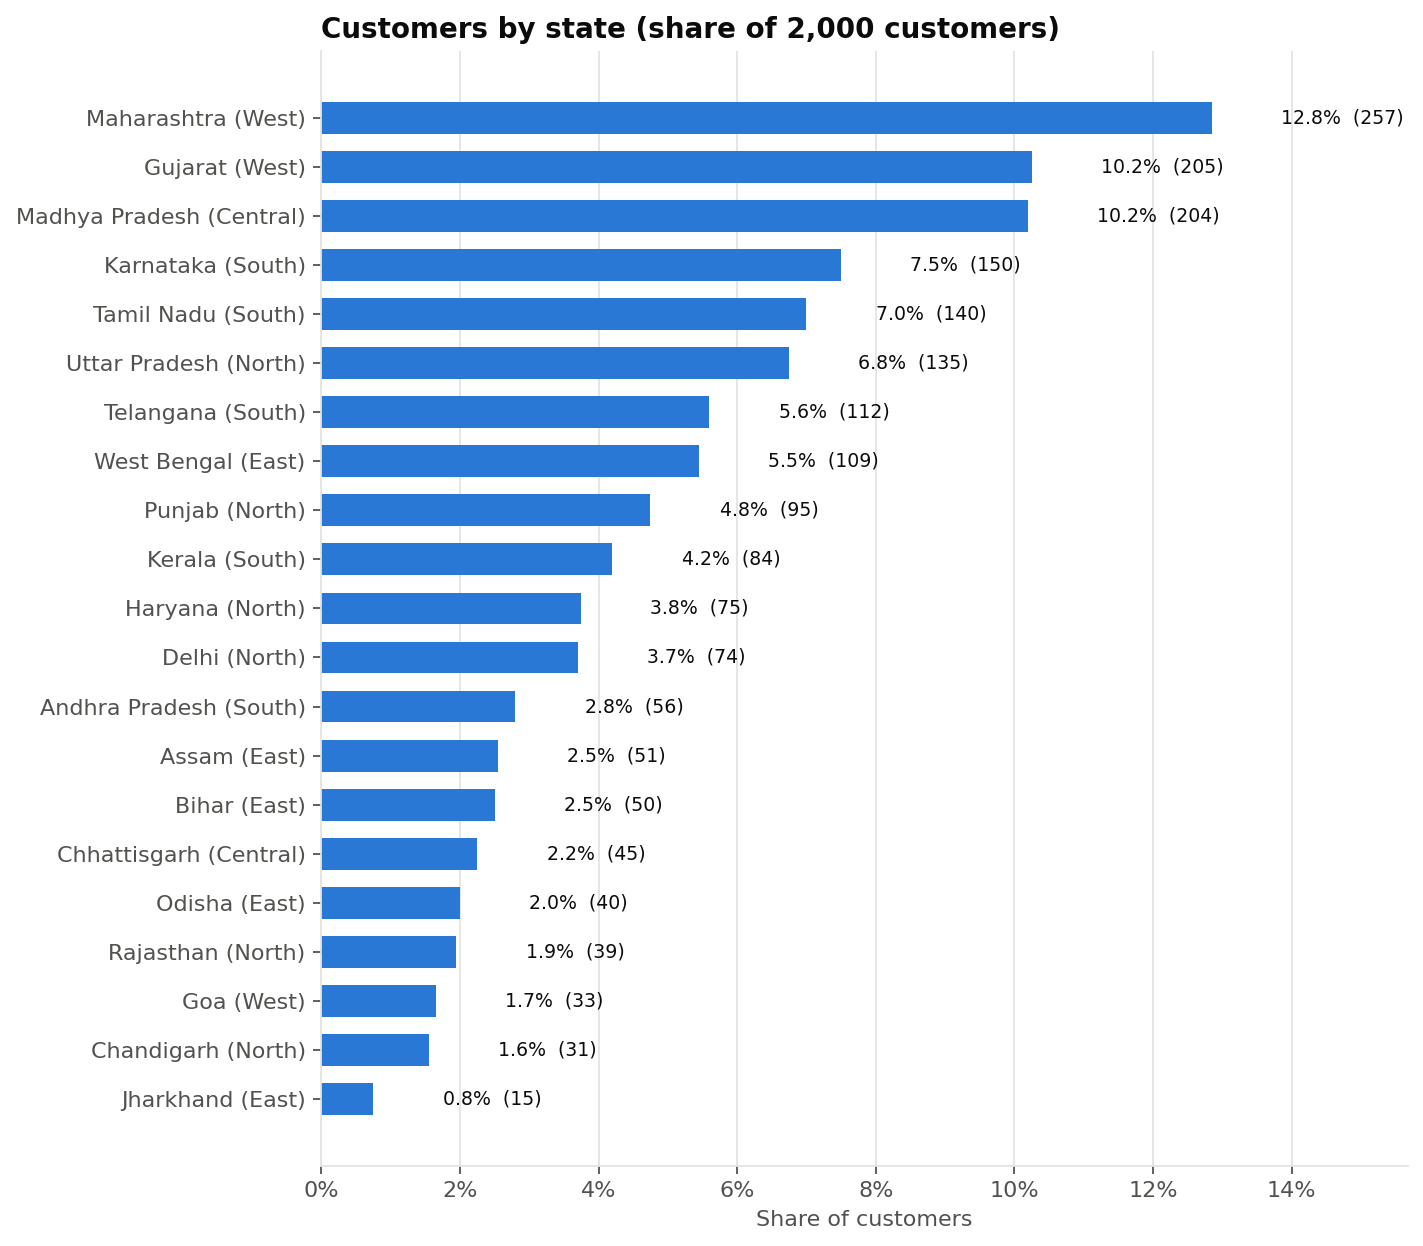

In [10]:
Image(str(FIG / "state_customer_distribution.png"))

**Observation.**
- Customers are 54% male and 44% female.
- South (27%) and West (25%) hold the most customers.
- **Fashion** has the most order lines (31%), yet it is not the largest revenue category (see Section 8).
- UPI is used for 46% of orders.
- 90% of lines were delivered.
- 91% of orders are "Returning". Many customers were already active before 2023.

**Interpretation.**
- Order-line volume and revenue tell different stories. Fashion drives traffic, while Electronics drives value.
- UPI dominance supports prepaid-first payment strategies.

## 5. Bivariate Analysis
Relationships between pairs of variables: customer revenue vs demographics, category vs region, and payment method vs outcomes. Discount and correlation are covered in Sections 10 and 11.

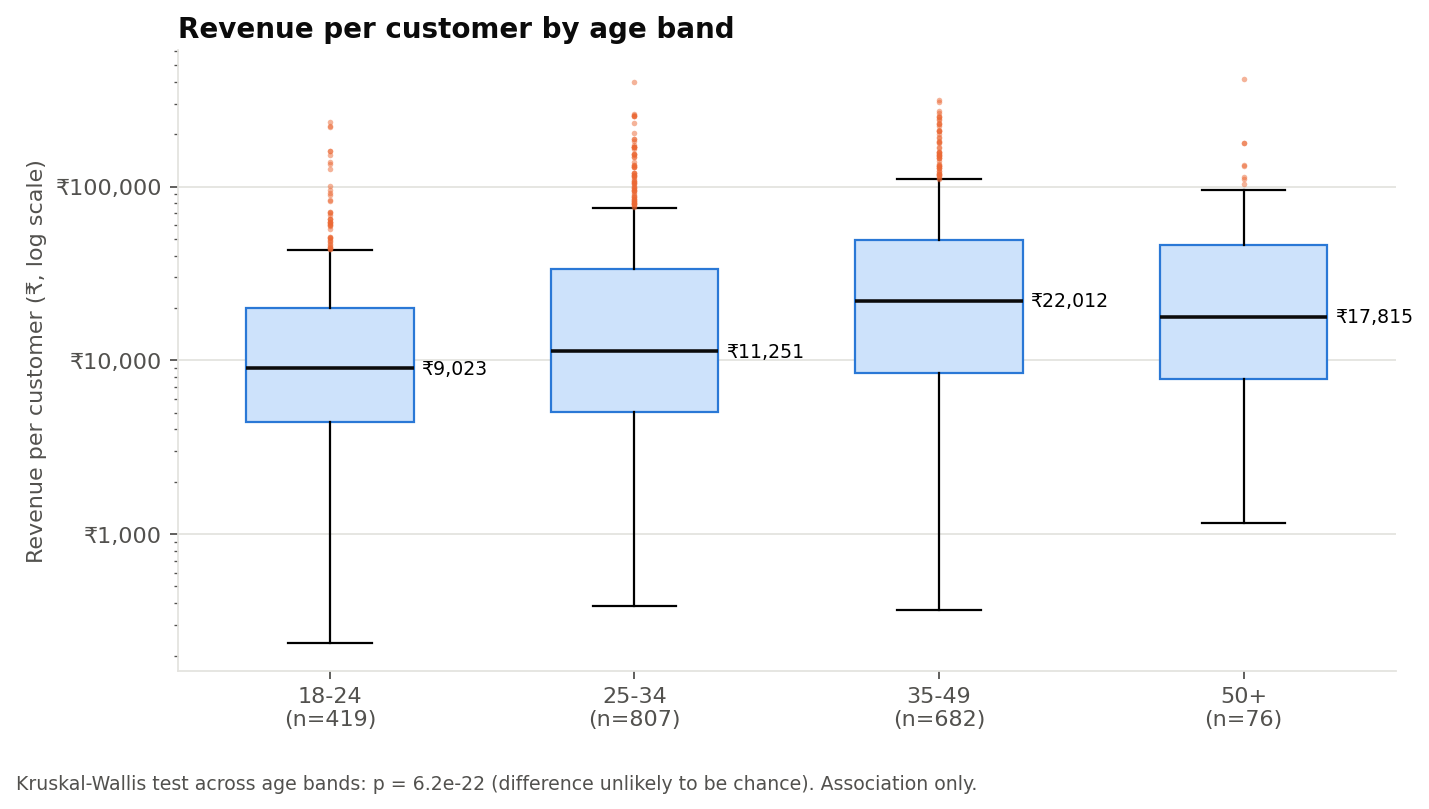

In [11]:
Image(str(FIG / "customer_revenue_by_age_band.png"))

In [12]:
R['customers']['characteristic_tests']

,Characteristic,Groups,Kruskal_H,p_value,Significant_at_5%,Highest_Median_Group,Lowest_Median_Group
0,Age_Band,4.000,101.855,0.000,True,"35-49 (₹22,012)","18-24 (₹9,023)"
1,Gender,3.000,0.424,0.809,False,"Other (₹18,816)","Male (₹13,227)"
2,Region,5.000,3.870,0.424,False,"North (₹16,263)","Central (₹11,060)"
3,Preferred_Payment,5.000,2.720,0.606,False,"COD (₹15,853)","Wallet (₹10,620)"
4,Customer_Age (continuous),NaN,NaN,0.000,True,Spearman rho = 0.228,
5,Total_Orders (behavioural),NaN,NaN,0.000,True,Spearman rho = 0.842,
6,Average_Order_Value (behavioural),NaN,NaN,0.000,True,Spearman rho = 0.808,
7,Categories_Bought (behavioural),NaN,NaN,0.000,True,Spearman rho = 0.772,
8,Average_Discount (behavioural),NaN,NaN,0.000,True,Spearman rho = -0.304,
9,Return_Rate (behavioural),NaN,NaN,0.000,True,Spearman rho = 0.182,


In [13]:
R['customers']['revenue_by_attribute']

,Attribute,Group,Customers,Median_Revenue,Mean_Revenue,Median_Orders,Median_AOV
0,Age_Band,18-24,419,"9,022.600","19,020.127",4.000,"2,685.500"
1,Age_Band,25-34,807,"11,251.000","27,558.482",4.000,"3,026.638"
2,Age_Band,35-49,682,"22,012.175","39,484.839",6.000,"3,535.296"
3,Age_Band,50+,76,"17,814.525","38,405.013",5.000,"3,308.388"
0,Gender,Female,883,"13,588.400","30,237.830",5.000,"3,037.800"
1,Gender,Male,1075,"13,227.100","30,365.211",4.000,"3,135.190"
2,Gender,Other,25,"18,816.450","28,505.514",5.000,"3,244.011"
3,Gender,Unknown,1,"1,324.800","1,324.800",1.000,"1,324.800"
0,Region,Central,248,"11,060.075","30,780.937",4.000,"2,837.944"
1,Region,East,262,"13,044.875","28,393.890",4.000,"3,213.095"


**Observation.**
- Revenue per customer differs significantly by **age band** (Kruskal-Wallis p < 0.001). The 35-49 median is ₹22,012, against ₹9,023 for 18-24.
- 35-49 customers place a median of 6 orders, against 4 for 18-24, and their median AOV is ₹3,535, against ₹2,686.
- **Gender (p = 0.81), region (p = 0.42) and preferred payment method (p = 0.61) show no significant difference.**
- Behavioural measures correlate far more strongly with revenue than demographics do: order count ρ = 0.84, AOV ρ = 0.81, number of categories bought ρ = 0.77.

**Interpretation.** *What customers do* explains revenue better than *who they are*. Age band is the only demographic worth keeping as a predictor. Gender- or region-based targeting has little statistical support in this data.

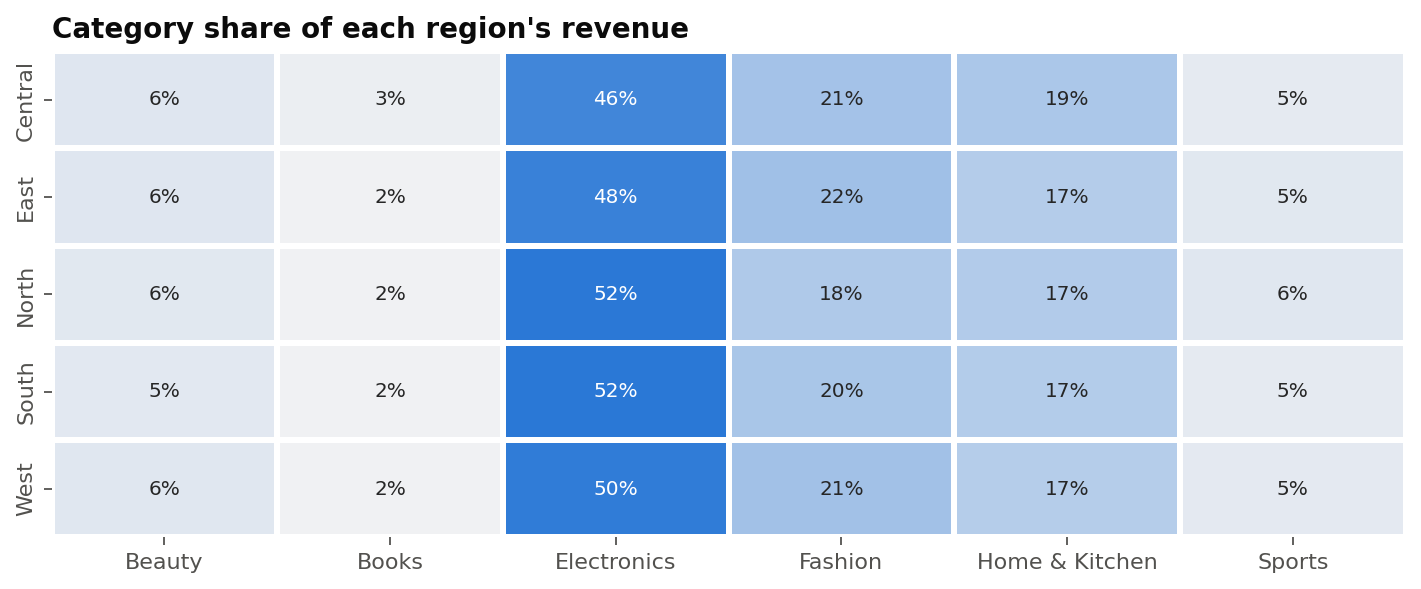

In [14]:
Image(str(FIG / "category_region_mix.png"))

**Observation.** The category mix is similar across regions: Electronics is 46-52% of each region's revenue. **Interpretation.** Regional differences in revenue come from customer count and growth rather than from different product preferences, so one national assortment is reasonable.

## 6. Time-Series Analysis
Time features (`Order_Year`, `Order_Quarter`, `Month_Number`, `Year_Month`, `Order_Week`, `Day_of_Week`) were created in Step 3.

In [15]:
R['time']['yearly']

,Order_Year,Revenue,Profit,Orders,Customers,Profit_Margin,AOV,YoY_Revenue_Growth_%
0,2023,"13,060,877.250","2,957,857.430",2811,1137,0.226,"4,646.346",NaN
1,2024,"19,769,754.900","4,557,848.190",4014,1328,0.231,"4,925.201",51.366
2,2025,"27,225,937.000","6,506,845.960",5387,1716,0.239,"5,054.007",37.715


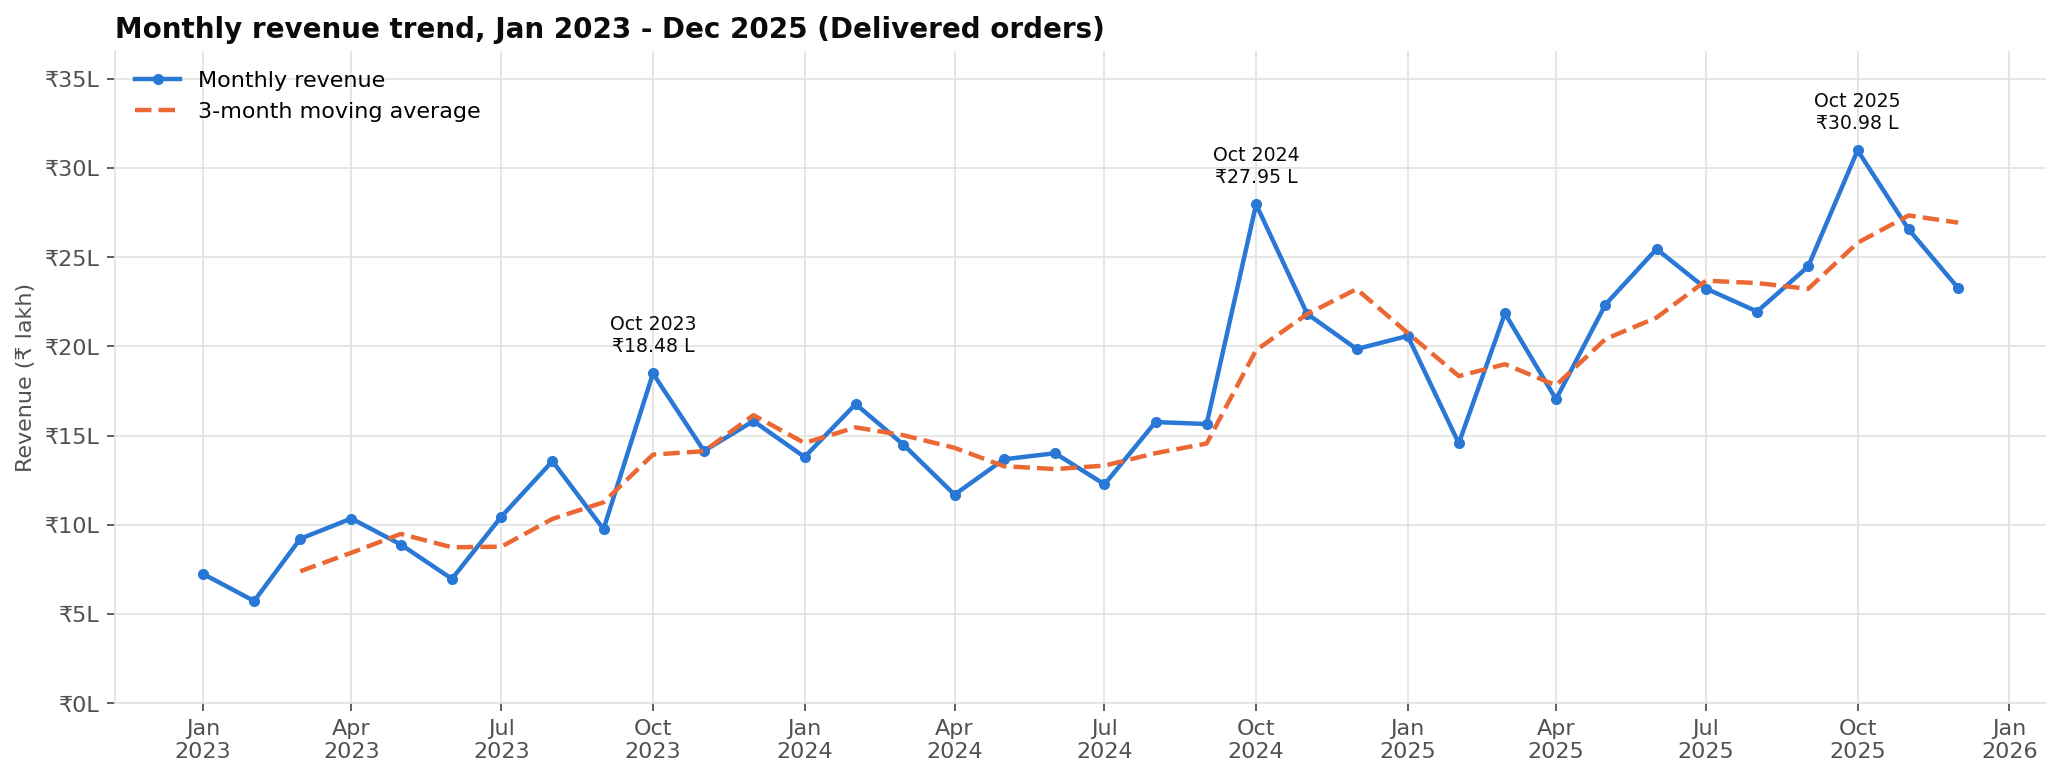

In [16]:
Image(str(FIG / "monthly_revenue_trend.png"))

In [17]:
import plotly.io as pio
pio.renderers.default = "notebook_connected"
import plotly.graph_objects as go
m = R["time"]["monthly"]
x = m["Year_Month"].dt.to_timestamp()
fig = go.Figure([go.Scatter(x=x, y=m["Revenue"], mode="lines+markers", name="Revenue", line=dict(color="#2a78d6")),
                 go.Scatter(x=x, y=m["Revenue_3M_MA"], mode="lines", name="3-month MA", line=dict(color="#eb6834", dash="dash"))])
fig.update_layout(title="Monthly revenue (interactive)", template="plotly_white", hovermode="x unified", height=420,
                  yaxis_title="Revenue (INR)")
fig.show()

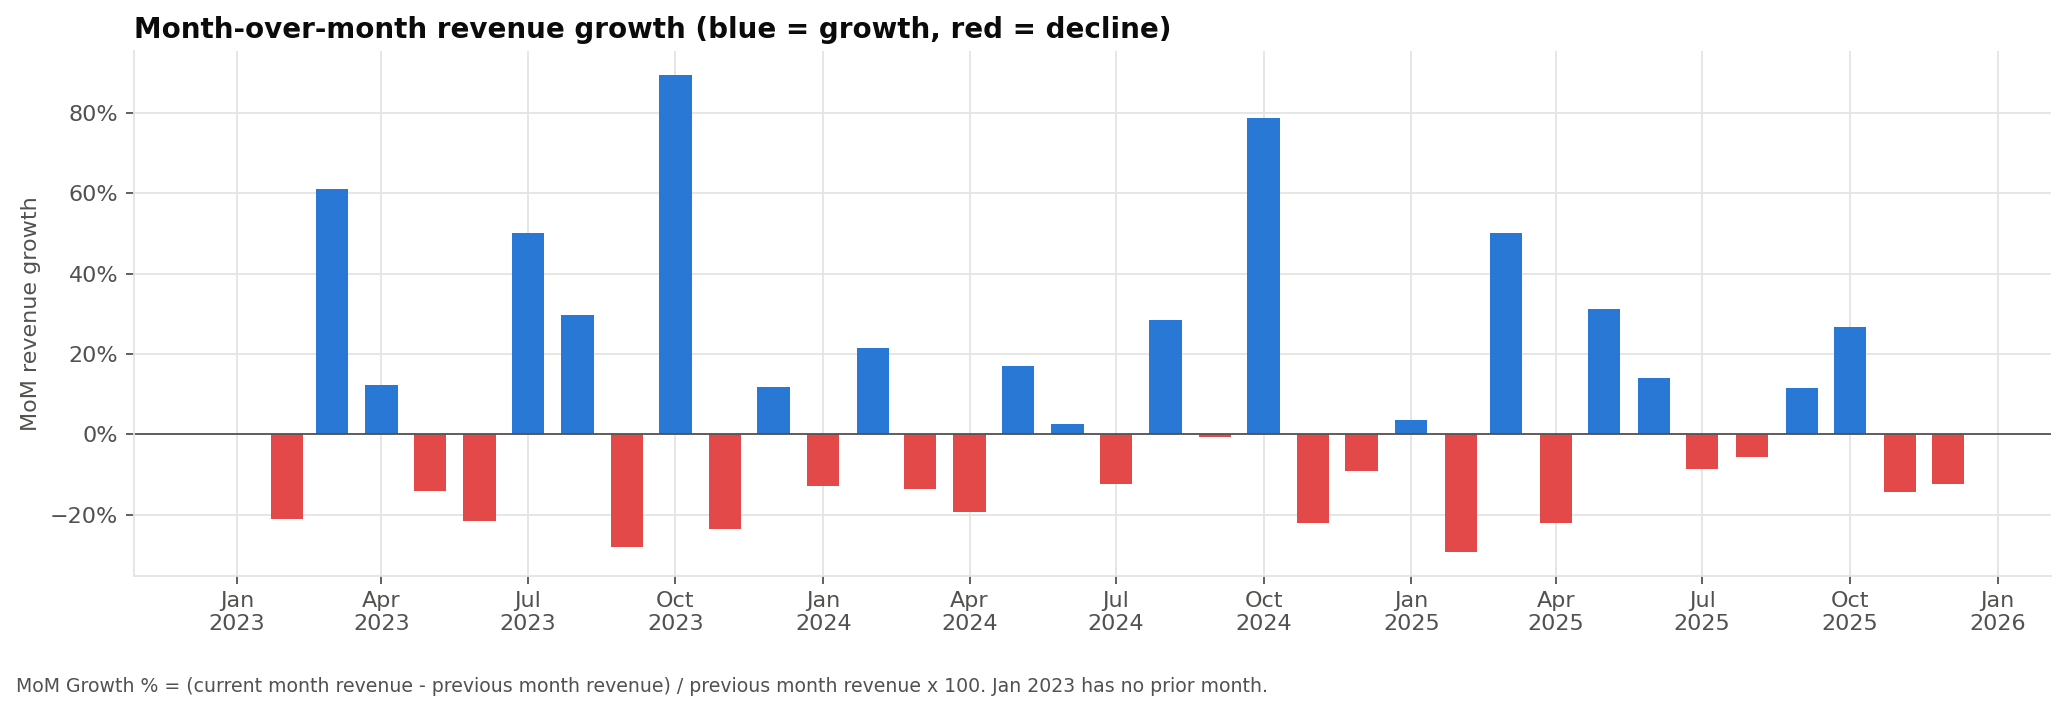

In [18]:
Image(str(FIG / "mom_revenue_growth.png"))

In [19]:
m[['Year_Month', 'Revenue', 'Profit', 'Profit_Margin', 'Orders', 'Active_Customers', 'AOV', 'MoM_Growth_%', 'YoY_Growth_%']]

,Year_Month,Revenue,Profit,Profit_Margin,Orders,Active_Customers,AOV,MoM_Growth_%,YoY_Growth_%
0,2023-01,"724,867.150","185,594.910",0.256,200,166,"3,624.336",NaN,NaN
1,2023-02,"572,756.750","185,157.630",0.323,147,139,"3,896.304",-20.985,NaN
2,2023-03,"921,616.850","195,919.880",0.213,150,137,"6,144.112",60.909,NaN
3,2023-04,"1,035,094.850","234,182.520",0.226,176,158,"5,881.221",12.313,NaN
4,2023-05,"889,389.700","232,084.850",0.261,192,173,"4,632.238",-14.077,NaN
5,2023-06,"696,767.450","185,120.390",0.266,166,147,"4,197.394",-21.658,NaN
6,2023-07,"1,045,739.000","260,600.150",0.249,247,216,"4,233.761",50.084,NaN
7,2023-08,"1,356,304.800","261,060.780",0.192,252,215,"5,382.162",29.698,NaN
8,2023-09,"975,785.450","270,211.300",0.277,229,202,"4,261.072",-28.056,NaN
9,2023-10,"1,847,708.750","311,449.510",0.169,376,308,"4,914.119",89.356,NaN


**Observation.**
- Revenue grew from ₹1.31 Cr (2023) to ₹1.98 Cr (2024, **+51.4%**) and ₹2.72 Cr (2025, **+37.7%**).
- Monthly revenue rose from ₹7.2 L (Jan 2023) to a peak of ₹31.0 L (Oct 2025).
- The path is not smooth. There is a flat patch from April to July 2024, and MoM growth ranges from −29% to +89%.

**Interpretation.** The business is growing, but **growth is slowing**. The large month-to-month swings mean MoM growth alone is a noisy KPI. The 3-month moving average and year-on-year comparison are more reliable for management reporting.

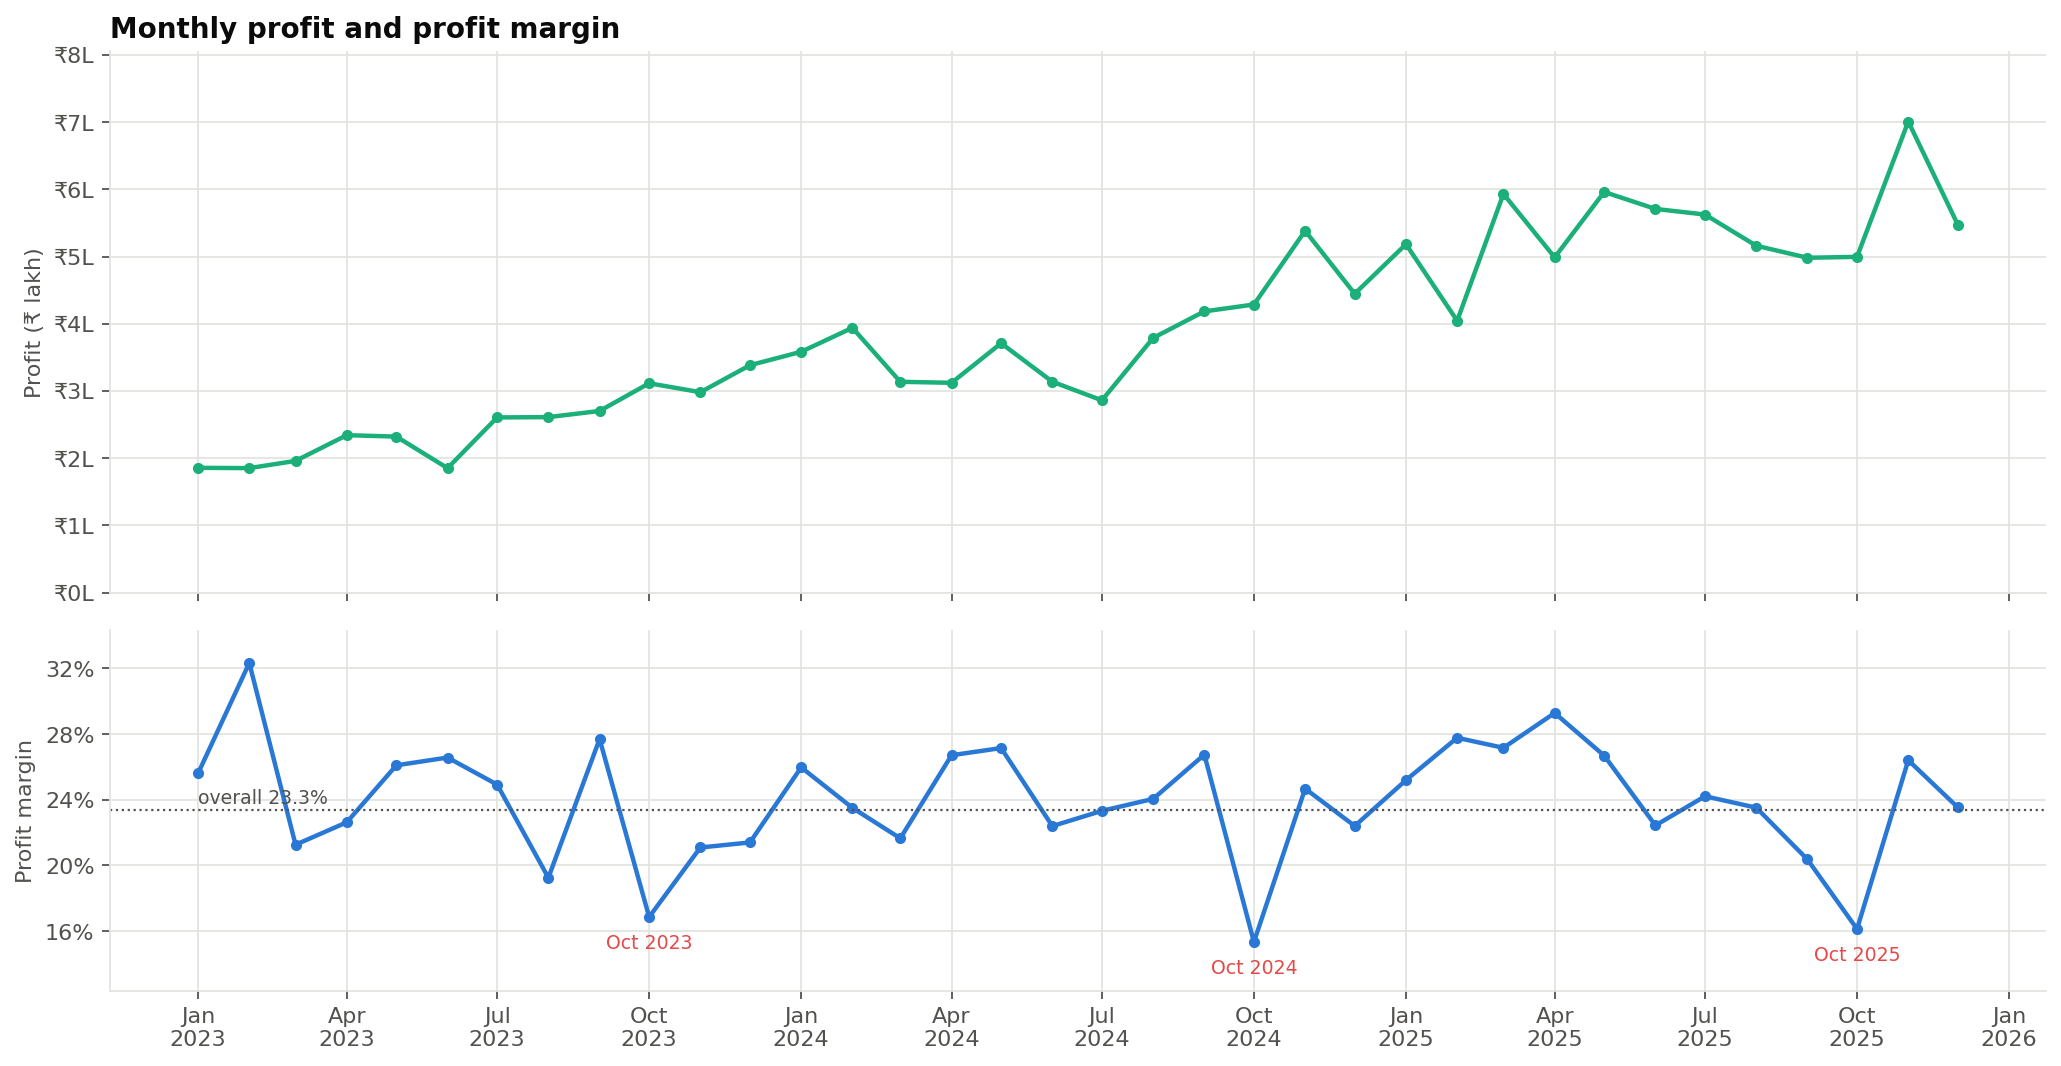

In [20]:
Image(str(FIG / "monthly_profit_trend.png"))

**Observation.** Profit follows revenue upward. **Margin, however, drops to its lowest level every October**: 16.9% in 2023, 15.3% in 2024 and 16.1% in 2025, against 23.3% overall.

**Interpretation.** The festive peak is bought partly with discounts on thin-margin Electronics. Revenue and profit peaks do not coincide: November, not October, was the most profitable month in 2024 and 2025.

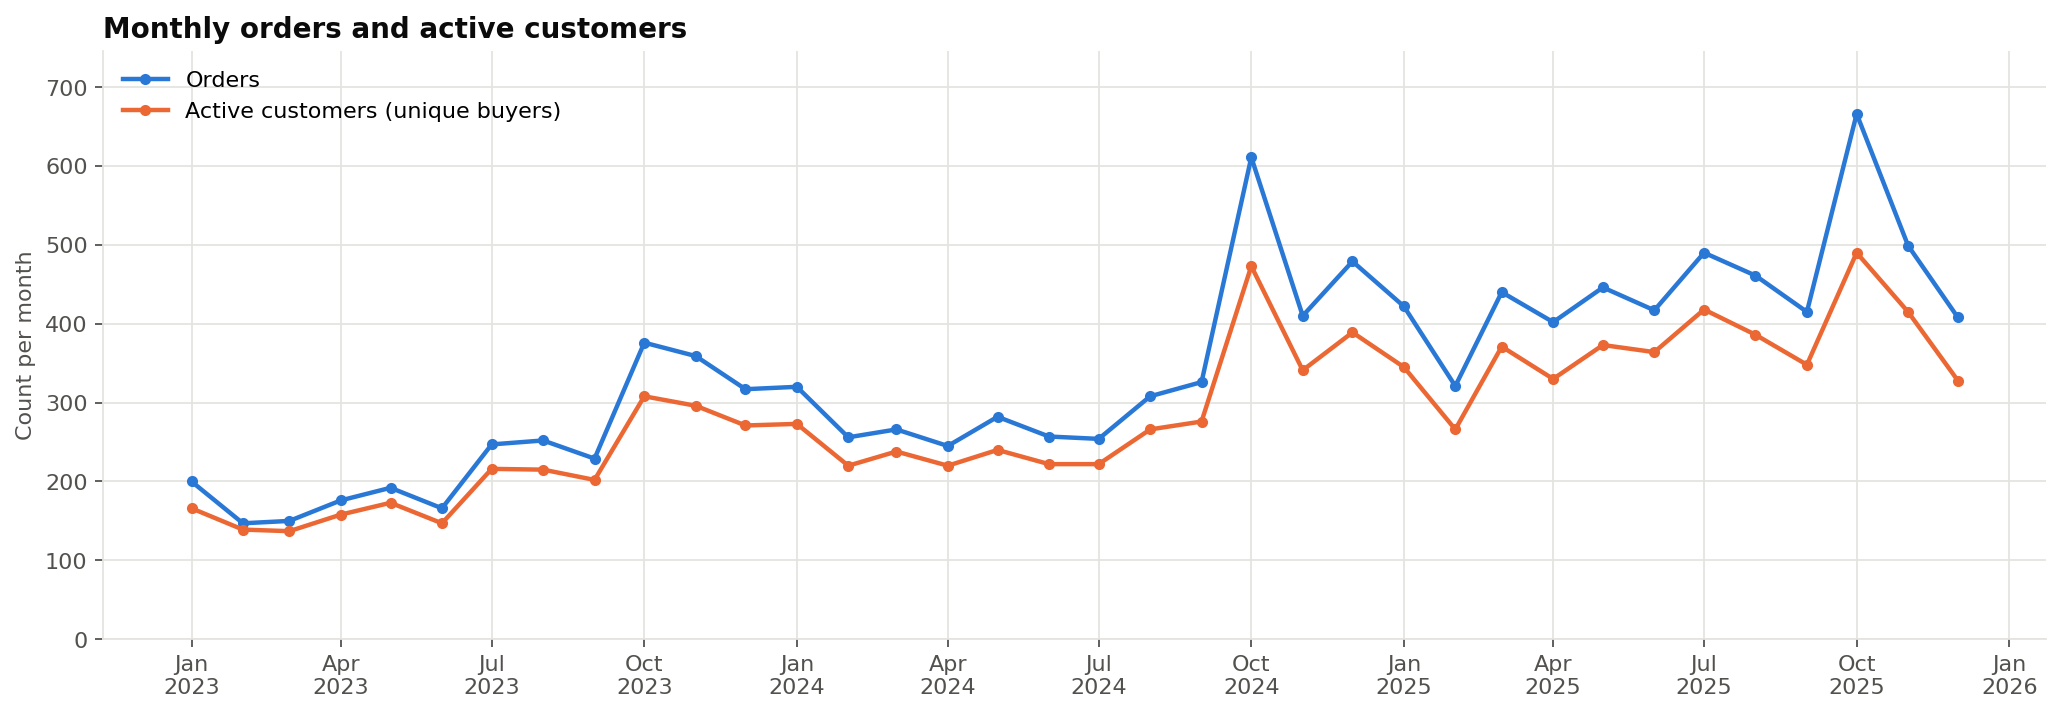

In [21]:
Image(str(FIG / "monthly_orders_customers.png"))

**Observation.** Orders and active customers move together, with the same October spikes. Monthly active buyers rose from 137-308 per month in 2023 to 266-490 in 2025. **Interpretation.** Growth comes mainly from more active customers, not from larger orders: AOV stays around ₹4,600 to ₹5,100 each year.

### 6.1 Seasonality

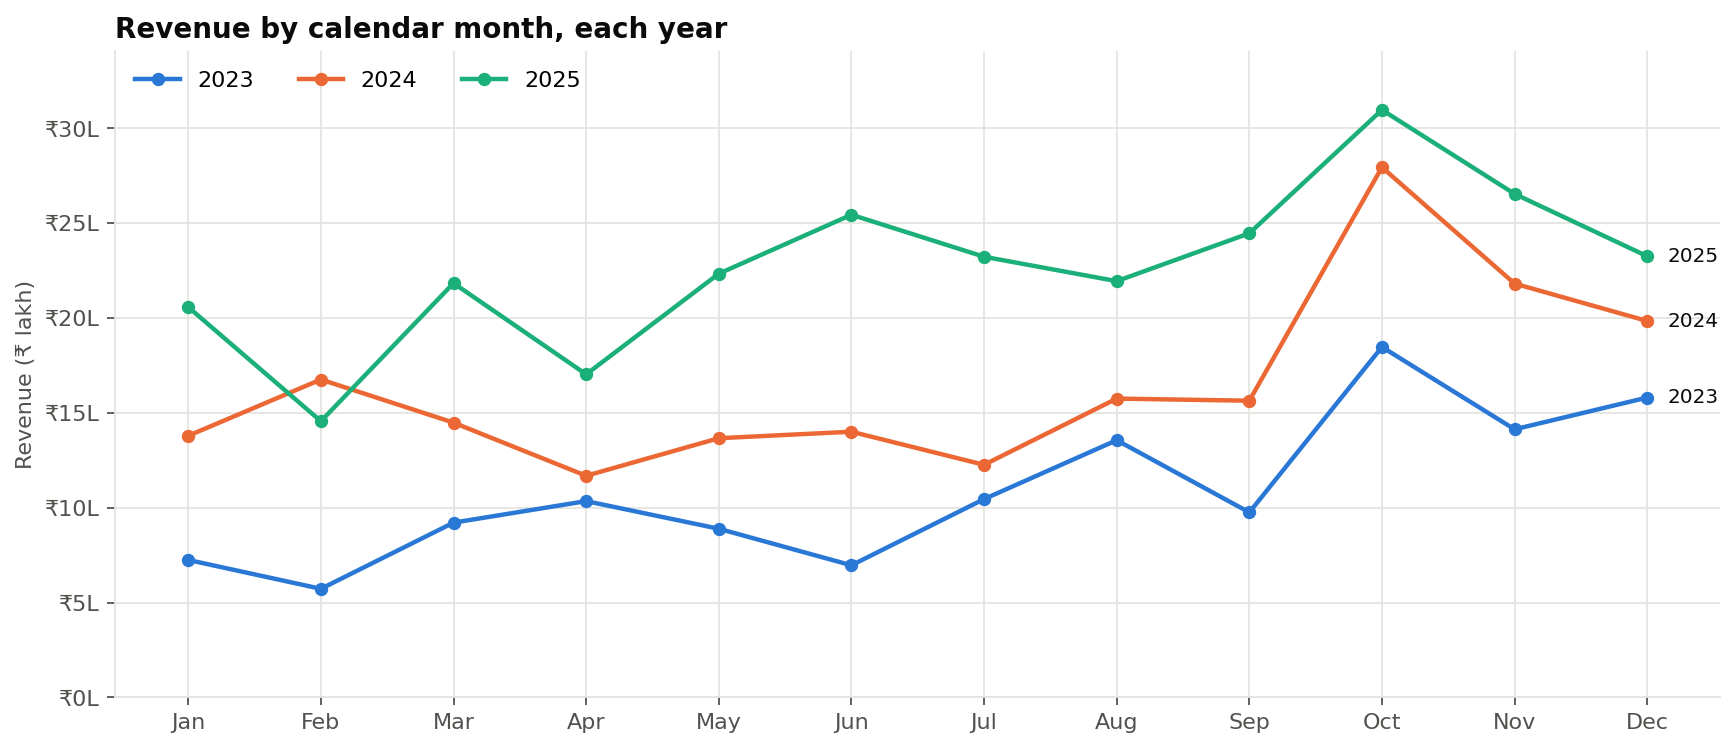

In [22]:
Image(str(FIG / "seasonality_by_year.png"))

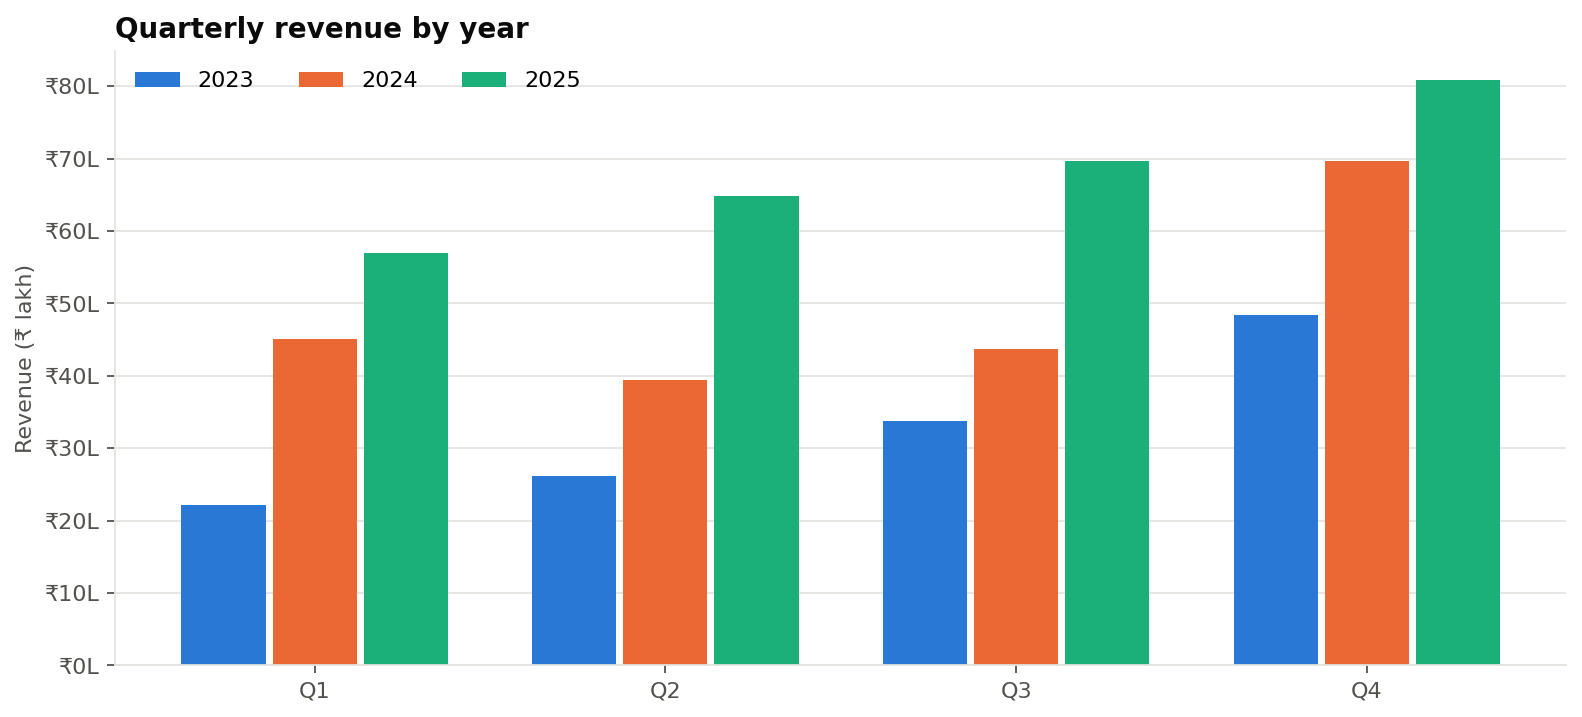

In [23]:
Image(str(FIG / "quarterly_revenue.png"))

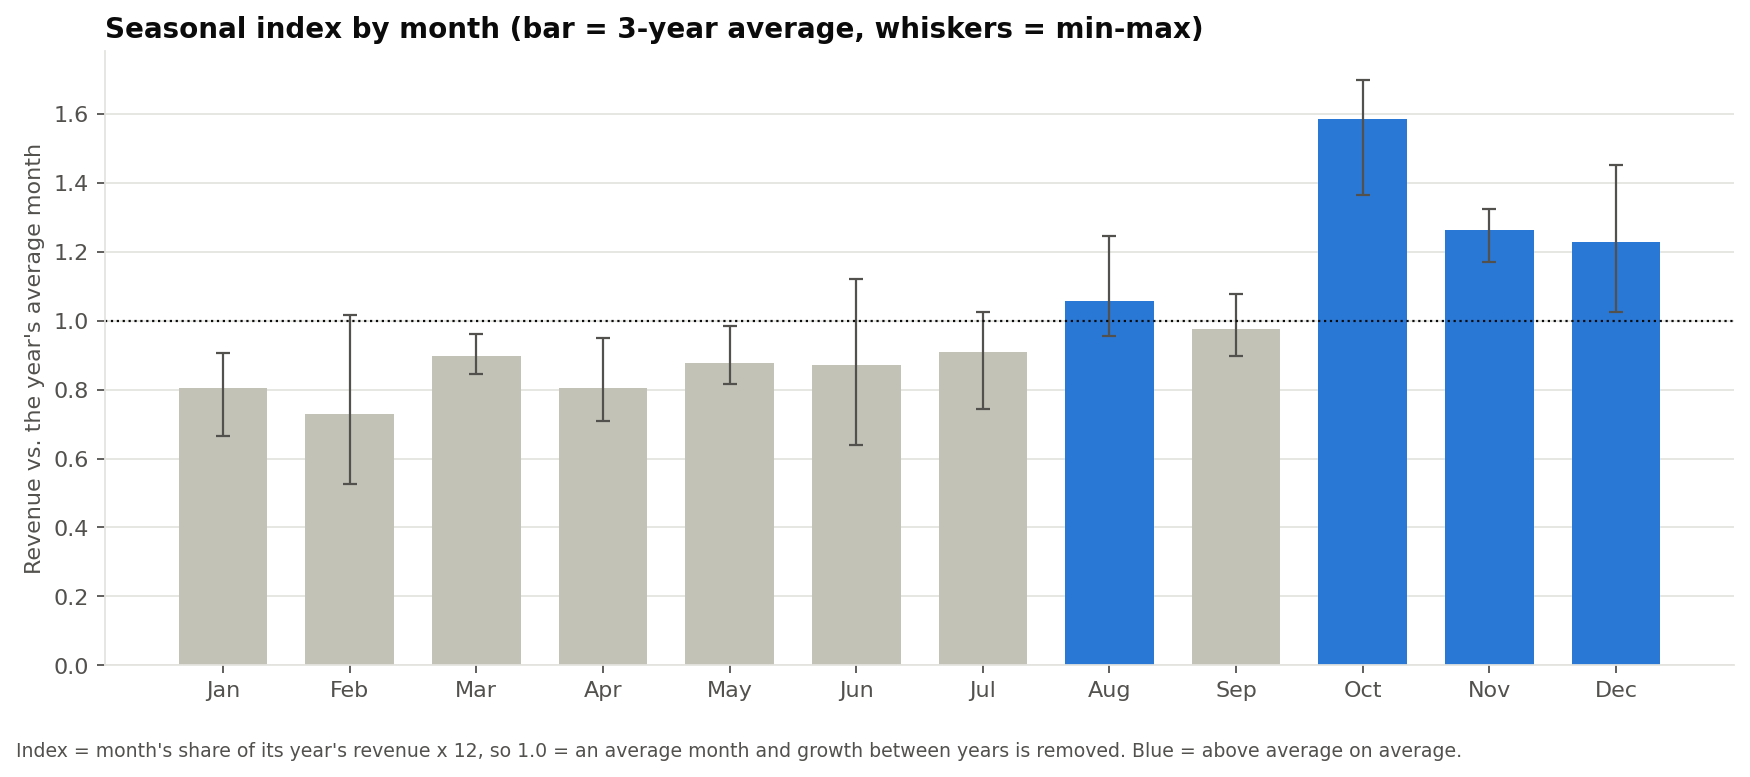

In [24]:
Image(str(FIG / "seasonal_index.png"))

In [25]:
display(R['time']['seasonal_index']); R['time']['festive']

,Month,Month_Name,Avg_Index,Min_Index,Max_Index,Years_Above_Avg,Avg_Revenue,Avg_Profit,Avg_Ratio_to_Trend,Ratio_Obs
0,1,Jan,0.804,0.666,0.907,0,"1,387,528.933","354,101.247",1.007,2
1,2,Feb,0.729,0.526,1.017,1,"1,235,124.583","327,868.233",0.944,2
2,3,Mar,0.896,0.847,0.963,0,"1,518,211.650","367,594.080",1.011,2
3,4,Apr,0.804,0.709,0.951,0,"1,302,433.783","348,375.503",0.776,2
4,5,May,0.877,0.817,0.985,0,"1,496,803.017","399,746.027",0.935,2
5,6,Jun,0.871,0.640,1.122,1,"1,547,584.200","356,589.447",0.994,2
6,7,Jul,0.910,0.744,1.024,1,"1,531,951.200","369,734.630",0.835,2
7,8,Aug,1.057,0.956,1.246,1,"1,708,944.533","385,379.117",1.035,2
8,9,Sep,0.975,0.897,1.079,1,"1,662,468.333","395,625.267",0.844,2
9,10,Oct,1.587,1.365,1.698,3,"2,580,255.167","413,225.473",1.509,2


,Year,Oct_Nov_Share,Peak_Month,Peak_Revenue,Lowest_Month,Lowest_Revenue
0,2023,0.250,Oct,"1,847,708.750",Feb,"572,756.750"
1,2024,0.252,Oct,"2,795,219.000",Apr,"1,168,649.700"
2,2025,0.211,Oct,"3,097,837.750",Feb,"1,456,402.750"


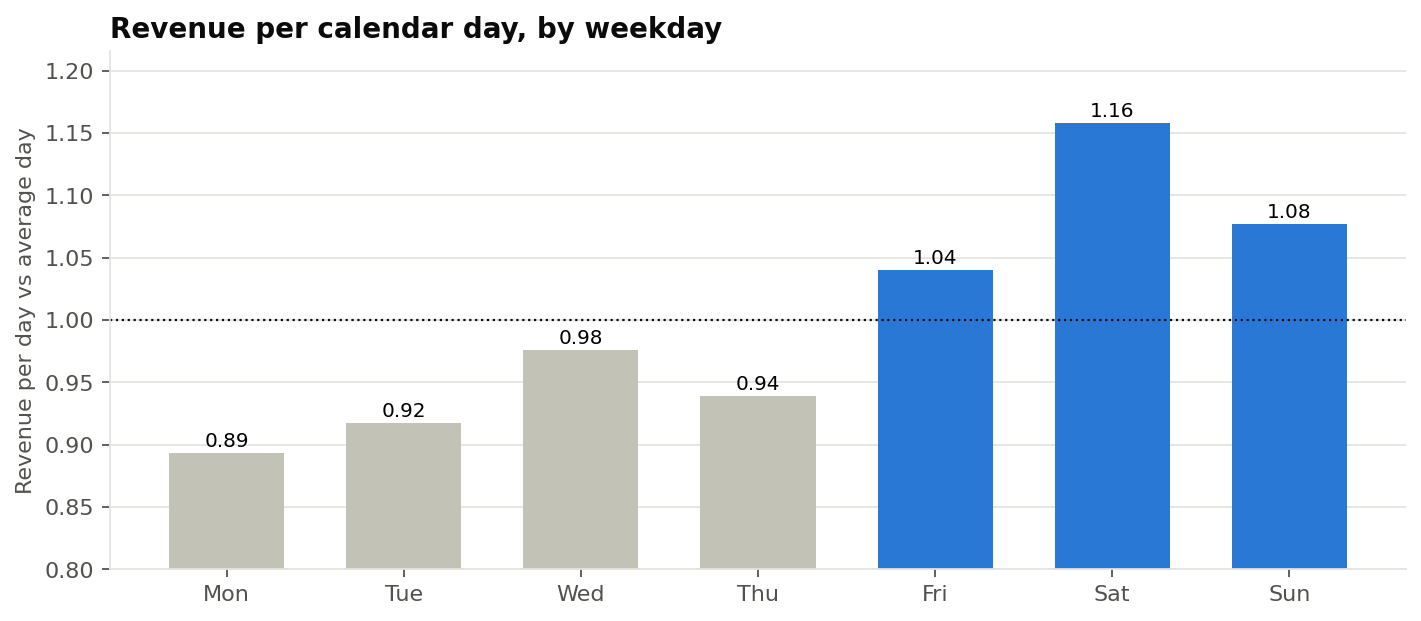

In [26]:
Image(str(FIG / "day_of_week_revenue.png"))

**Observation.**
- **October was the highest-revenue month in all three years.**
- October, November and December were each above their year's average month in every year. October averaged 1.59× an average month, or 1.51× after removing the trend with a centred 12-month moving average.
- January to July sit below average in most years.
- Q4 took 37%, 35% and 30% of annual revenue in 2023, 2024 and 2025.
- By weekday, Saturday revenue per day is 1.16× the average day, and Monday is 0.89×.

**Is this seasonality?** Yes. The Q4/October peak recurs in all three years and survives de-trending. Other monthly differences, such as February being low, are **not consistent enough** to be called seasonal: February was above average in 2024.

**Interpretation.** Plan inventory, staff and marketing around the festive quarter. The forecasting model in Step 9 must include a seasonal component. Diwali's moving date (October or November) is a known complication for such models.

## 7. Customer Analysis

In [27]:
R['customers']['customer_summary'].head(10)

,Customer_ID,Customer_Name,Customer_Age,Age_Band,Gender,City,State,Region,Total_Orders,Total_Quantity,Total_Revenue,Total_Profit,Average_Discount,First_Purchase_Date,Last_Purchase_Date,Categories_Bought,Lines_All,Returned_Lines,Preferred_Payment,Average_Order_Value,Return_Rate,Revenue_Rank
118,CUST-1128,Fatima Pillai,50,50+,Female,Hyderabad,Telangana,South,27.000,66.000,"417,800.450","51,829.470",0.089,2023-01-20,2025-12-19,6.000,53,2,Net Banking,"15,474.091",0.038,1
300,CUST-1724,Sandeep Gill,31,25-34,Male,Hyderabad,Telangana,South,28.000,53.000,"400,151.700","67,098.230",0.068,2023-02-28,2025-12-02,5.000,45,1,Card,"14,291.132",0.022,2
50,CUST-0669,Madhuri Sen,41,35-49,Female,New Delhi,Delhi,North,16.000,43.000,"314,818.650","36,558.330",0.111,2023-01-08,2025-12-23,6.000,33,1,UPI,"19,676.166",0.030,3
110,CUST-0908,Aditya Malhotra,35,35-49,Male,Bhopal,Madhya Pradesh,Central,26.000,60.000,"307,090.050","58,919.910",0.100,2023-02-10,2025-12-03,6.000,44,1,UPI,"11,811.156",0.023,4
172,CUST-1172,Nikhil Rao,43,35-49,Male,Thiruvananthapuram,Kerala,South,25.000,60.000,"272,866.600","45,823.360",0.094,2023-01-29,2025-12-07,6.000,52,3,UPI,"10,914.664",0.058,5
216,CUST-0941,Arnab Panda,39,35-49,Male,Chandigarh,Chandigarh,North,27.000,49.000,"263,670.350","50,340.990",0.090,2023-02-08,2025-12-19,6.000,44,4,Card,"9,765.569",0.091,6
817,CUST-1969,Urvashi Khanna,34,25-34,Female,Gurugram,Haryana,North,25.000,52.000,"261,877.000","42,321.900",0.102,2023-08-27,2025-11-25,6.000,44,2,UPI,"10,475.080",0.045,7
1146,CUST-1044,Gurpreet Saikia,34,25-34,Male,Amritsar,Punjab,North,29.000,53.000,"258,231.300","39,819.880",0.114,2023-12-22,2025-12-15,6.000,43,2,UPI,"8,904.528",0.047,8
155,CUST-1416,Moumita Chauhan,27,25-34,Female,Ahmedabad,Gujarat,West,22.000,43.000,"255,399.200","26,676.390",0.083,2023-01-25,2025-12-06,6.000,35,2,Card,"11,609.055",0.057,9
569,CUST-1489,Yash Iyer,39,35-49,Male,Coimbatore,Tamil Nadu,South,28.000,55.000,"255,128.000","49,175.910",0.086,2023-05-24,2025-12-17,6.000,46,2,UPI,"9,111.714",0.043,10


### 7.1 Top customers

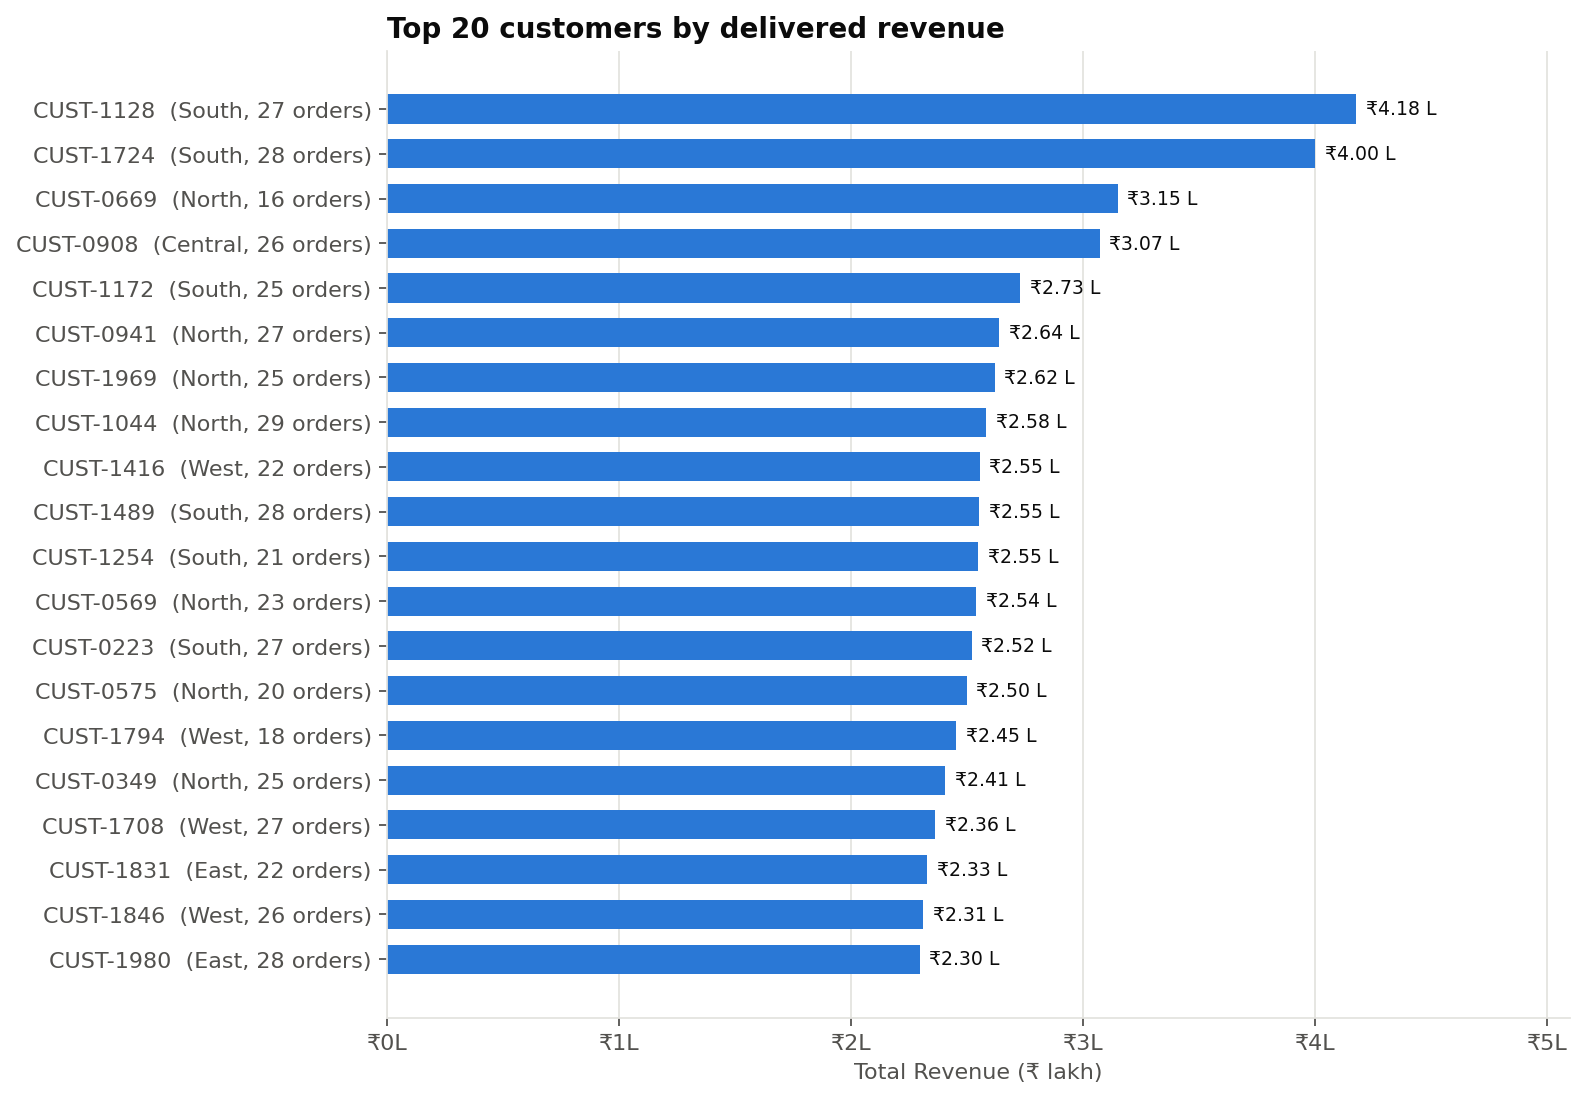

In [28]:
Image(str(FIG / "top_customers_revenue.png"))

In [29]:
R['customers']['top_customers_profit'].head(10)

,Customer_ID,Customer_Name,Region,Total_Orders,Total_Revenue,Total_Profit,Average_Order_Value,Last_Purchase_Date
329,CUST-0473,Vikram Gill,Central,28.000,"208,319.200","67,797.590","7,439.971",2025-12-07
300,CUST-1724,Sandeep Gill,South,28.000,"400,151.700","67,098.230","14,291.132",2025-12-02
110,CUST-0908,Aditya Malhotra,Central,26.000,"307,090.050","58,919.910","11,811.156",2025-12-03
472,CUST-1980,Subhajit Iyengar,East,28.000,"229,505.400","53,110.280","8,196.621",2025-12-17
1290,CUST-1708,Karthik Pillai,West,27.000,"236,155.200","51,961.810","8,746.489",2025-12-03
118,CUST-1128,Fatima Pillai,South,27.000,"417,800.450","51,829.470","15,474.091",2025-12-19
216,CUST-0941,Arnab Panda,North,27.000,"263,670.350","50,340.990","9,765.569",2025-12-19
569,CUST-1489,Yash Iyer,South,28.000,"255,128.000","49,175.910","9,111.714",2025-12-17
1185,CUST-0018,Gaurav Fernandes,South,24.000,"210,470.500","47,678.020","8,769.604",2025-12-08
285,CUST-1663,Suresh Kulkarni,Central,22.000,"165,669.400","47,322.610","7,530.427",2025-12-19


**Observation.** The top 20 customers each generated ₹2.3 L to ₹4.2 L over three years, with 16-29 orders each. All were still active in November or December 2025. The profit ranking differs somewhat from the revenue ranking, because customers who buy premium Electronics earn thinner margins.

**Interpretation.** The highest-value customers are frequent, current buyers. Step 5 (RFM) should confirm that they are "Champions" and put their retention first.

### 7.2 Purchase frequency and revenue distribution

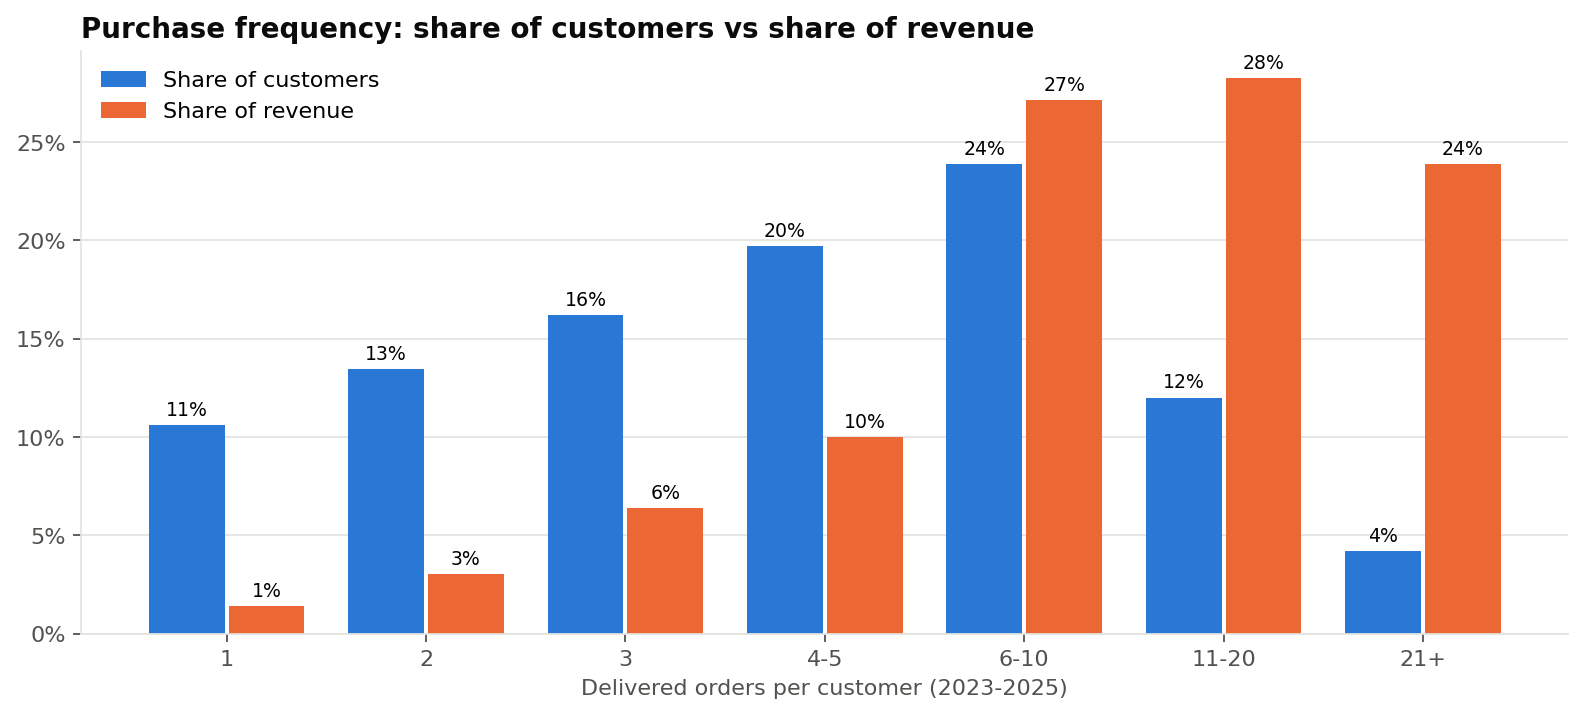

In [30]:
Image(str(FIG / "purchase_frequency.png"))

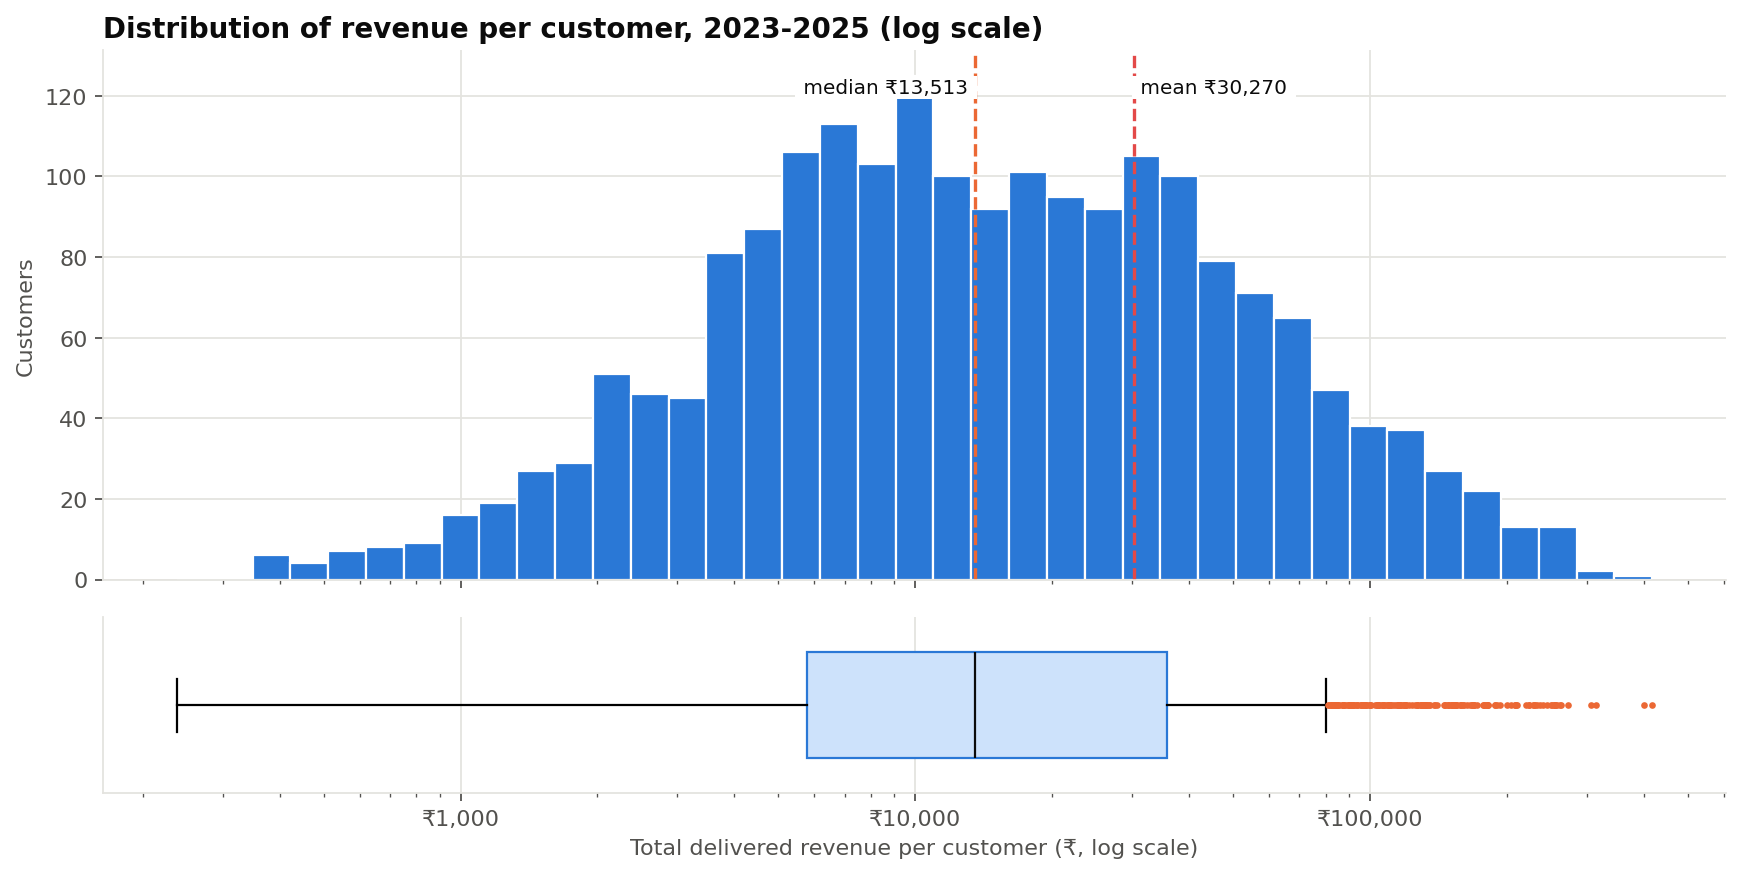

In [31]:
Image(str(FIG / "customer_revenue_distribution.png"))

In [32]:
R['customers']['distribution_stats']

,Metric,Value
0,Purchasing customers,"1,984.000"
1,Mean revenue per customer,"30,270.448"
2,Median revenue per customer,"13,513.325"
3,Mean / median ratio,2.240
4,Skewness of customer revenue,3.209
5,Gini coefficient of customer revenue,0.611
6,Median orders per customer,4.000
7,Mean orders per customer,6.155
8,Share of customers with 1 order,0.106
9,Customers with no delivered order,16.000


### 7.3 Revenue concentration

In [33]:
R['customers']['revenue_concentration']

,Customer_Group,Customers,Revenue,Share_of_Revenue
0,Top 1%,20,"5,432,938.750",0.090
1,Top 5%,100,"18,046,041.250",0.300
2,Top 10%,199,"27,333,640.500",0.455
3,Top 20%,397,"38,636,236.250",0.643
4,Top 50%,992,"54,024,698.300",0.900


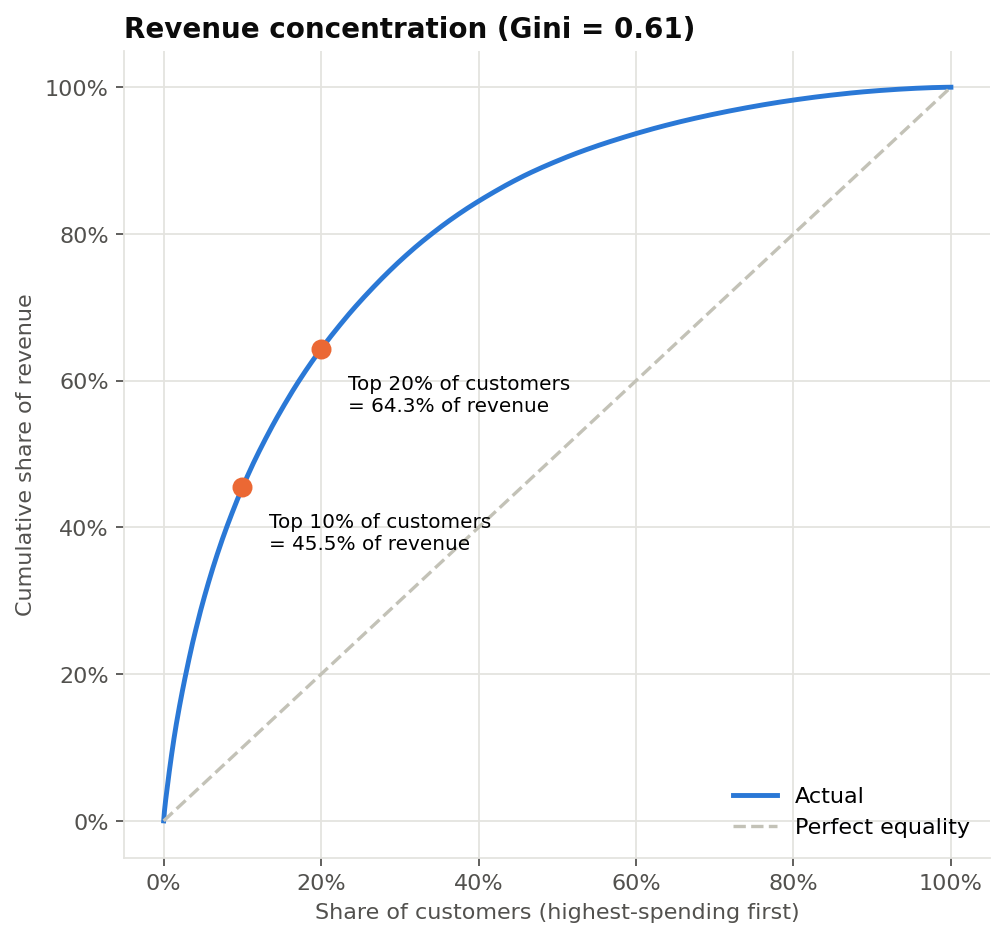

In [34]:
Image(str(FIG / "revenue_concentration_curve.png"))

In [35]:
R['customers']['recency_snapshot']

,Days_Since_Last_Purchase,Customers,Revenue
0,0-30,328,"21,766,389.950"
1,31-90,520,"18,106,854.250"
2,91-180,448,"8,525,703.850"
3,181-365,422,"9,553,314.650"
4,365+,266,"2,104,306.450"


**Observation.**
- The **top 1% of customers generate 9.0% of revenue, the top 5% 30.0%, the top 10% 45.5% and the top 20% 64.3%** (Gini = 0.61).
- Customers with 11 or more orders are 16% of buyers but produce **52%** of revenue.
- 11% bought only once.
- **688 customers (34.7%) have not bought in over 180 days.**

**Interpretation.**
- Revenue follows a Pareto-like pattern. Losing a small number of top customers would hurt disproportionately.
- There is also a large pool of lapsed buyers to reactivate.
- The 2,000-customer base is large enough for these percentile shares to be meaningful (the top 1% is 20 people).
- Step 5 will turn this descriptive recency view into scored segments.

## 8. Product Analysis
### 8.1 Categories

In [36]:
R['products']['category_summary']

,Category,Units_Sold,Revenue,Cost,Profit,Average_Discount,Orders,Customers,Loss_Lines,Lines,All_Lines,Returned,Cancelled,Profit_Margin,Revenue_Share,Profit_Share,Return_Rate,Avg_Selling_Price
2,Electronics,3488,"30,090,652.550","26,824,808.860","3,265,843.690",0.084,2980,1234,219,3185,3455,143,127,0.109,0.501,0.233,0.041,"8,626.907"
3,Fashion,7154,"12,057,741.000","6,900,148.580","5,157,592.420",0.160,4701,1594,0,5208,6080,665,207,0.428,0.201,0.368,0.109,"1,685.454"
4,Home & Kitchen,4294,"10,377,382.800","7,451,151.780","2,926,231.020",0.113,3169,1228,16,3447,3734,136,151,0.282,0.173,0.209,0.036,"2,416.717"
0,Beauty,4653,"3,401,963.450","1,820,392.250","1,581,571.200",0.119,2737,1334,1,2885,3108,89,134,0.465,0.057,0.113,0.029,731.133
5,Sports,1168,"2,991,748.400","2,227,007.410","764,740.990",0.116,981,683,12,1005,1081,42,34,0.256,0.050,0.055,0.039,"2,561.428"
1,Books,2015,"1,137,080.950","810,508.690","326,572.260",0.088,1101,791,1,1130,1212,26,56,0.287,0.019,0.023,0.021,564.308


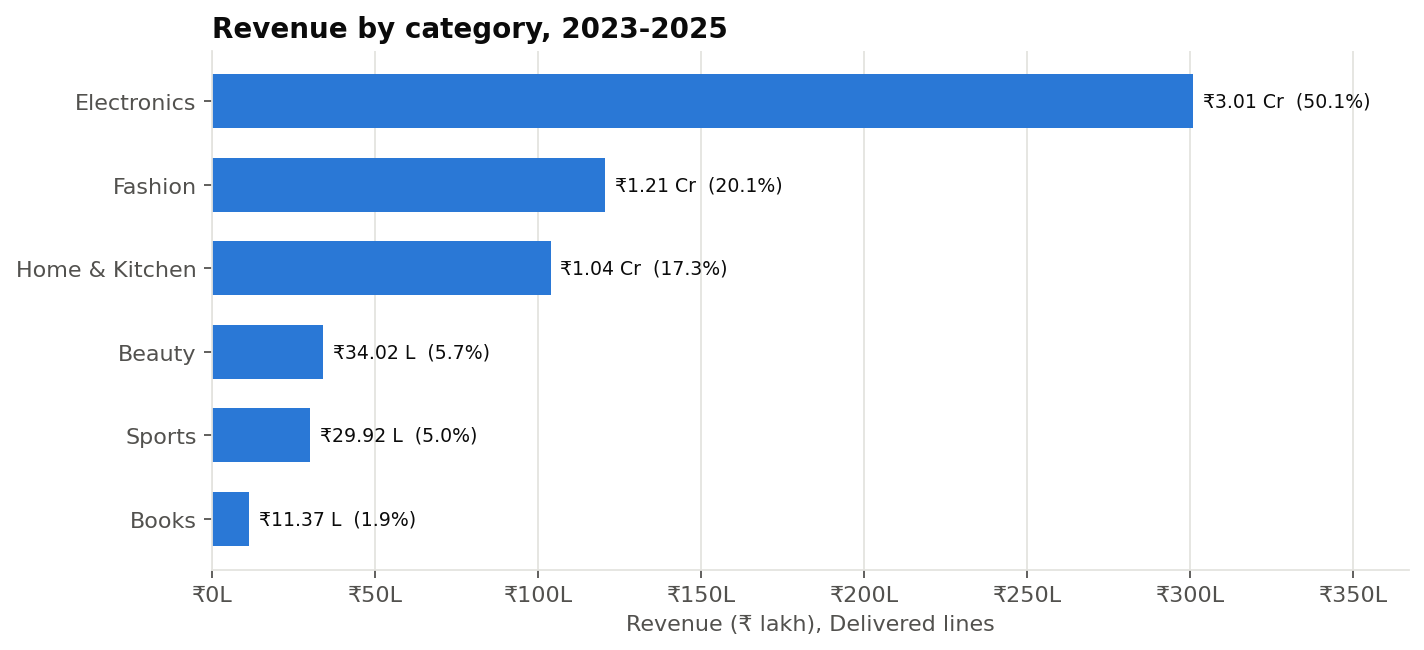

In [37]:
Image(str(FIG / "category_revenue.png"))

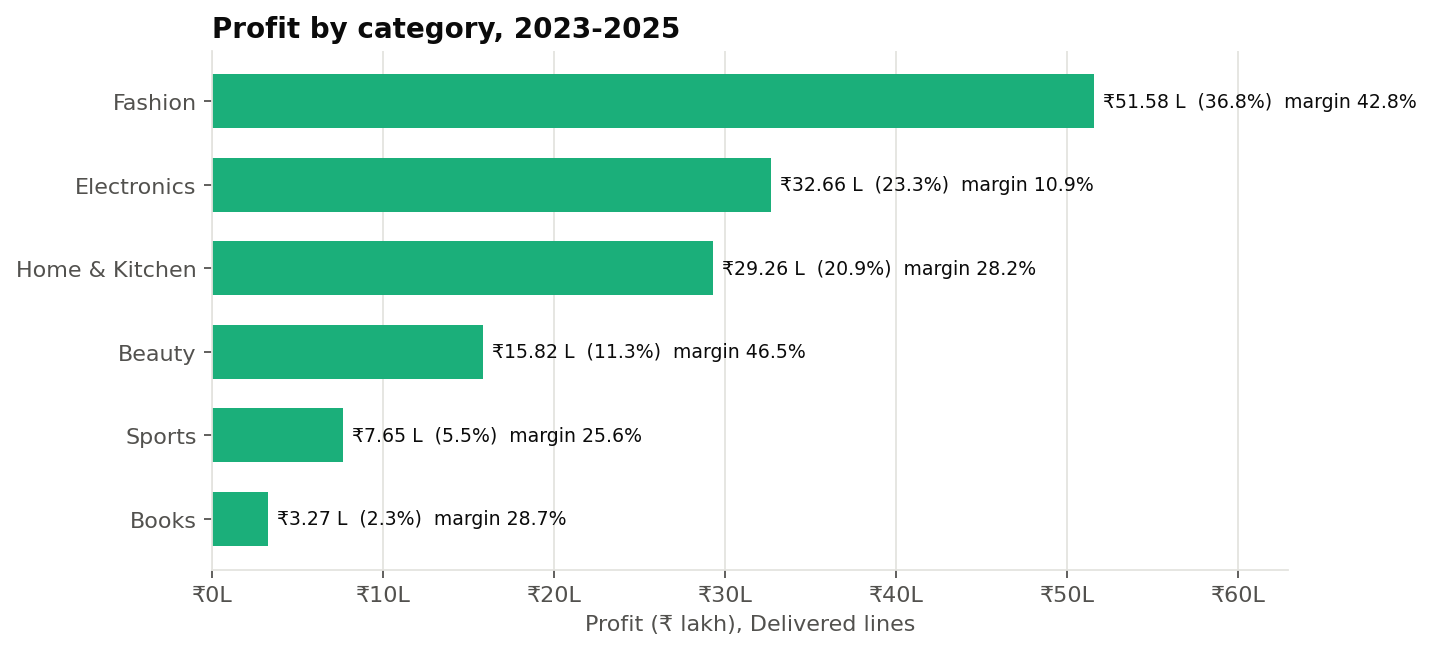

In [38]:
Image(str(FIG / "category_profit.png"))

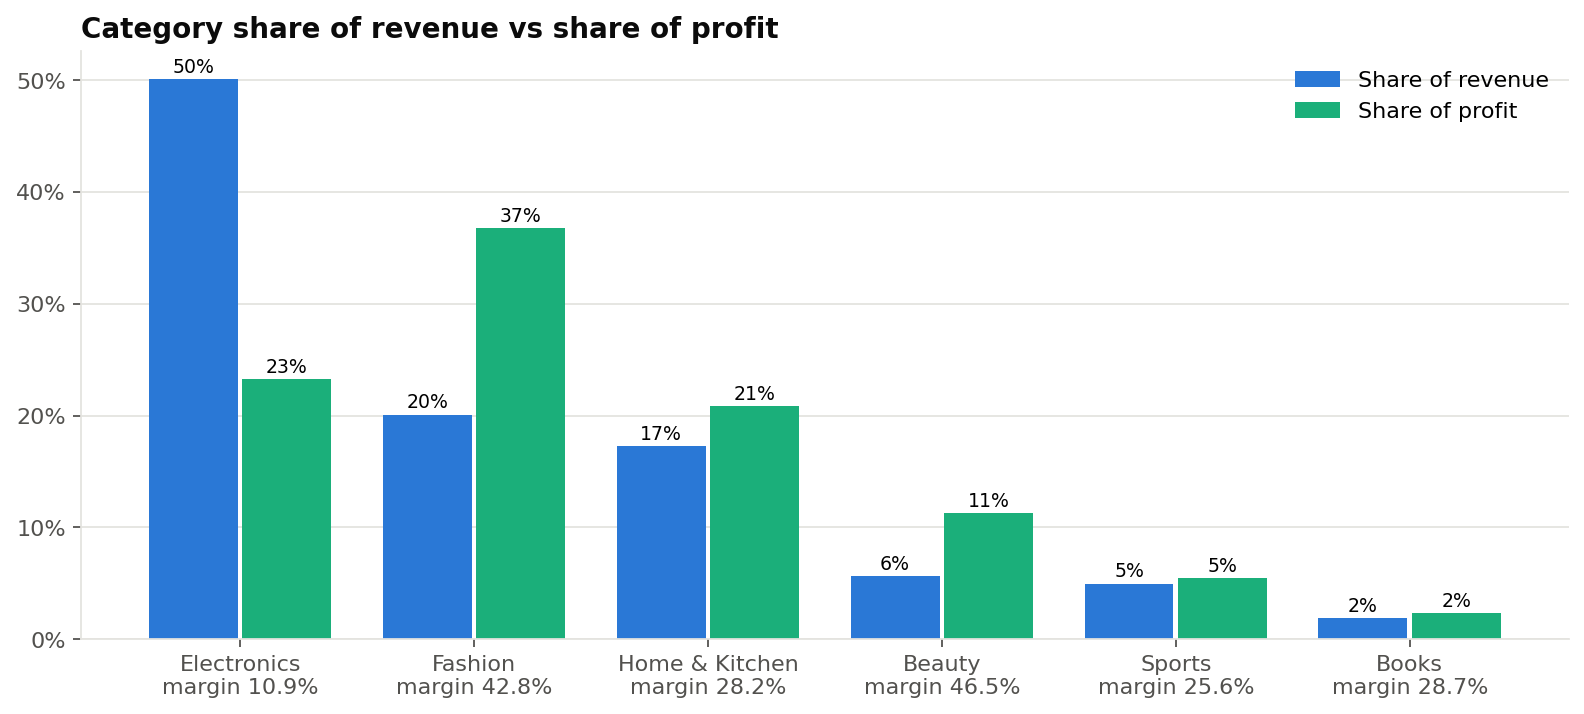

In [39]:
Image(str(FIG / "category_revenue_vs_profit.png"))

**Observation.**
- **Electronics** brings in **50.1% of revenue but only 23.3% of profit** (10.9% margin).
- **Fashion** brings in 20.1% of revenue but **36.8% of profit** (42.8% margin), which makes it the largest profit category. It also has the highest return rate (10.9%).
- **Beauty** has the highest margin (46.5%) but is small (5.7% of revenue).

**Interpretation.**
- Judging categories on revenue alone would badly overstate Electronics.
- Fashion is the real profit engine. Its return rate is the main threat to that profit.

### 8.2 Sub-categories

In [40]:
R['products']['subcategory_summary'][['Category', 'Sub_Category', 'Revenue', 'Profit', 'Profit_Margin', 'Revenue_Share', 'Return_Rate']]

,Category,Sub_Category,Revenue,Profit,Profit_Margin,Revenue_Share,Return_Rate
11,Electronics,Smartphones,"14,083,062.250","856,088.320",0.061,0.234,0.040
20,Home & Kitchen,Kitchen Appliances,"6,642,156.100","1,518,354.820",0.229,0.111,0.039
10,Electronics,Laptops,"6,321,369.750","307,913.230",0.049,0.105,0.050
15,Fashion,Footwear,"4,294,121.550","1,619,879.140",0.377,0.072,0.104
9,Electronics,Audio,"4,031,521.800","1,068,751.880",0.265,0.067,0.042
17,Fashion,Women's Clothing,"3,433,212.750","1,522,316.830",0.443,0.057,0.114
12,Electronics,Televisions,"2,498,330.650","-41,713.110",-0.017,0.042,0.045
16,Fashion,Men's Clothing,"2,457,654.050","1,094,759.510",0.445,0.041,0.113
13,Electronics,Wearables,"1,942,043.050","520,402.360",0.268,0.032,0.038
14,Fashion,Fashion Accessories,"1,872,752.650","920,636.940",0.492,0.031,0.104


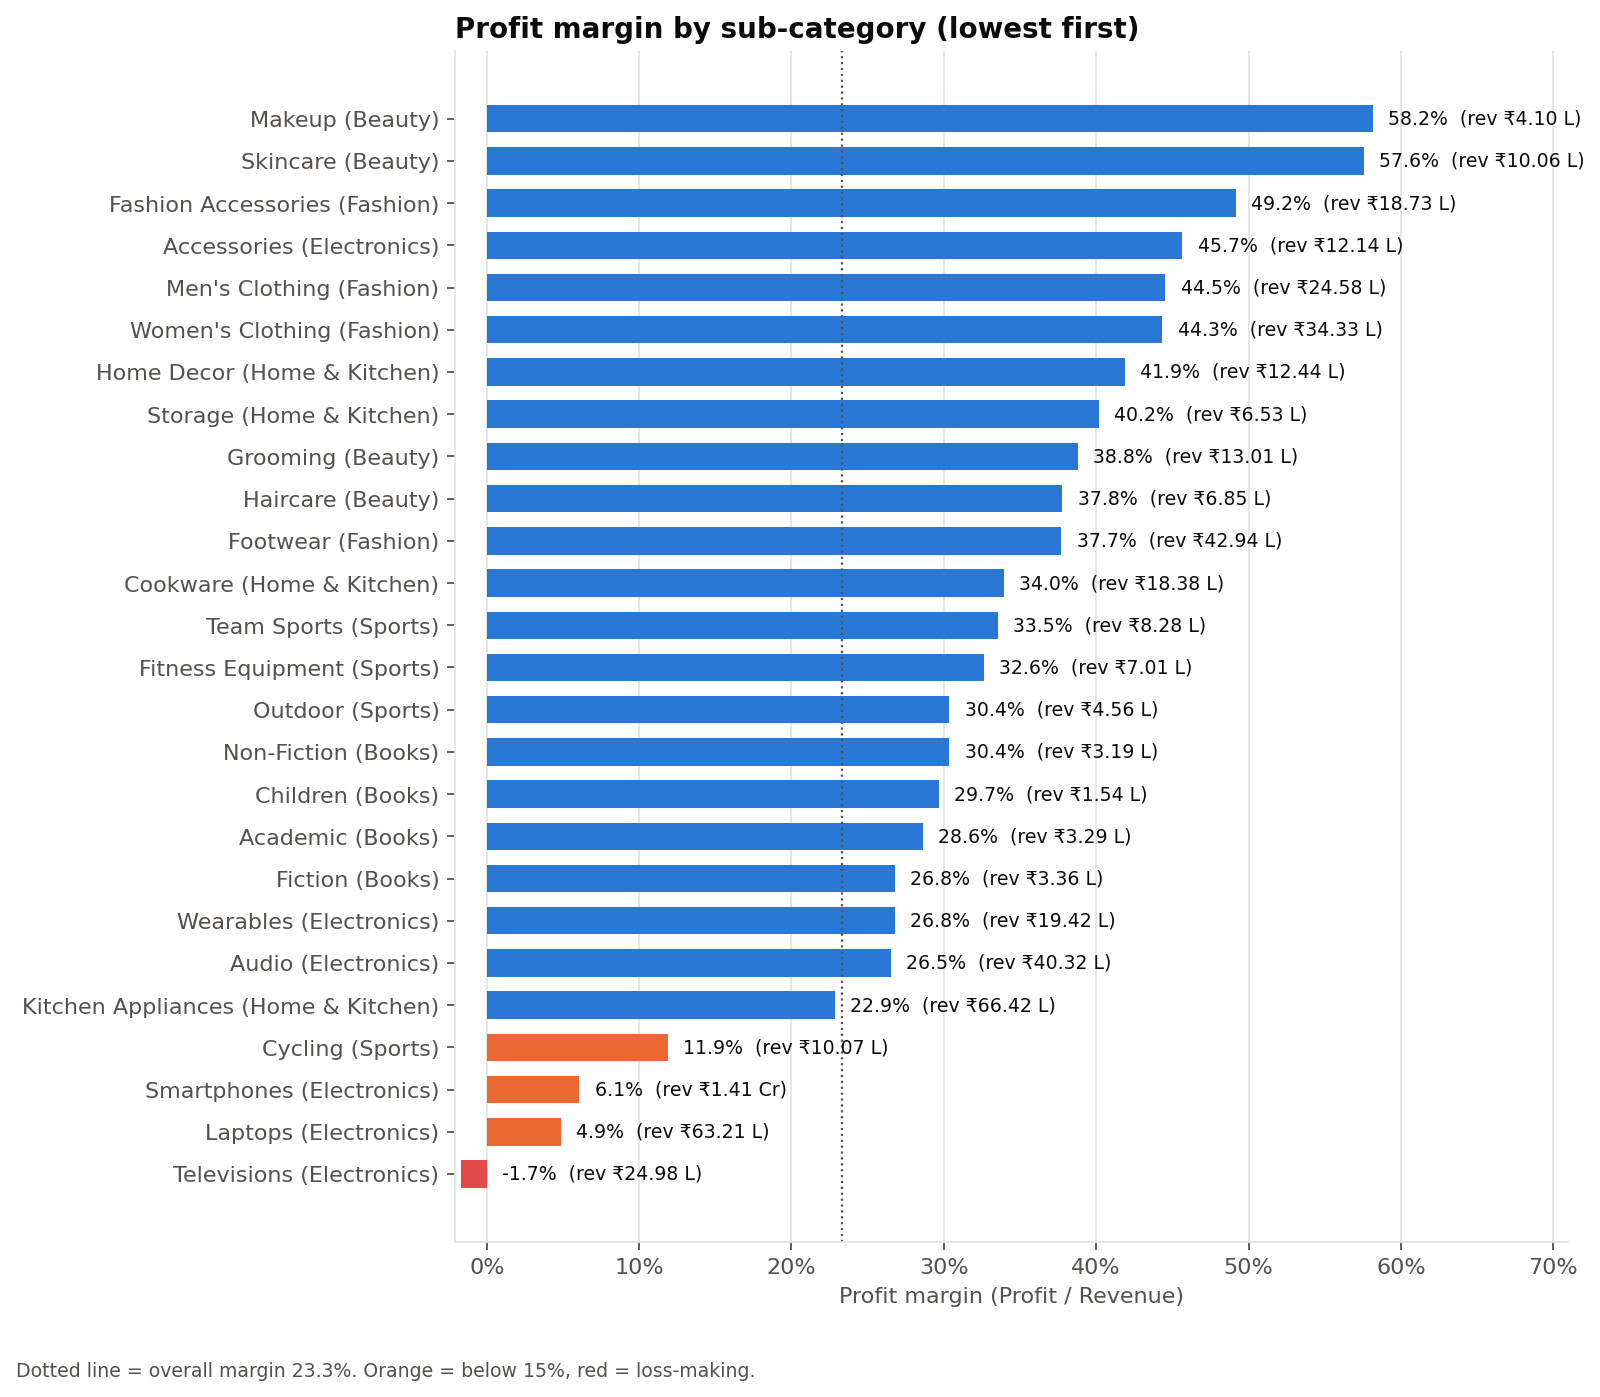

In [41]:
Image(str(FIG / "subcategory_margin.png"))

**Metrics used.** "High-revenue" means the largest share of Delivered revenue. "High-profit" means the largest absolute profit. "Low-margin" means Profit ÷ Revenue below 15%.

**Observation.**
- High-revenue sub-categories: Smartphones (23.4% of revenue), Kitchen Appliances (11.1%) and Laptops (10.5%).
- High-profit sub-categories: Footwear, Women's Clothing and Kitchen Appliances.
- **Low-margin sub-categories: Televisions (−1.7%, loss-making overall), Laptops (4.9%), Smartphones (6.1%) and Cycling (11.9%).**

### 8.3 Top products

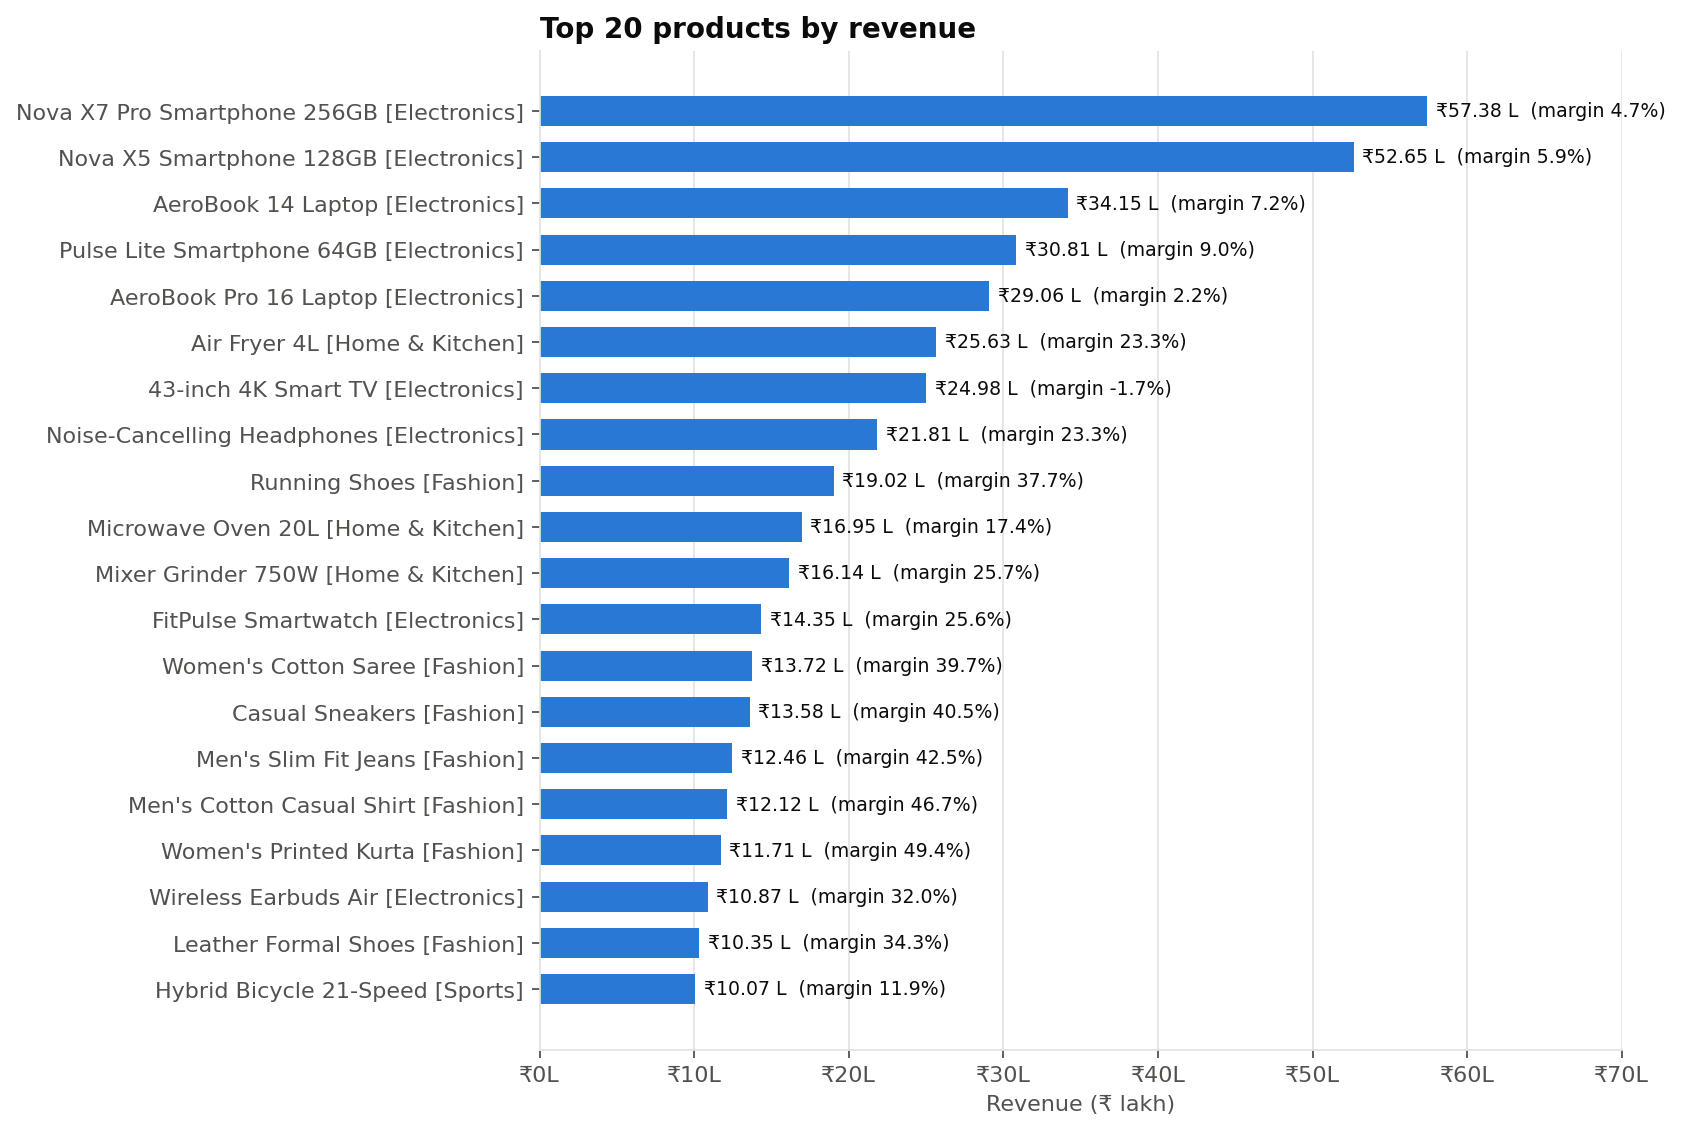

In [42]:
Image(str(FIG / "top_products_revenue.png"))

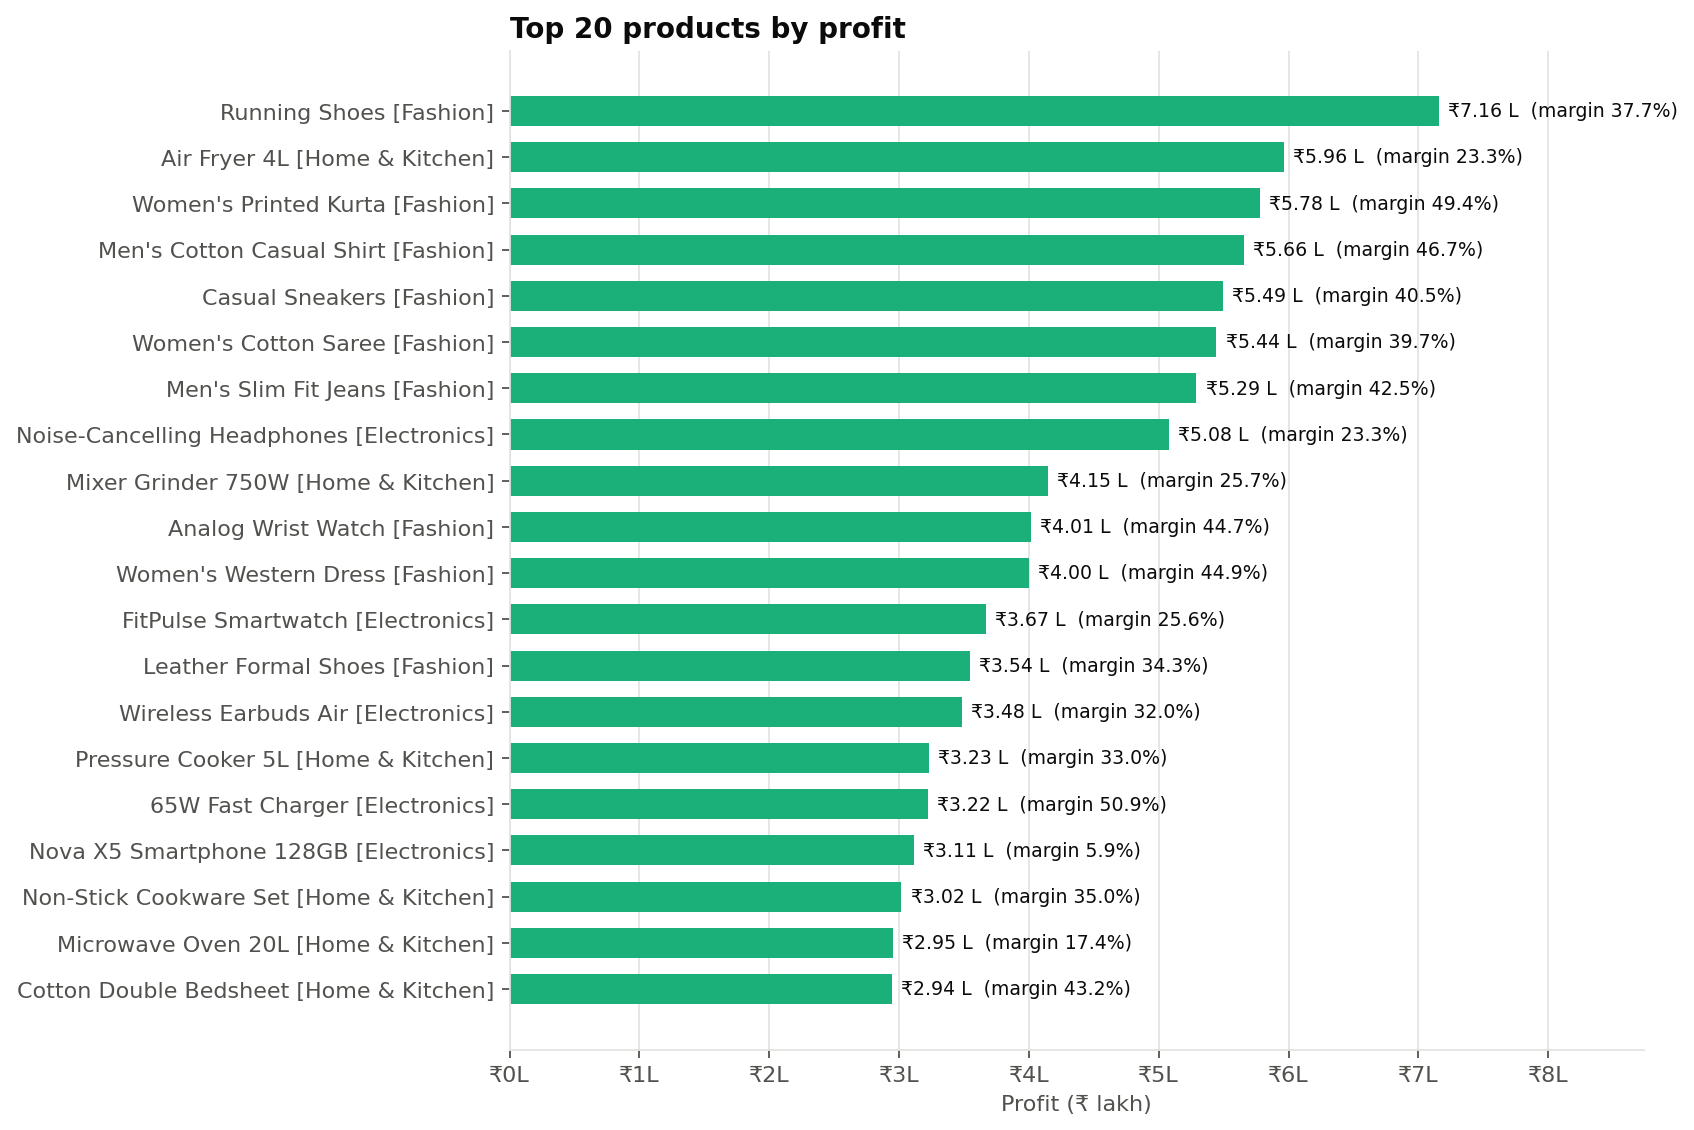

In [43]:
Image(str(FIG / "top_products_profit.png"))

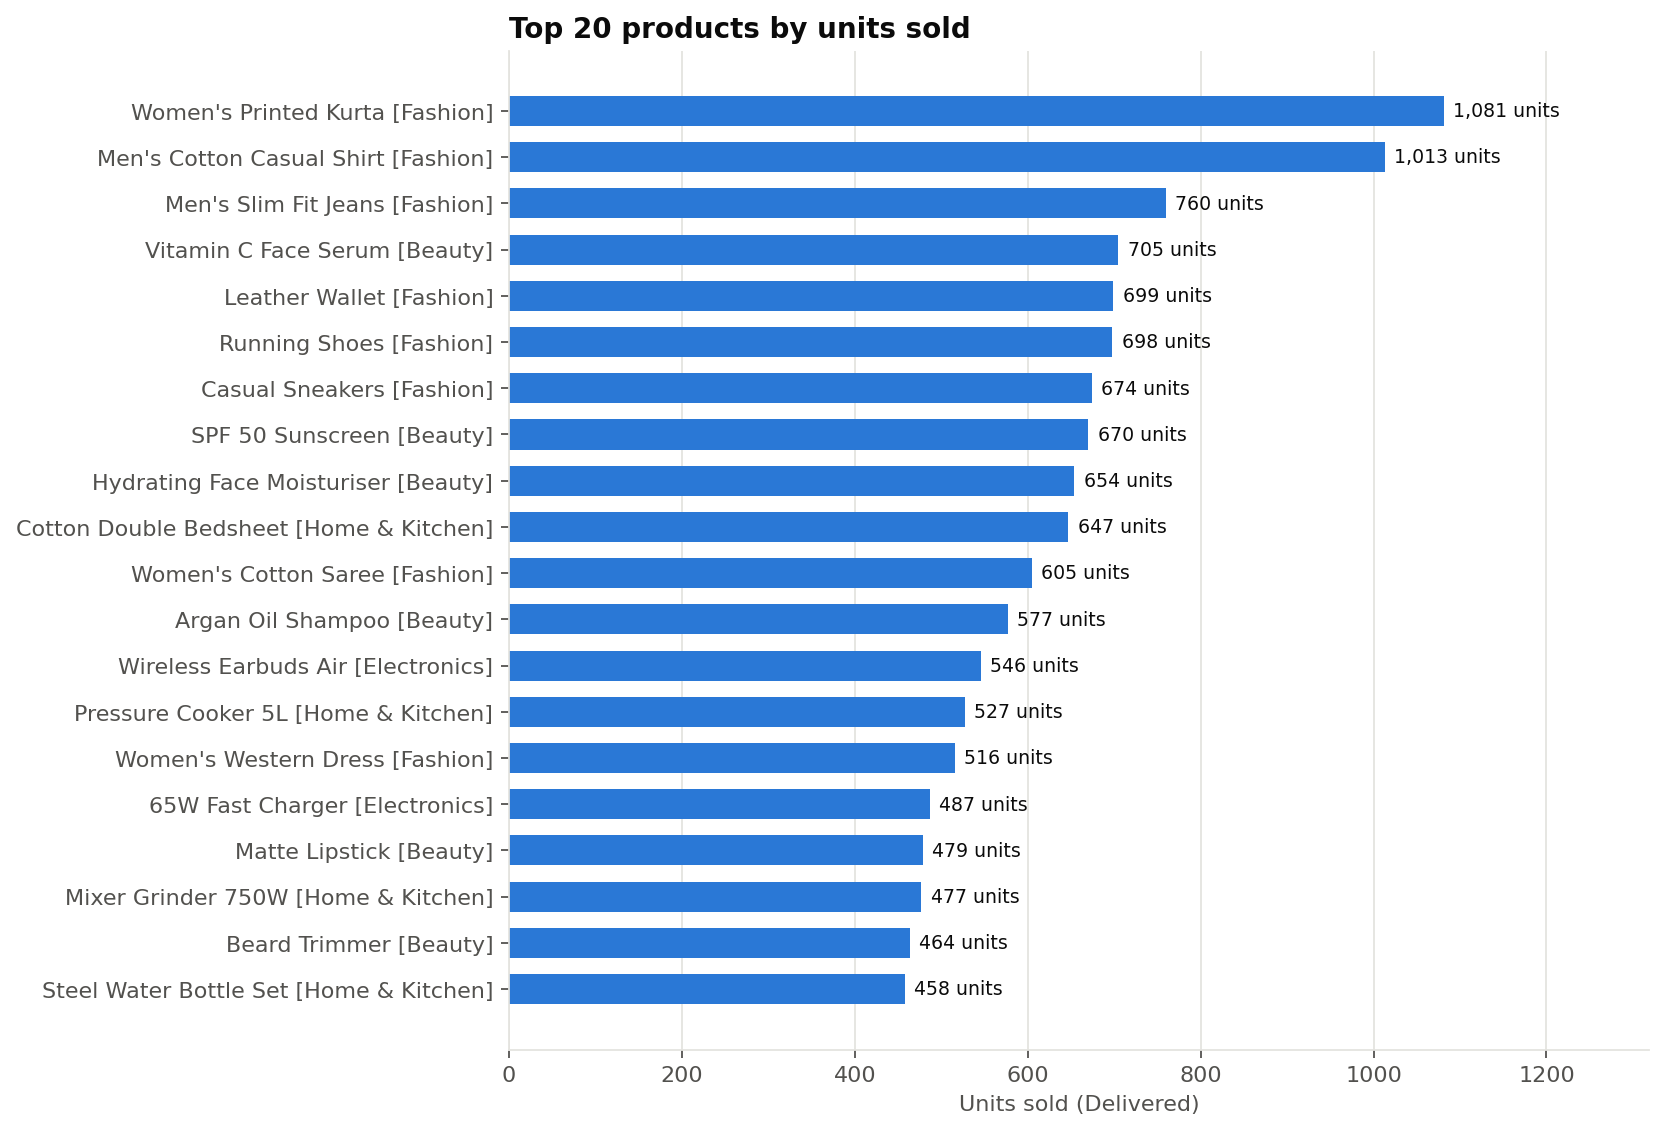

In [44]:
Image(str(FIG / "top_products_units.png"))

In [45]:
R['products']['bottom_products_revenue']

,Product_Name,Category,Units_Sold,Revenue,Profit,Profit_Margin,Average_Discount
15,Children's Illustrated Storybook,Books,250,"74,777.200","21,706.830",0.290,0.088
16,Kids Activity Book Set,Books,160,"78,909.900","23,869.250",0.302,0.099
12,Self-Help Bestseller,Books,358,"123,348.600","39,642.770",0.321,0.088
54,Resistance Bands Set,Sports,190,"130,293.800","57,906.780",0.444,0.100
6,Kajal & Eyeliner Combo,Beauty,409,"135,218.400","75,997.180",0.562,0.130
9,Contemporary Fiction Paperback,Books,356,"143,904.900","41,460.510",0.288,0.071
57,Football Size 5,Sports,169,"144,572.850","54,054.620",0.374,0.119
14,Competitive Exam Guide,Books,272,"146,692.550","49,249.990",0.336,0.096
52,Yoga Mat 6mm,Sports,232,"177,243.450","71,472.840",0.403,0.125
58,Badminton Racket Pair,Sports,145,"179,552.950","64,300.550",0.358,0.123


**Observation.**
- The five highest-revenue products are all phones and laptops, with margins of **2%-9%**. The 43-inch TV (₹24.98 L revenue) **lost ₹41,713**.
- The top profit earners are Running Shoes (₹7.16 L), the Air Fryer and Fashion basics.
- The best-sellers by units are the Women's Printed Kurta (1,081 units) and the Men's Casual Shirt.
- The lowest-revenue products are Books and small Sports items.

**Interpretation.** Best-sellers by revenue, by profit and by units are **three different lists**. Each KPI answers a different business question, so the dashboard should show all three.

## 9. Regional Analysis

In [46]:
R['regions']['region_summary']

,Region,Revenue,Profit,Orders,Customers,Quantity,Profit_Margin,AOV,Revenue_per_Customer,Revenue_Share,Revenue_2023,Revenue_2024,Revenue_2025,Growth_2024_vs_2023_%,Growth_2025_vs_2024_%,CAGR_2023_2025_%,Share_2023,Share_2025
0,South,"16,225,938.400","3,700,176.940",3296,540,6001,0.228,"4,922.918","30,048.034",0.270,"3,394,674.450","5,665,455.300","7,165,808.650",66.892,26.482,45.289,0.260,0.263
1,North,"14,400,613.350","3,190,656.810",2819,444,5290,0.222,"5,108.412","32,433.814",0.240,"3,067,265.350","4,942,813.300","6,390,534.700",61.147,29.289,44.342,0.235,0.235
2,West,"14,357,145.800","3,360,503.400",2971,490,5414,0.234,"4,832.429","29,300.298",0.239,"3,223,441.100","4,496,092.600","6,637,612.100",39.481,47.631,43.498,0.247,0.244
3,Central,"7,633,672.450","1,928,071.030",1551,248,3165,0.253,"4,921.775","30,780.937",0.127,"1,844,171.700","2,337,787.800","3,451,712.950",26.766,47.649,36.810,0.141,0.127
4,East,"7,439,199.150","1,843,143.400",1575,262,2902,0.248,"4,723.301","28,393.890",0.124,"1,531,324.650","2,327,605.900","3,580,268.600",52.000,53.818,52.906,0.117,0.132


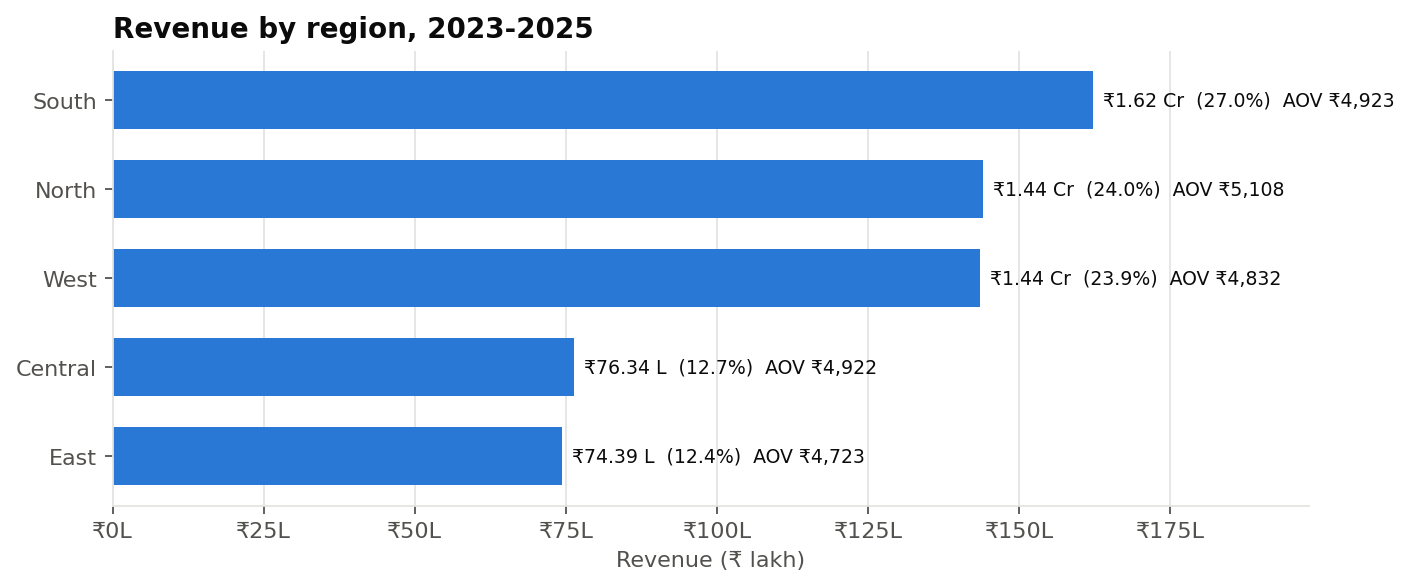

In [47]:
Image(str(FIG / "regional_revenue.png"))

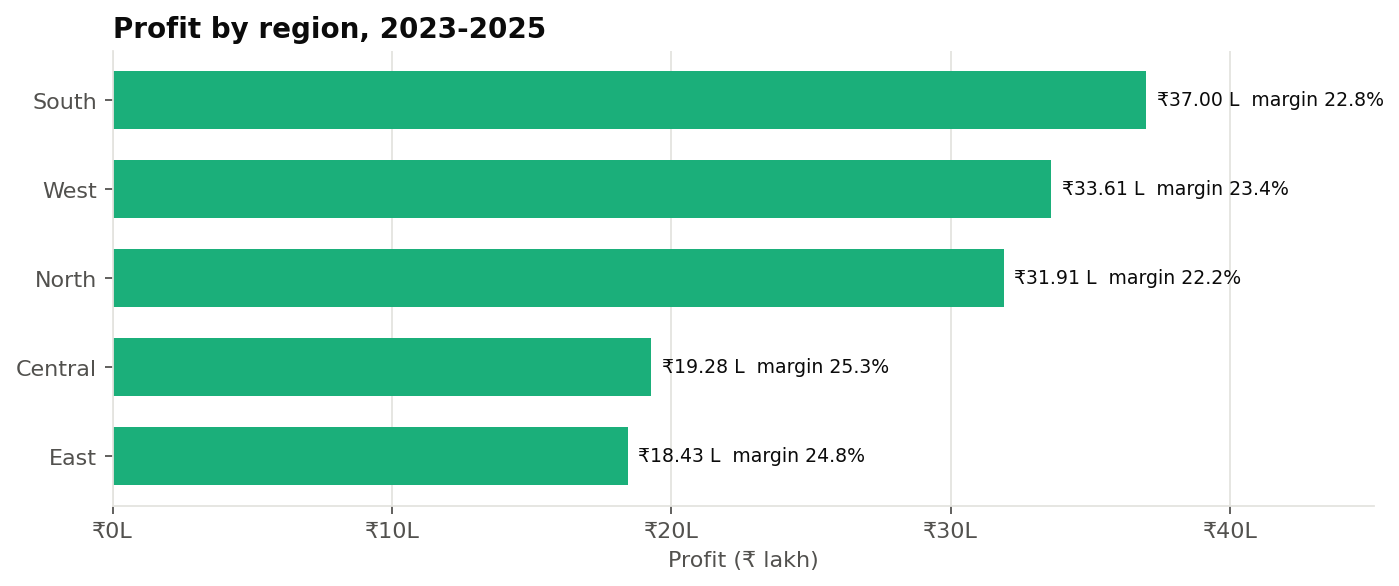

In [48]:
Image(str(FIG / "regional_profit.png"))

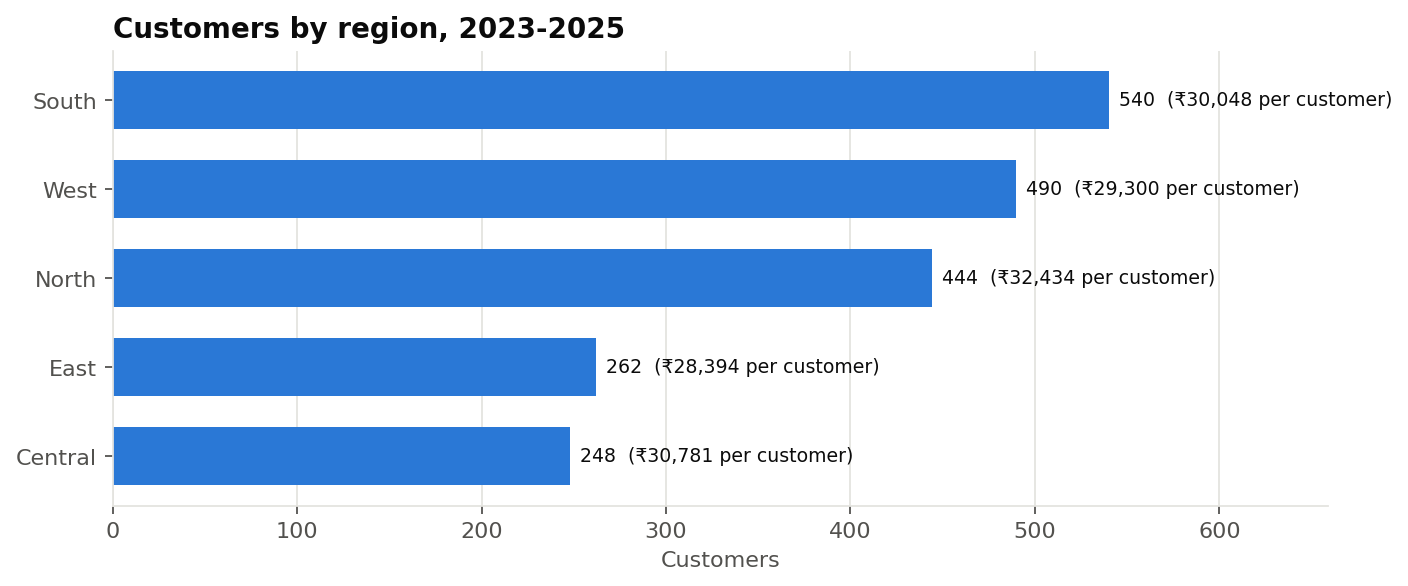

In [49]:
Image(str(FIG / "region_customers.png"))

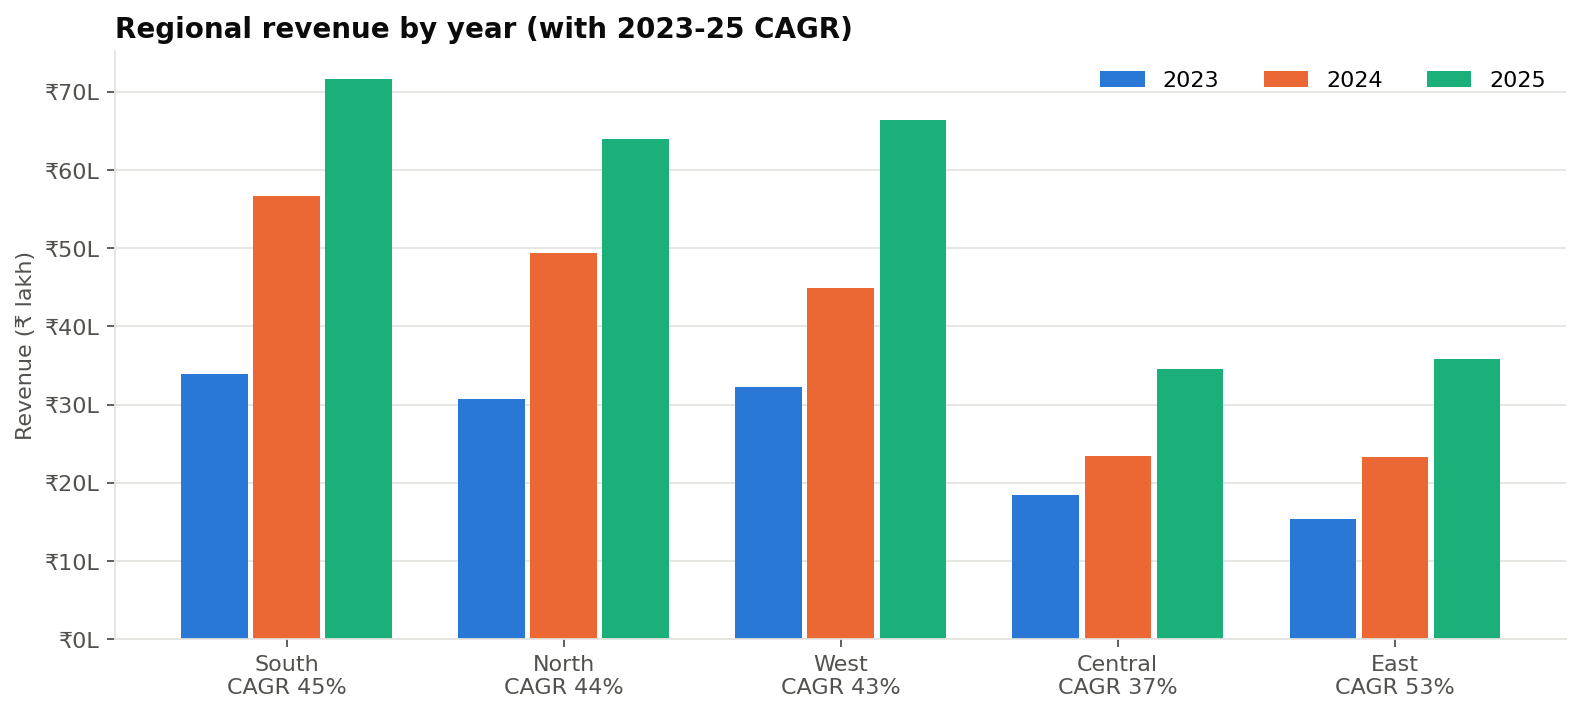

In [50]:
Image(str(FIG / "regional_growth.png"))

In [51]:
display(R['regions']['state_summary']); display(R['regions']['city_summary'].head(10)); R['regions']['geo_concentration']

,Region,State,Revenue,Profit,Orders,Customers,Quantity,Profit_Margin,AOV,Revenue_per_Customer,Revenue_Share
20,West,Maharashtra,"6,864,463.250","1,641,591.060",1501,254,2655,0.239,"4,573.260","27,025.446",0.114
19,West,Gujarat,"6,524,555.950","1,481,379.690",1257,203,2377,0.227,"5,190.578","32,140.670",0.109
1,Central,Madhya Pradesh,"6,148,214.550","1,487,003.270",1210,204,2406,0.242,"5,081.169","30,138.307",0.102
16,South,Tamil Nadu,"4,533,463.600","1,000,305.070",844,139,1507,0.221,"5,371.402","32,614.846",0.075
17,South,Telangana,"4,175,250.400","824,534.660",715,112,1321,0.197,"5,839.511","37,279.021",0.070
14,South,Karnataka,"3,993,205.850","995,279.970",918,149,1636,0.249,"4,349.897","26,800.039",0.066
12,North,Uttar Pradesh,"3,677,663.550","882,737.400",813,134,1501,0.240,"4,523.571","27,445.250",0.061
10,North,Punjab,"3,005,594.750","674,013.300",616,94,1126,0.224,"4,879.212","31,974.412",0.050
6,East,West Bengal,"3,004,708.600","712,817.900",617,108,1098,0.237,"4,869.868","27,821.376",0.050
8,North,Delhi,"2,503,365.650","509,880.100",449,73,812,0.204,"5,575.425","34,292.680",0.042


,Region,State,City,Revenue,Profit,Orders,Customers,Quantity,Profit_Margin,AOV,Revenue_per_Customer,Revenue_Share
26,South,Telangana,Hyderabad,"4,175,250.400","824,534.660",715,112,1321,0.197,"5,839.511","37,279.021",0.070
28,West,Gujarat,Ahmedabad,"3,716,577.150","856,868.580",681,98,1342,0.231,"5,457.529","37,924.257",0.062
1,Central,Madhya Pradesh,Bhopal,"3,226,049.050","759,763.400",587,92,1248,0.236,"5,495.825","35,065.751",0.054
24,South,Tamil Nadu,Chennai,"3,178,401.250","646,874.490",553,94,982,0.204,"5,747.561","33,812.779",0.053
31,West,Maharashtra,Mumbai,"3,113,040.450","694,201.210",639,104,1092,0.223,"4,871.738","29,933.081",0.052
20,South,Karnataka,Bengaluru,"2,741,671.950","670,615.920",623,103,1085,0.245,"4,400.758","26,618.174",0.046
33,West,Maharashtra,Pune,"2,533,111.350","583,256.530",539,103,976,0.230,"4,699.650","24,593.314",0.042
11,North,Delhi,New Delhi,"2,503,365.650","509,880.100",449,73,812,0.204,"5,575.425","34,292.680",0.042
8,East,West Bengal,Kolkata,"2,488,922.500","594,421.760",504,90,891,0.239,"4,938.338","27,654.694",0.041
12,North,Haryana,Gurugram,"2,380,405.750","505,778.080",440,73,867,0.212,"5,410.013","32,608.298",0.040


,Measure,Share,Members
0,Top region share of revenue,0.270,South
1,Top 2 regions share,0.510,"South, North"
2,Top 5 states share (of 21),0.470,"Maharashtra, Gujarat, Madhya Pradesh, Tamil Nadu, Telangana"
3,Top 5 cities share (of 34),0.290,"Hyderabad, Ahmedabad, Bhopal, Chennai, Mumbai"
4,Bottom 5 states share,0.085,"Odisha, Chandigarh, Bihar, Goa, Jharkhand"


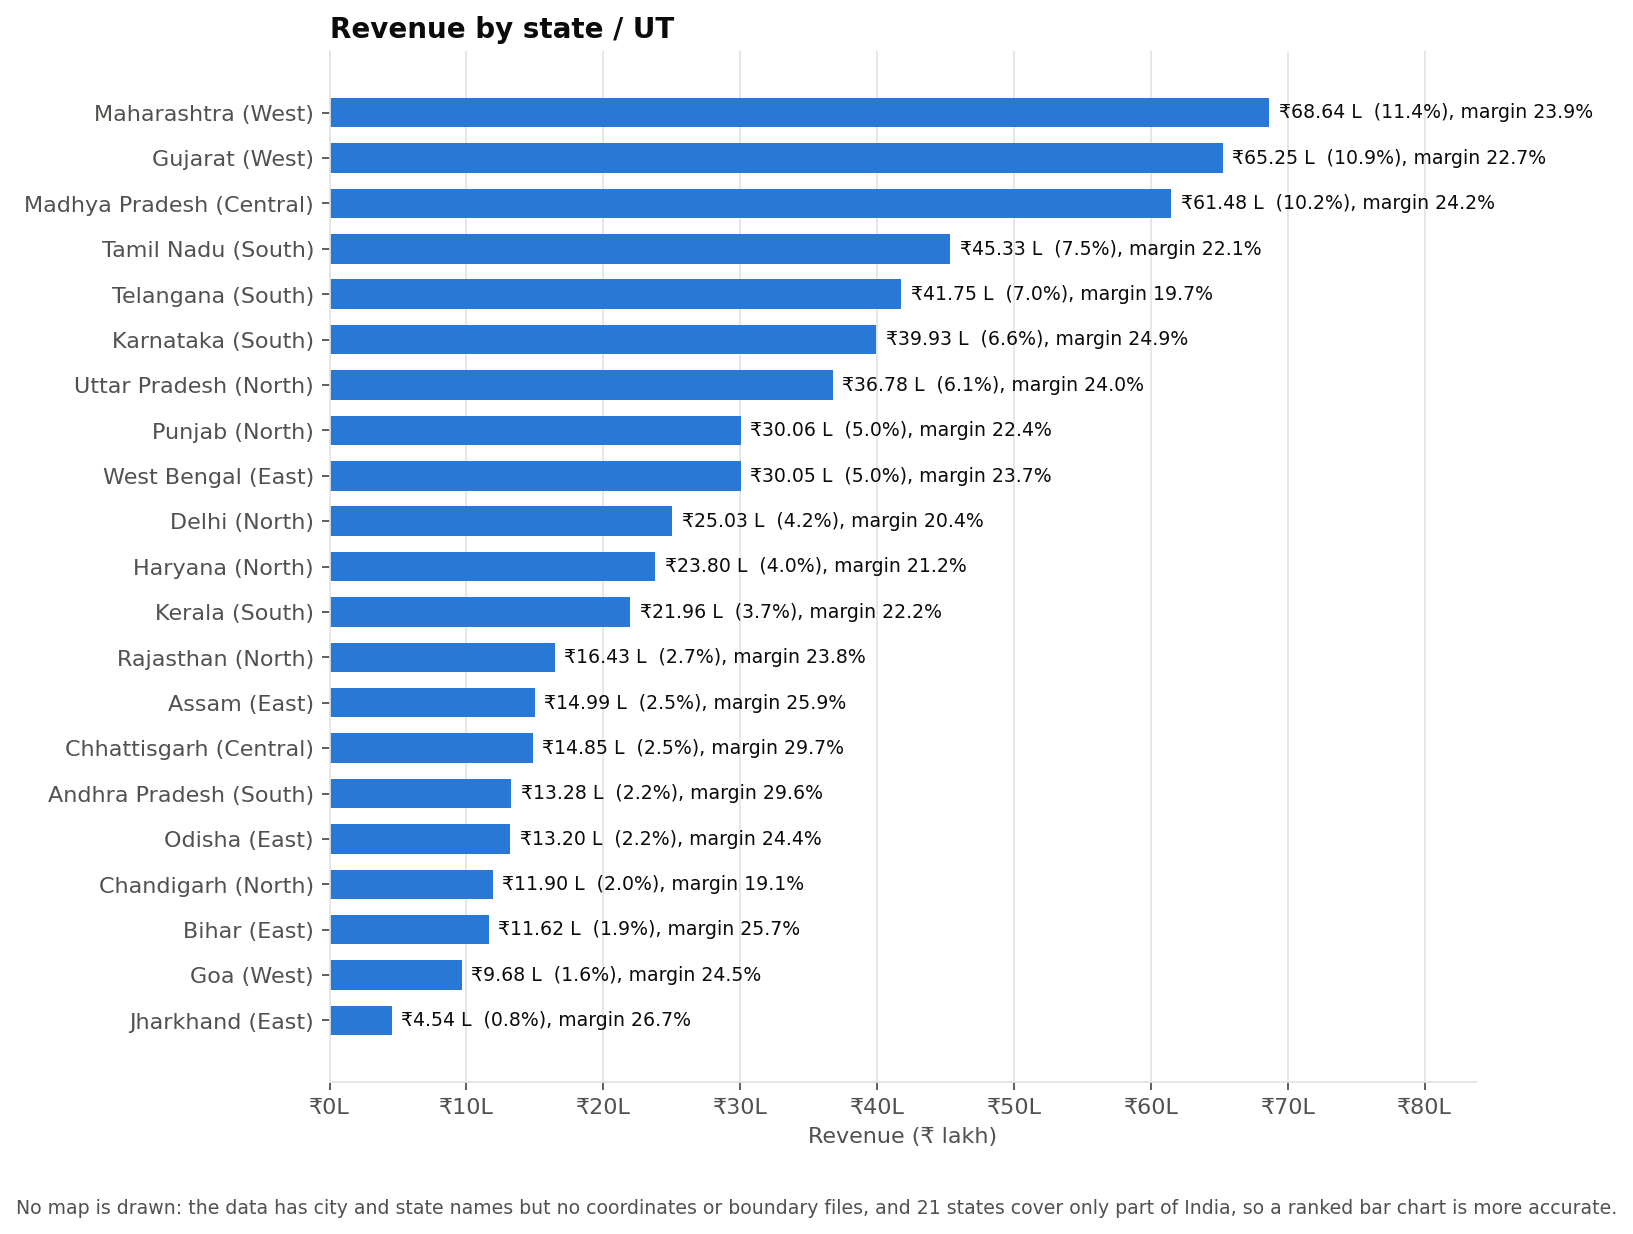

In [52]:
Image(str(FIG / "state_revenue.png"))

**Observation.**
- **South** leads on revenue (₹1.62 Cr, 27.0%) and profit (₹37.0 L).
- **East** is the smallest region but grows fastest (CAGR 52.9%).
- **Central's** share fell from 14.1% (2023) to 12.7% (2025), although it has the highest margin (25.3%).
- Margins are similar everywhere (22%-25%).
- The top 5 states (Maharashtra, Gujarat, Madhya Pradesh, Tamil Nadu, Telangana) produce 47% of revenue.
- The top 5 cities produce 29%, led by Hyderabad (7.0%).

**Interpretation.** Revenue is concentrated in a few large states and cities. Regional profitability is uniform, so the question for each region is **growth, not margin**.

*No map is used.* The data has state names but no coordinates or boundary files, and 21 states cover only part of India. A ranked bar chart is more accurate than a partly filled map.

## 10. Discount & Profitability Analysis
### 10.1 Discount vs sales, profit, margin and quantity

In [53]:
R['discount']['discount_correlations']

,Pair,Pearson_r,Pearson_p,Spearman_rho,Spearman_p,Strength (Spearman)
0,Discount vs Sales,-0.111,0.000,-0.125,0.000,negligible
1,Discount vs Profit,-0.254,0.000,-0.374,0.000,weak negative
2,Discount vs Profit_Margin,-0.317,0.000,-0.318,0.000,weak negative
3,Discount vs Quantity,0.024,0.002,0.063,0.000,negligible


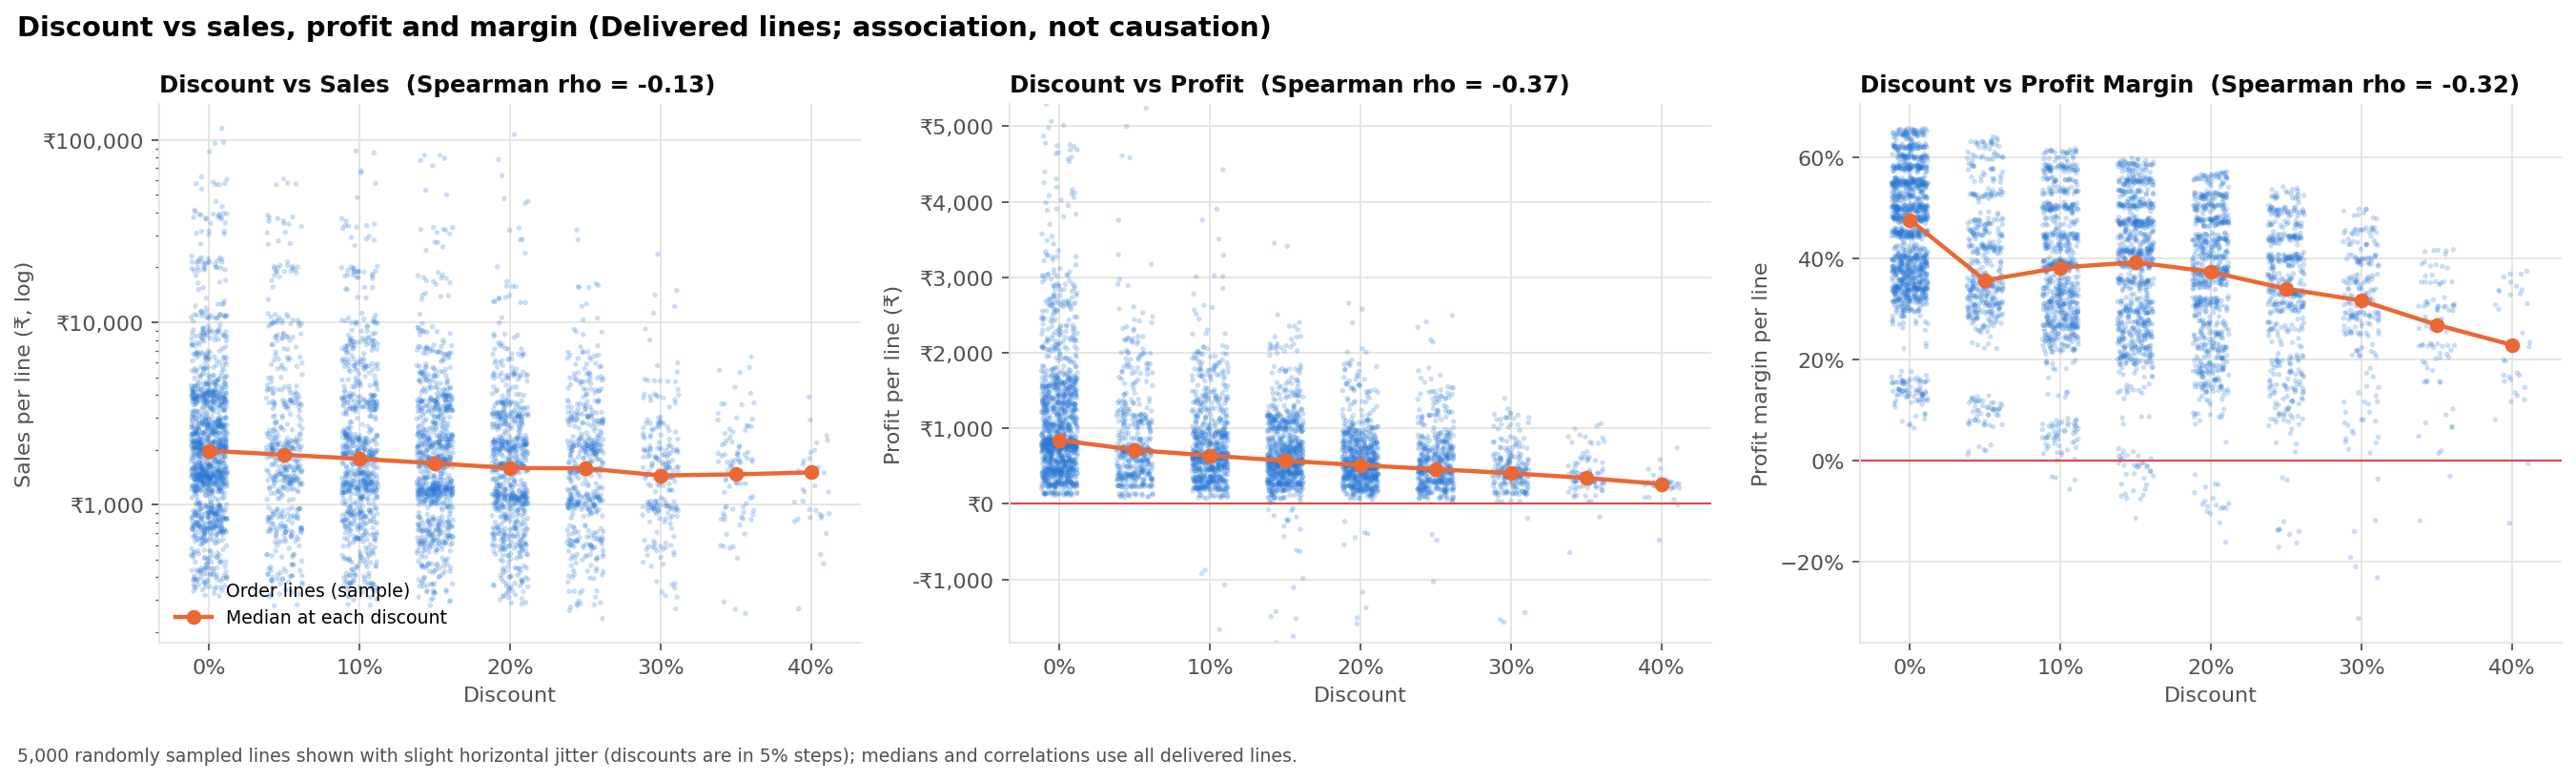

In [54]:
Image(str(FIG / "discount_scatter_panels.png"))

In [55]:
R['discount']['discount_summary']

,Discount_Bucket,Lines,Revenue,Profit,Avg_Sales_per_Line,Avg_Quantity,Avg_List_Price,Loss_Lines,Electronics_Share,Line_Share,Revenue_Share,Profit_Margin,Loss_Line_Rate
0,0%,4548,"19,351,670.000","5,671,055.270","4,254.985",1.319,"3,639.939",0,0.228,0.270,0.322,0.293,0.000
1,5-10%,4145,"18,842,475.200","3,652,045.080","4,545.832",1.324,"4,265.544",23,0.294,0.246,0.314,0.194,0.006
2,15-20%,5429,"15,824,580.200","3,411,465.290","2,914.824",1.353,"2,917.541",159,0.141,0.322,0.263,0.216,0.029
3,25-30%,2346,"5,355,815.600","1,148,631.300","2,282.956",1.433,"2,358.908",53,0.070,0.139,0.089,0.214,0.023
4,35-40%,392,"682,028.150","139,354.640","1,739.868",1.462,"1,929.755",14,0.008,0.023,0.011,0.204,0.036


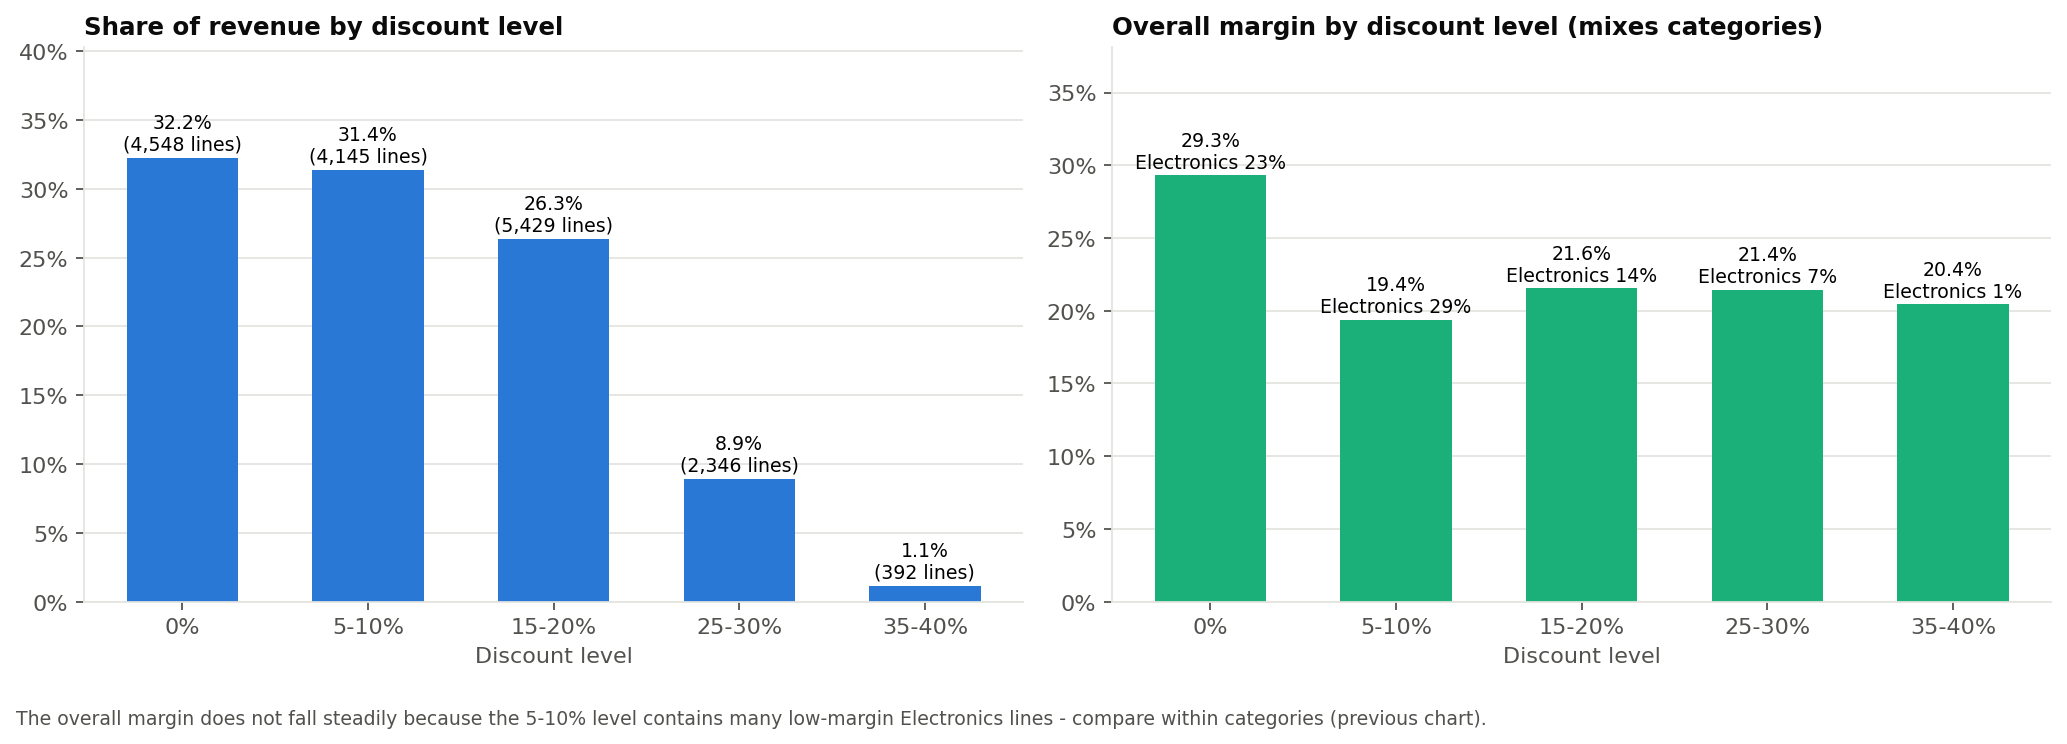

In [56]:
Image(str(FIG / "discount_bucket_summary.png"))

Discount buckets follow the data: discounts are in 5% steps from 0% to 40%, so the buckets are 0%, 5-10%, 15-20%, 25-30% and 35-40%.

In [57]:
display(R['discount']['margin_by_category_bucket']); display(R['discount']['discount_margin_within_category']); R['discount']['quantity_by_category_bucket']

Discount_Bucket,Category,0%,5-10%,15-20%,25-30%,35-40%
0,Beauty,0.526,0.478,0.440,0.372,0.197
1,Books,0.349,0.292,0.221,0.129,-0.019
2,Electronics,0.177,0.108,0.018,-0.081,0.134
3,Fashion,0.522,0.469,0.418,0.346,0.250
4,Home & Kitchen,0.365,0.304,0.232,0.128,-0.000
5,Sports,0.339,0.275,0.223,0.079,0.082


,Category,Spearman_rho_Discount_vs_Margin,p_value,Lines
0,Beauty,-0.577,0.000,2885
1,Books,-0.887,0.000,1130
2,Electronics,-0.369,0.000,3185
3,Fashion,-0.794,0.000,5208
4,Home & Kitchen,-0.628,0.000,3447
5,Sports,-0.698,0.000,1005


Discount_Bucket,Category,0%,5-10%,15-20%,25-30%,35-40%
0,Beauty,1.538,1.553,1.679,1.690,1.816
1,Books,1.755,1.877,1.715,1.620,3.000
2,Electronics,1.075,1.129,1.072,1.079,1.000
3,Fashion,1.308,1.322,1.369,1.456,1.408
4,Home & Kitchen,1.297,1.225,1.214,1.279,1.275
5,Sports,1.164,1.129,1.152,1.218,1.615


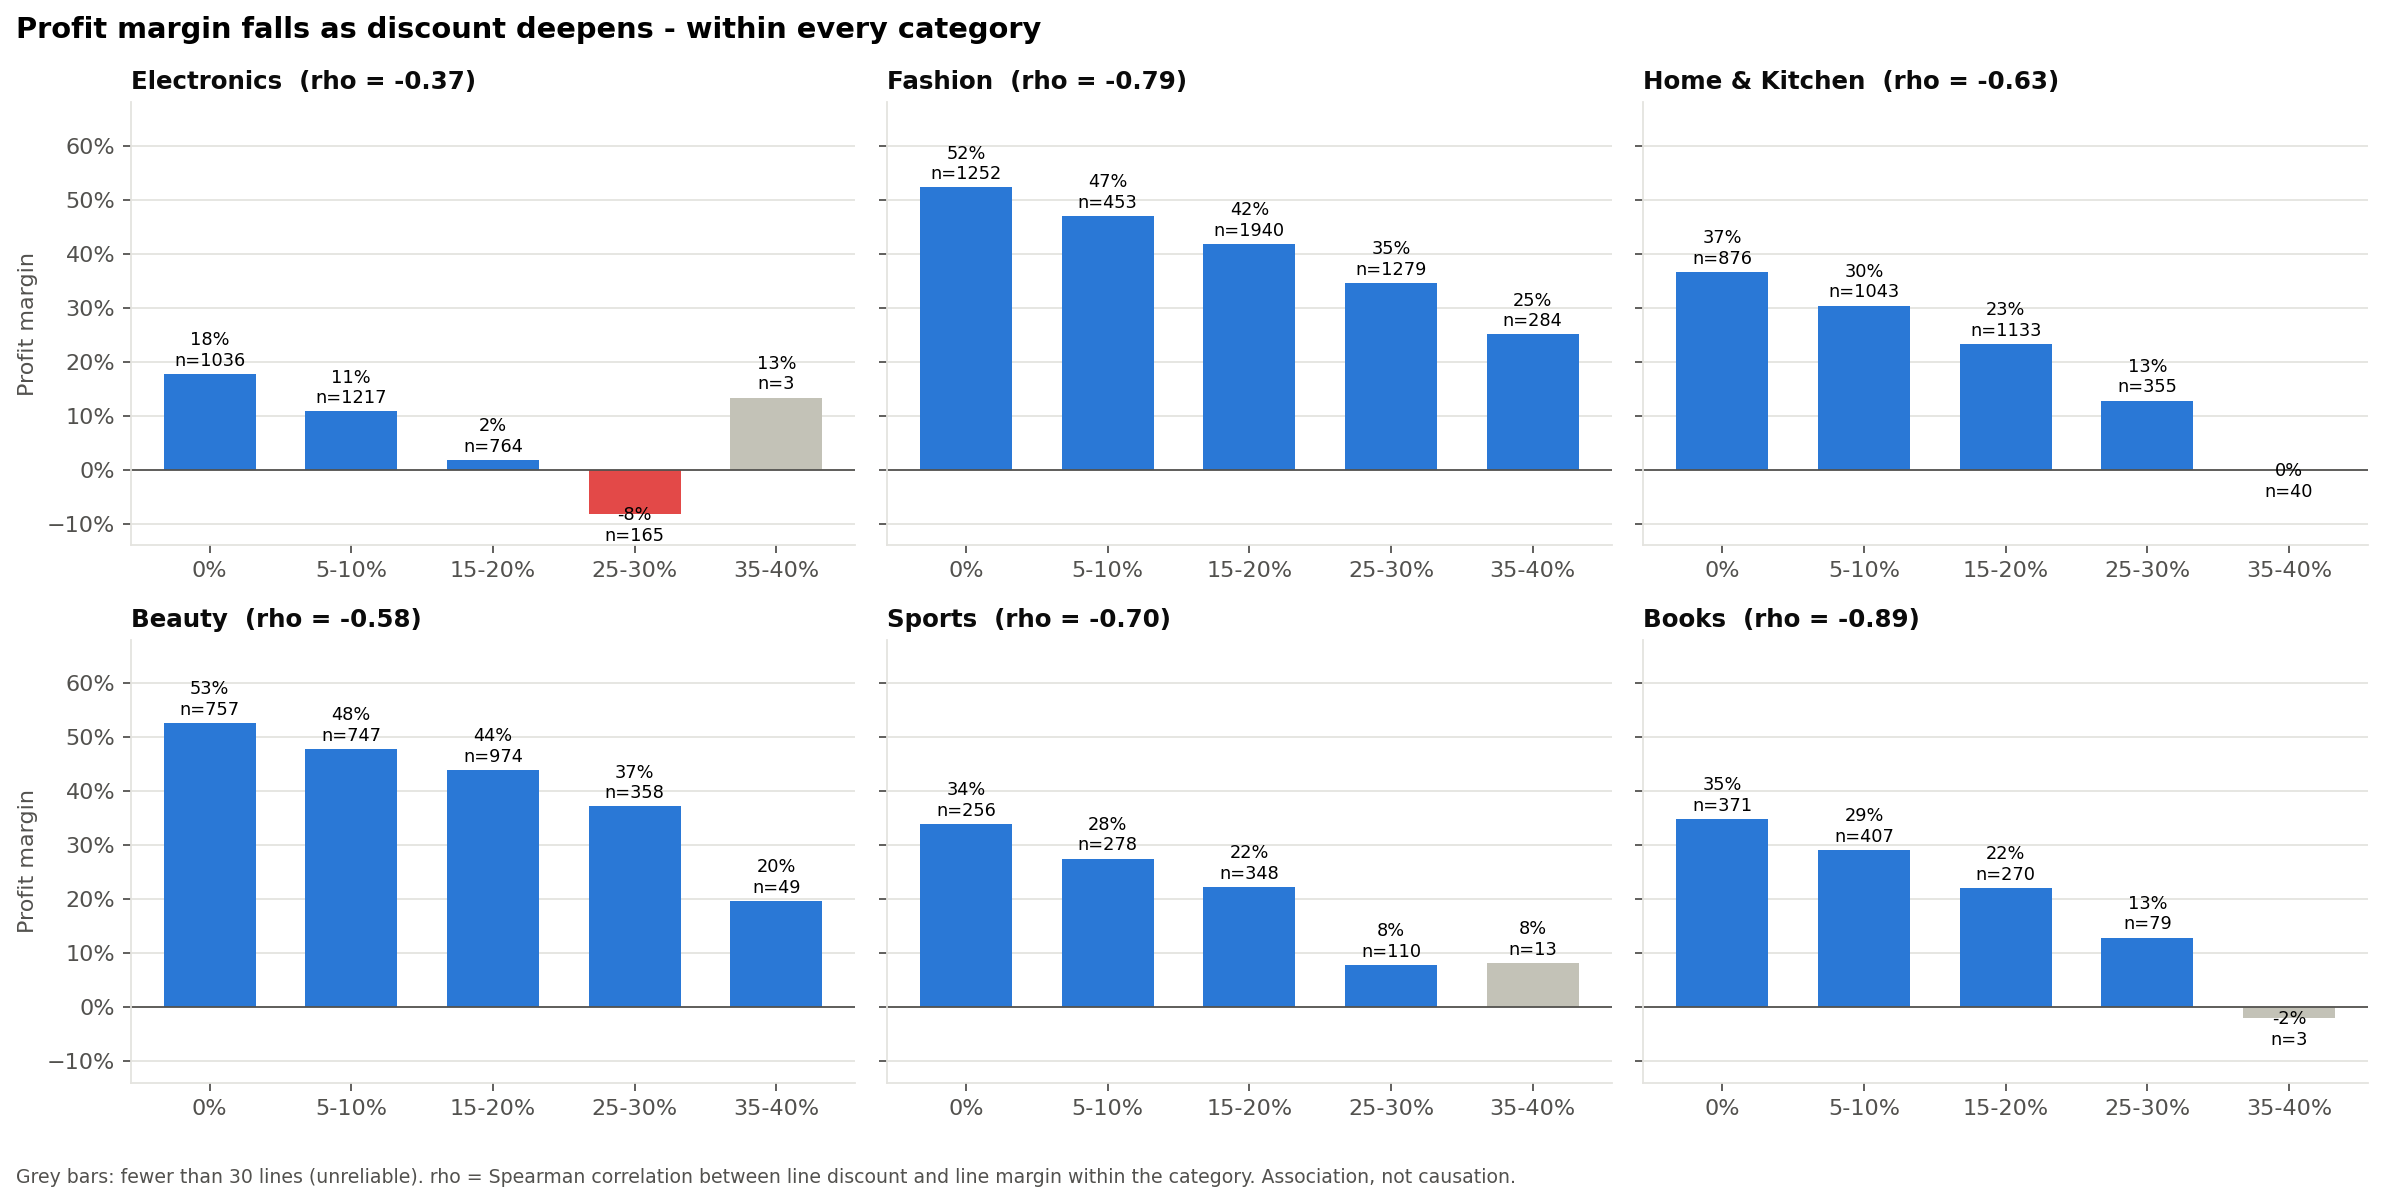

In [58]:
Image(str(FIG / "discount_profit_relationship.png"))

**Observation.**
- Across all lines, discount has a **weak negative association with profit (ρ = −0.37) and margin (ρ = −0.32)**. Its association with Sales is negligible (ρ = −0.13), and with Quantity it is essentially zero (ρ = 0.06).
- **Within each category, margin falls steadily as the discount deepens** (ρ from −0.37 to −0.89). For example, Fashion's margin falls from 52% at 0% discount to 25% at 35-40%.
- The overall bucket table does **not** fall steadily (29% → 19% → 22% → 21% → 20%). The 5-10% bucket contains many low-margin Electronics lines (29% of its lines). This is a **Simpson's-paradox** effect of category mix.

**Interpretation (association, not causation).** Deeper discounts go with lower margins without a visible increase in units per line. This suggests blanket discounting gives away margin. Cause cannot be proven from observational data. Discounts may also be *targeted* at slow items or price-sensitive buyers. A controlled test (A/B pricing) would be needed to measure the true effect.

### 10.2 Profitability

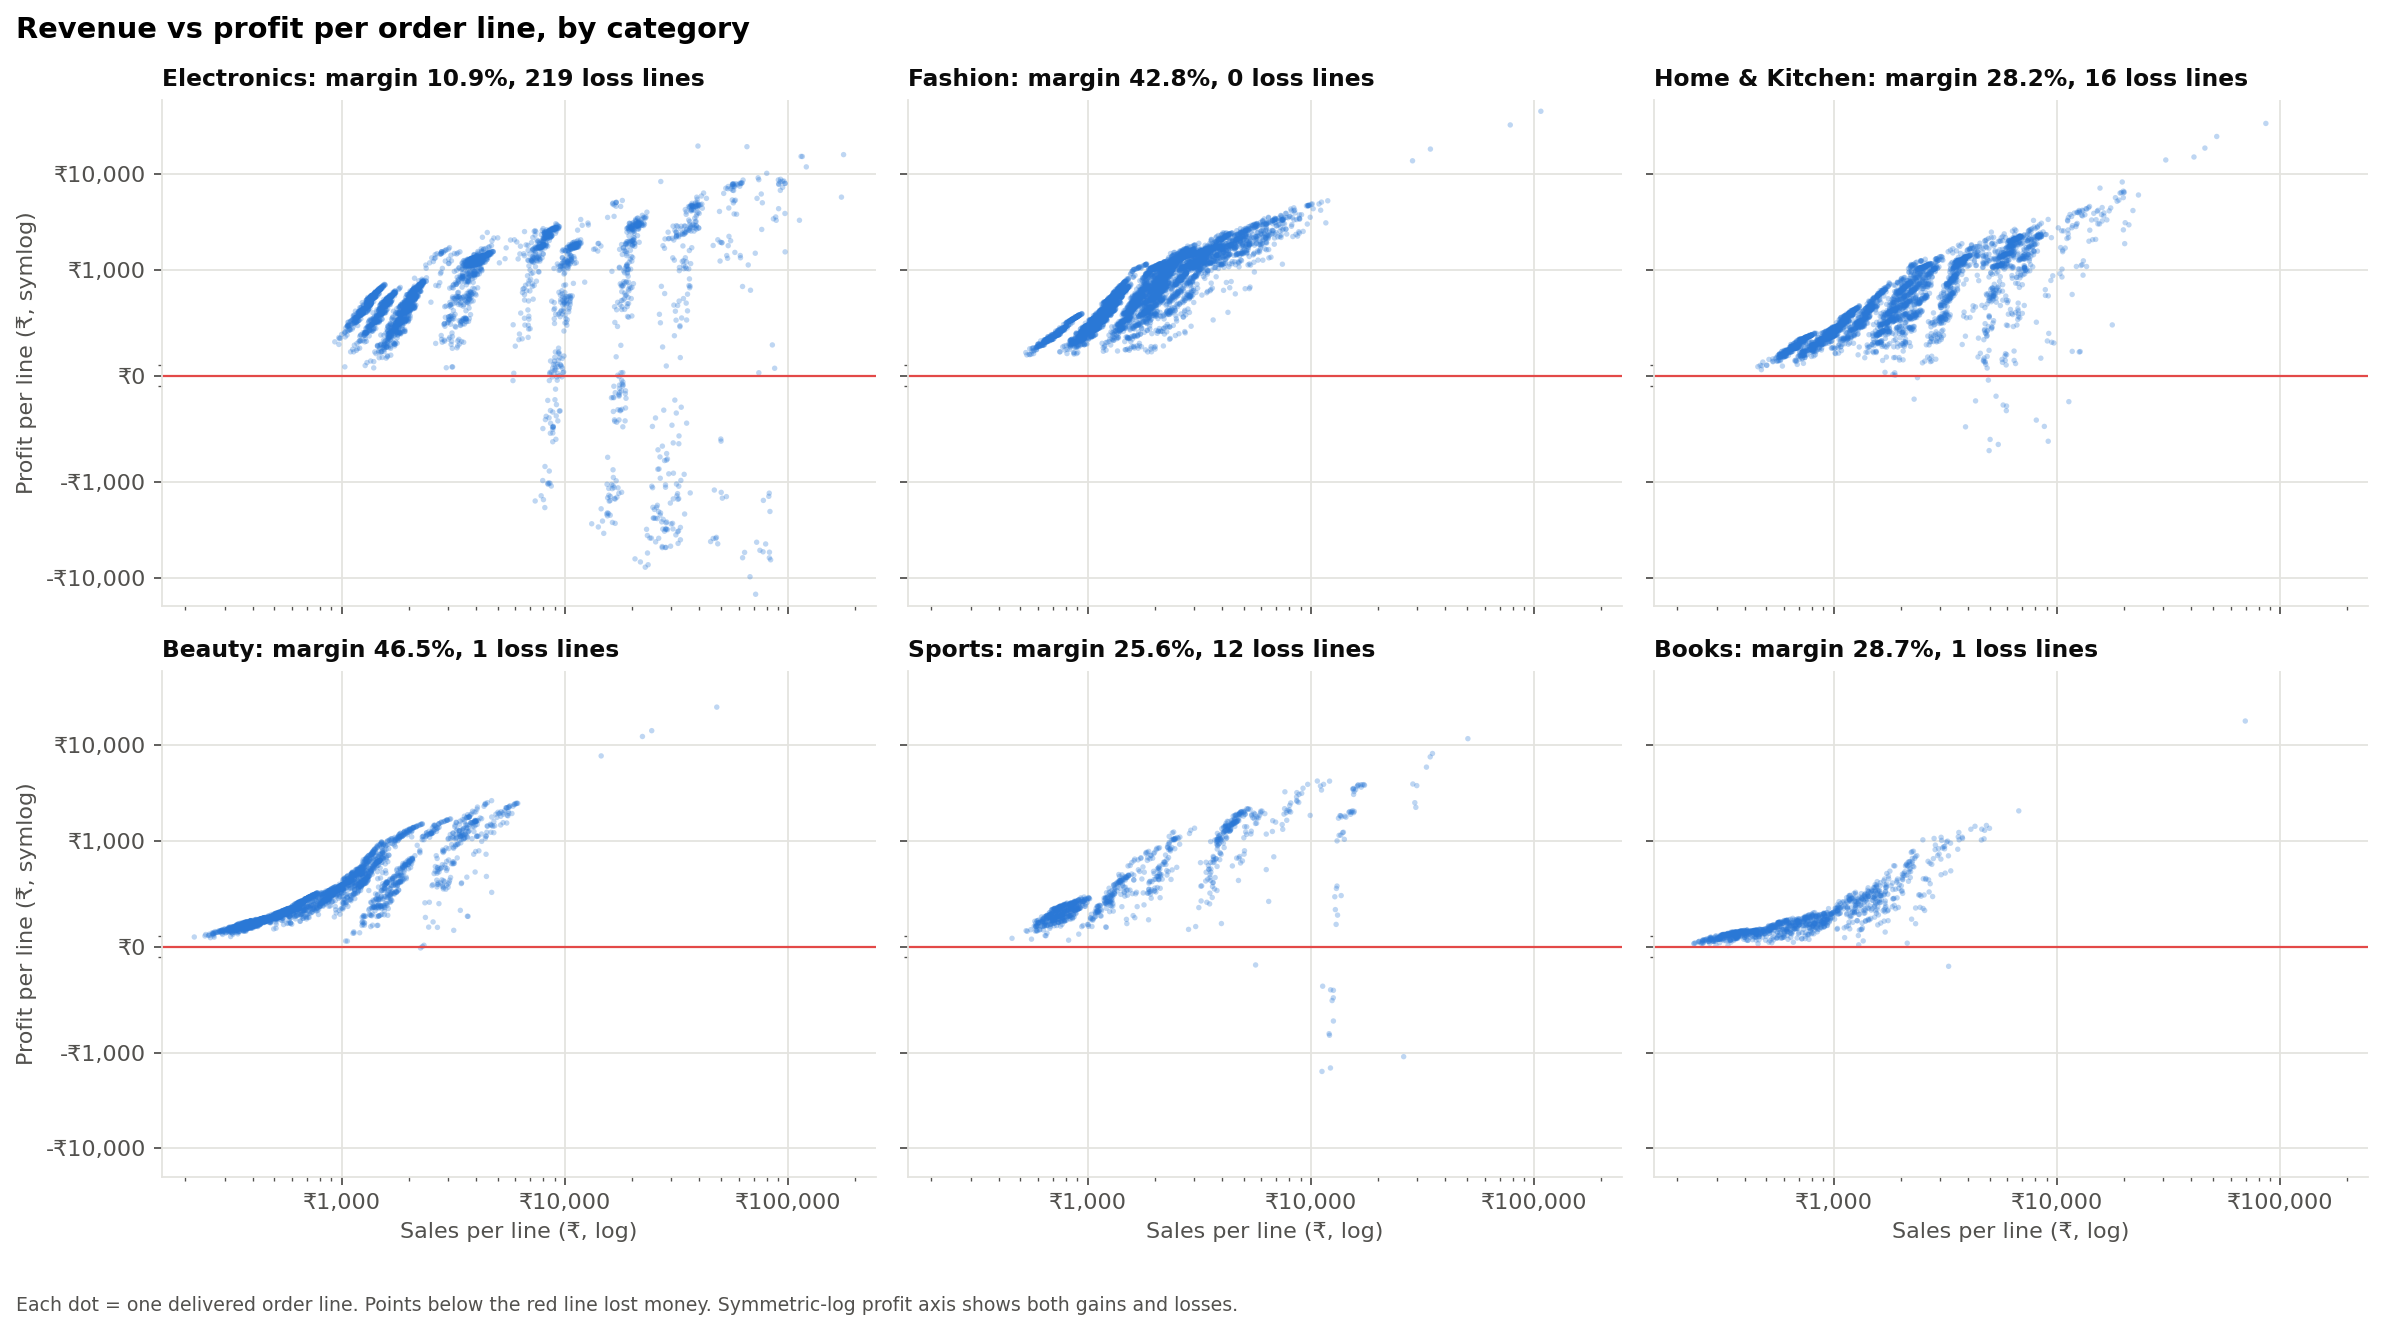

In [59]:
Image(str(FIG / "revenue_vs_profit_scatter.png"))

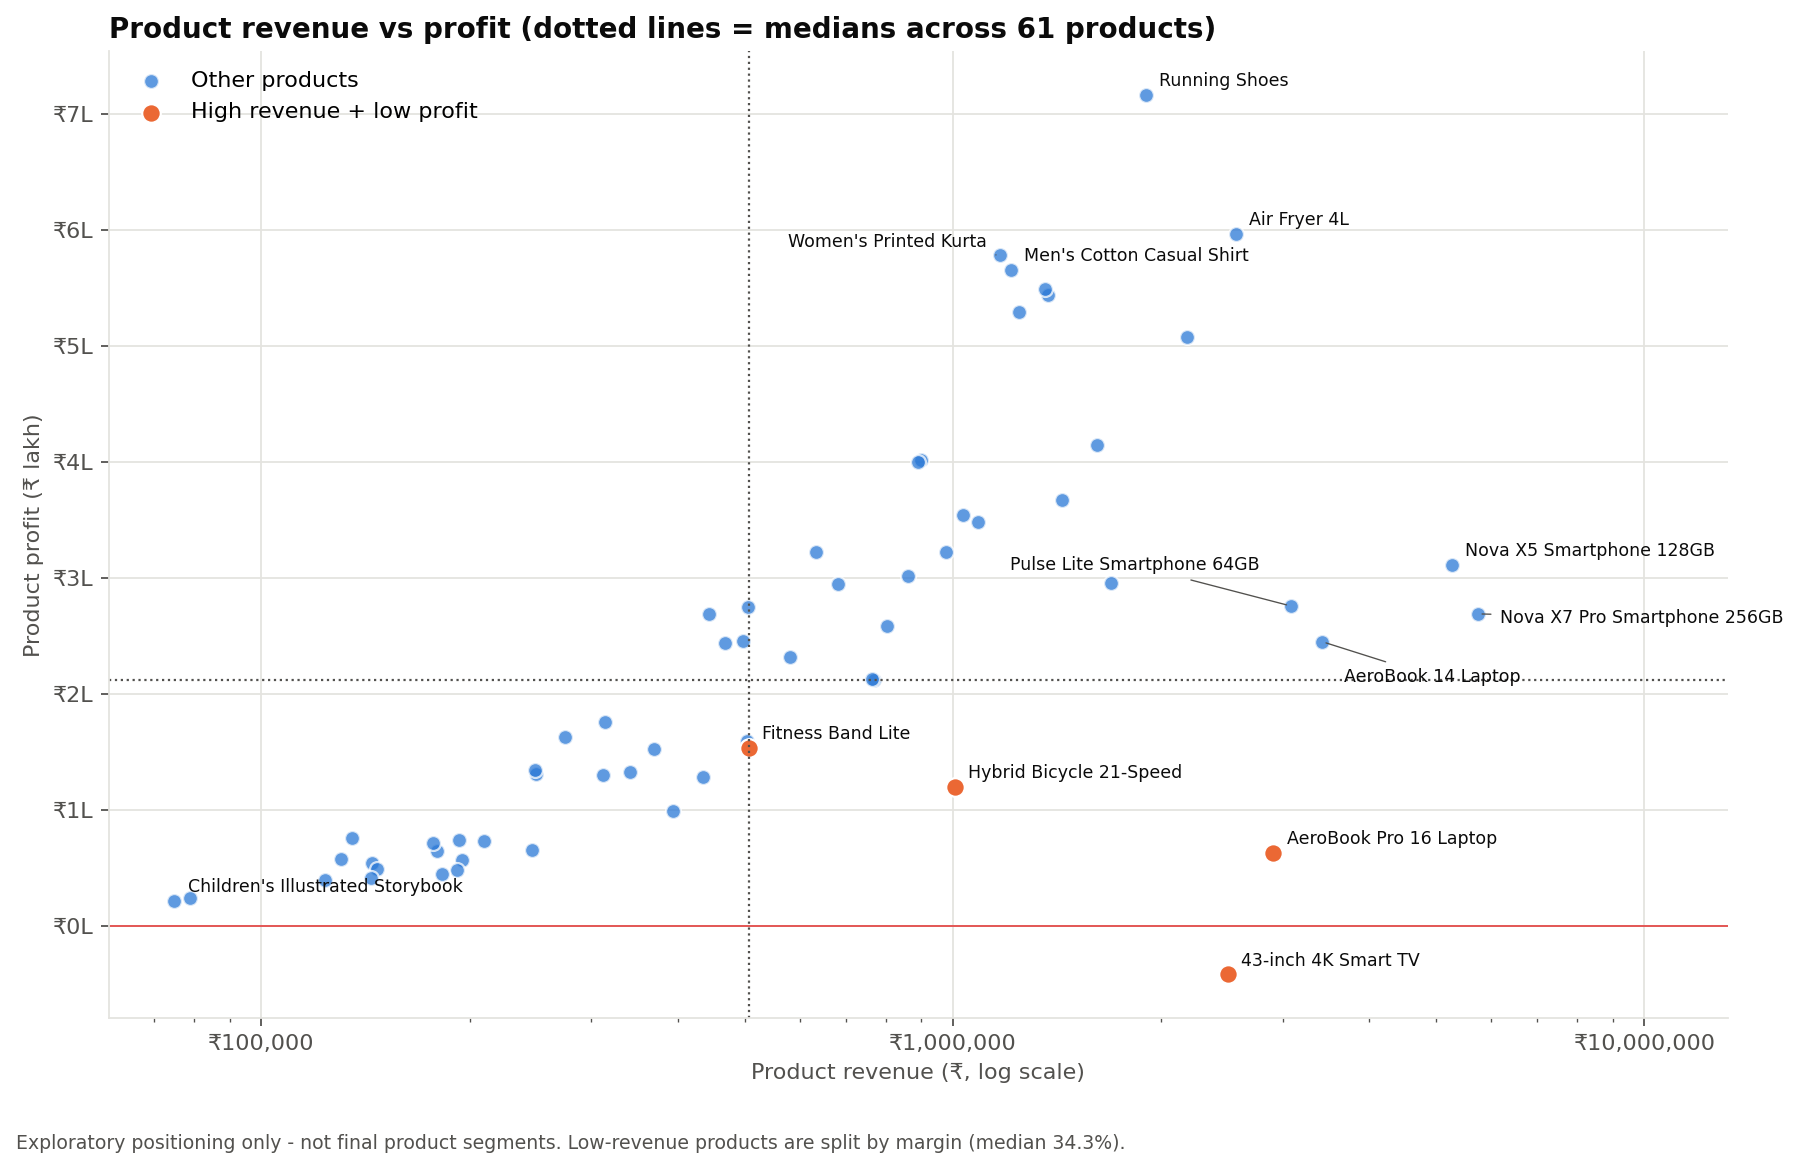

In [60]:
Image(str(FIG / "product_revenue_profit_quadrant.png"))

In [61]:
display(R['profitability']['quadrant_thresholds']); R['profitability']['quadrant_summary']

,Threshold,Value
0,Median product revenue,"506,555.150"
1,Median product profit,"211,933.160"
2,Median product margin,0.343


,Quadrant,Products,Revenue,Profit,Examples (margin),Margin
0,High revenue + high profit,27,"45,229,276.650","10,425,750.070","Running Shoes (38%), Air Fryer 4L (23%), Women's Printed Kurta (49%), Men's Cotton Casual Shirt (47%)",0.231
1,High revenue + low profit,4,"6,918,309.500","294,440.240","43-inch 4K Smart TV (-2%), AeroBook Pro 16 Laptop (2%), Hybrid Bicycle 21-Speed (12%), Fitness Band Lite (30%)",0.043
2,Low revenue + high margin,18,"5,193,414.950","2,523,471.470","Leather Wallet (54%), Vitamin C Face Serum (61%), Perfume 100ml (50%), Polarised Sunglasses (52%)",0.486
3,Low revenue + low margin,12,"2,715,568.050","778,889.800","English Willow Cricket Bat (32%), Hair Dryer 1200W (29%), Adjustable Dumbbell Set 20kg (25%), Camping Tent 4-Person ...",0.287


**Observation.**
- Line-level profit rises with sales in every category. Electronics alone has a large cluster of loss-making lines: 219 of the 249 loss lines.
- Four products are **high revenue but low profit**: the 43-inch TV, AeroBook Pro 16, Hybrid Bicycle and Fitness Band Lite, with a combined margin of 4.3%.
- Eighteen products are low revenue but high margin (48.6% combined), mainly Beauty and Fashion accessories.

**Interpretation.** The high-revenue, low-profit products are candidates for price, cost or discount review. The low-revenue, high-margin products are candidates for more visibility. *These quadrants are exploratory positioning only, not final product segments.*

### 10.3 Payment methods and order status

In [62]:
R['payment_status']['payment_summary']

,Payment_Method,Orders,Booked_Sales,Revenue,Cancel_Rate,Return_Rate,Order_Lines,Order_Share,Revenue_Share,AOV
0,UPI,6084,"31,464,585.250","28,621,334.750",0.035,0.075,8578,0.459,0.477,"4,875.036"
1,Card,2626,"13,100,670.350","11,854,692.400",0.030,0.080,3681,0.198,0.197,"4,654.375"
2,COD,1958,"9,723,828.150","8,512,267.350",0.062,0.108,2809,0.148,0.142,"4,633.787"
3,Wallet,1238,"5,991,409.300","5,435,190.300",0.032,0.082,1755,0.093,0.091,"4,536.887"
4,Net Banking,1256,"5,776,973.400","5,420,388.350",0.033,0.075,1758,0.095,0.090,"4,464.900"
5,Unknown,89,"254,535.900","212,696.000",0.079,0.045,89,0.007,0.004,"2,593.854"


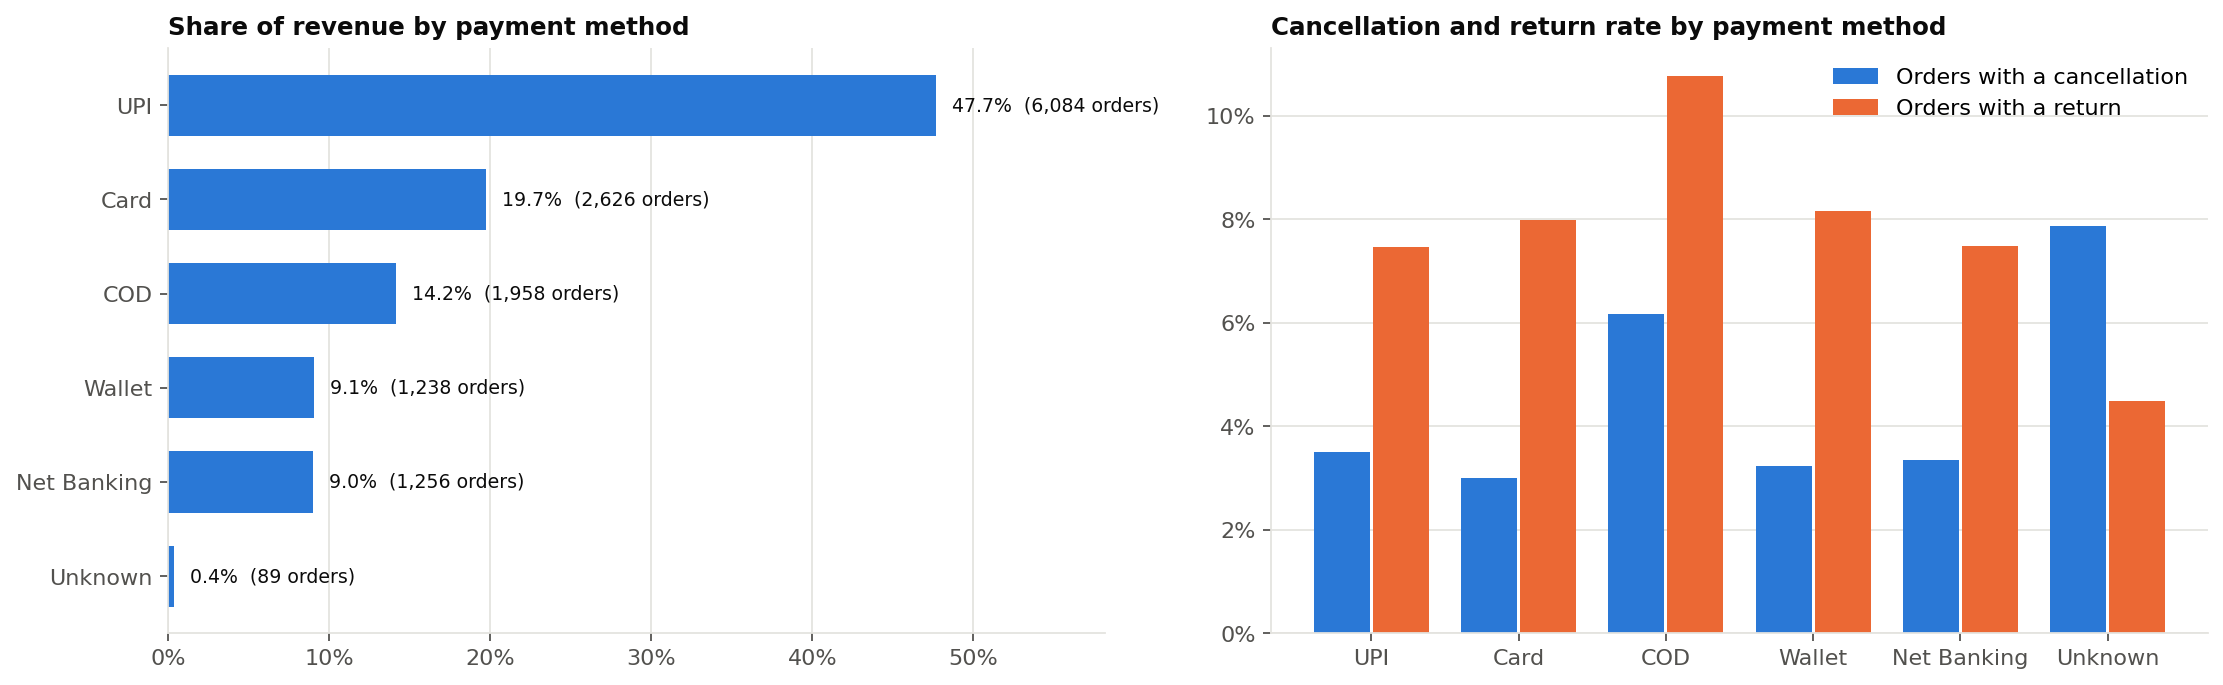

In [63]:
Image(str(FIG / "payment_method_analysis.png"))

In [64]:
display(R['payment_status']['status_summary']); R['payment_status']['status_by_category']

,Order_Status,Lines,Orders_Touched,Sales_Value,Profit_Value,Line_Share,Value_Share,Counted_in_Revenue
0,Cancelled,709,502,"2,743,594.300","551,910.740",0.038,0.041,No - reported separately
1,Delivered,16860,12212,"60,056,569.150","14,022,551.580",0.903,0.906,Yes
2,Returned,1101,1074,"3,511,838.900","1,012,382.780",0.059,0.053,No - reported separately


Order_Status,Category,Cancelled,Delivered,Returned
0,Beauty,0.043,0.928,0.029
1,Books,0.046,0.932,0.021
2,Electronics,0.037,0.922,0.041
3,Fashion,0.034,0.857,0.109
4,Home & Kitchen,0.040,0.923,0.036
5,Sports,0.031,0.930,0.039


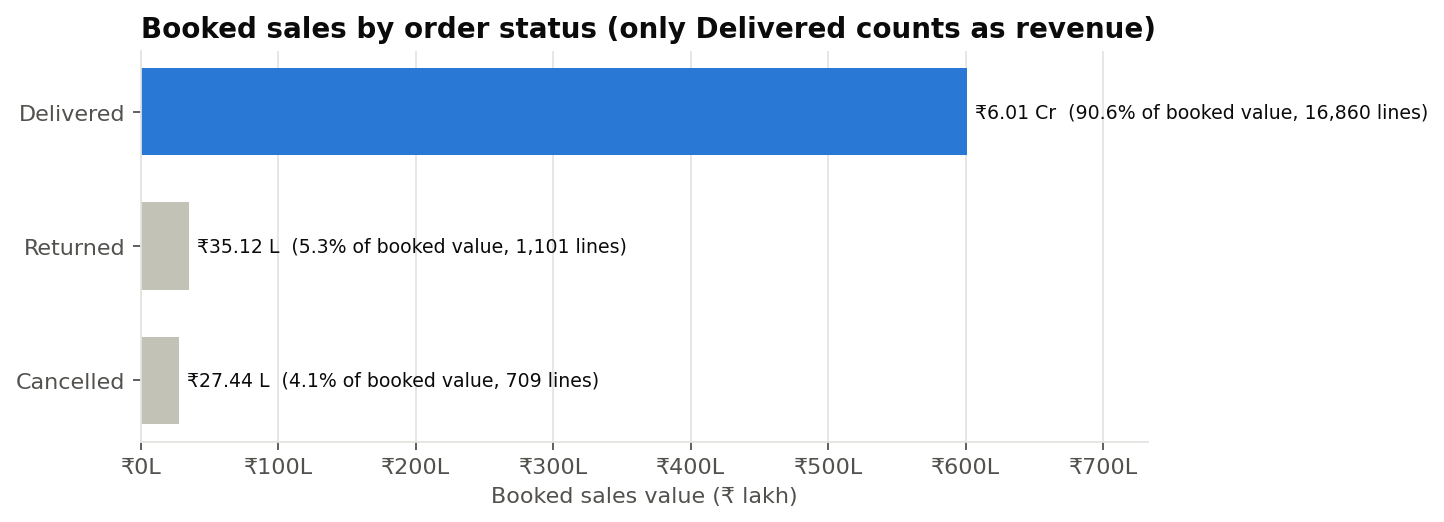

In [65]:
Image(str(FIG / "order_status_value.png"))

**Observation.**
- UPI carries 47.7% of revenue.
- **COD has the highest cancellation rate (6.2% of orders, against 3.0%-3.5% for prepaid methods) and the highest return rate (10.8%).**
- Returned lines are worth ₹35.1 L and cancelled lines ₹27.4 L. **Fashion's return rate (10.9%) is 2.6× the next-highest category.**

**Treatment of order status.** Only Delivered lines count as revenue and profit. Cancelled lines never shipped. Returned lines were refunded, and their logistics costs are not in the data. Including either would overstate revenue by 9.4%. The *Unknown* payment group has only 89 orders, so its rates are not reliable.

## 11. Correlation Analysis

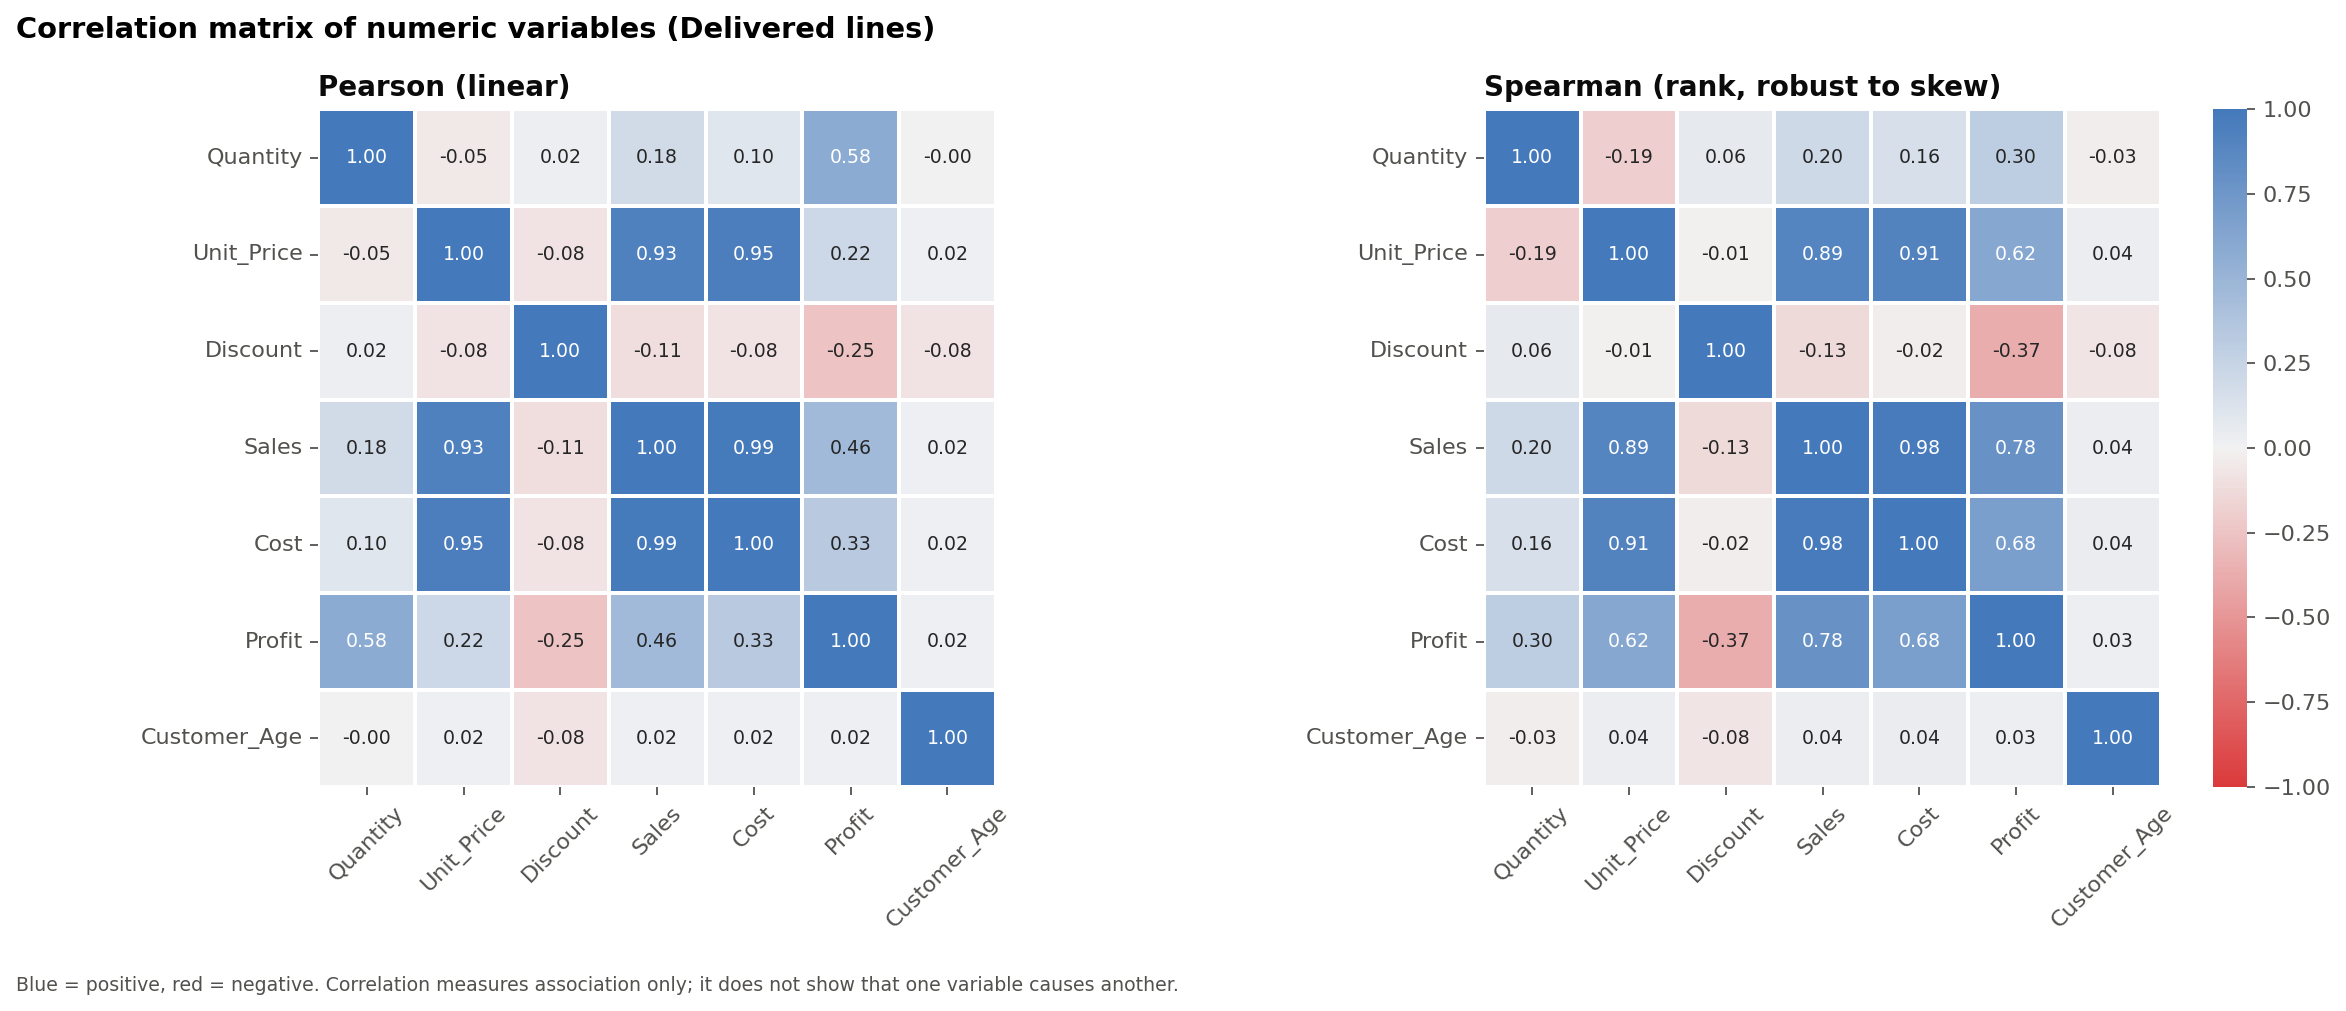

In [66]:
Image(str(FIG / "correlation_heatmap.png"))

In [67]:
R['correlations']['correlation_pairs']

,Variable_1,Variable_2,Pearson_r,Spearman_rho,Strength (Spearman)
15,Sales,Cost,0.990,0.978,strong positive
8,Unit_Price,Cost,0.949,0.914,strong positive
7,Unit_Price,Sales,0.926,0.894,strong positive
16,Sales,Profit,0.460,0.784,strong positive
18,Cost,Profit,0.332,0.685,moderate positive
9,Unit_Price,Profit,0.216,0.616,moderate positive
13,Discount,Profit,-0.254,-0.374,weak negative
4,Quantity,Profit,0.585,0.295,weak positive
2,Quantity,Sales,0.181,0.205,weak positive
0,Quantity,Unit_Price,-0.052,-0.192,negligible


**Observation (Spearman ρ; strong ≥ 0.7, moderate 0.4-0.7, weak 0.2-0.4, negligible < 0.2).**
- **Strong positive:** Sales-Cost (0.98), Unit_Price-Cost (0.91), Unit_Price-Sales (0.89), Sales-Profit (0.78).
- **Moderate positive:** Cost-Profit (0.68), Unit_Price-Profit (0.62).
- **Weak:** Discount-Profit (−0.37, negative), Quantity-Profit (0.30).
- **Negligible:** Customer_Age with every transaction variable (|ρ| ≤ 0.08), Discount-Quantity (0.06).

**Interpretation.**
- The strong correlations are largely **mechanical**, because Sales = Qty × Price × (1 − Discount) and Cost is proportional to price. They say nothing about what *drives* sales.
- Pearson and Spearman differ noticeably for Quantity-Profit (0.58 vs 0.30), because a few bulk lines inflate the Pearson value. This is why the rank-based Spearman is preferred here.
- **Correlation does not imply causation.**
- For Step 8, the mechanical links mean that order-level Sales must not be predicted from Quantity × Price (leakage).

## 12. Outlier & Distribution Analysis

In [68]:
R['outliers']['outlier_percentiles']

,Variable,P1,P5,Median,P95,P99,P99.9,Max,IQR_Lower,IQR_Upper,IQR_Outliers,IQR_Outlier_%,Max_to_P99_ratio
0,Sales,321.836,441.578,"1,706.225","10,878.200","37,050.740","90,936.931","176,942.000","-2,149.487","6,286.212",1779,10.552,4.776
1,Profit,-481.122,154.075,638.520,"2,183.148","4,091.581","12,476.592","45,435.740",-549.821,"1,952.469",1275,7.562,11.105
2,Quantity,1.000,1.000,1.000,3.000,3.000,21.000,50.000,1.000,1.000,4093,24.276,16.667
3,Discount,0.000,0.000,0.100,0.300,0.350,0.400,0.400,-0.300,0.500,0,0.000,1.143
4,Unit_Price,350.590,428.000,"1,612.000","10,640.350","37,844.780","91,969.306","98,119.000","-1,802.375","5,422.625",1788,10.605,2.593


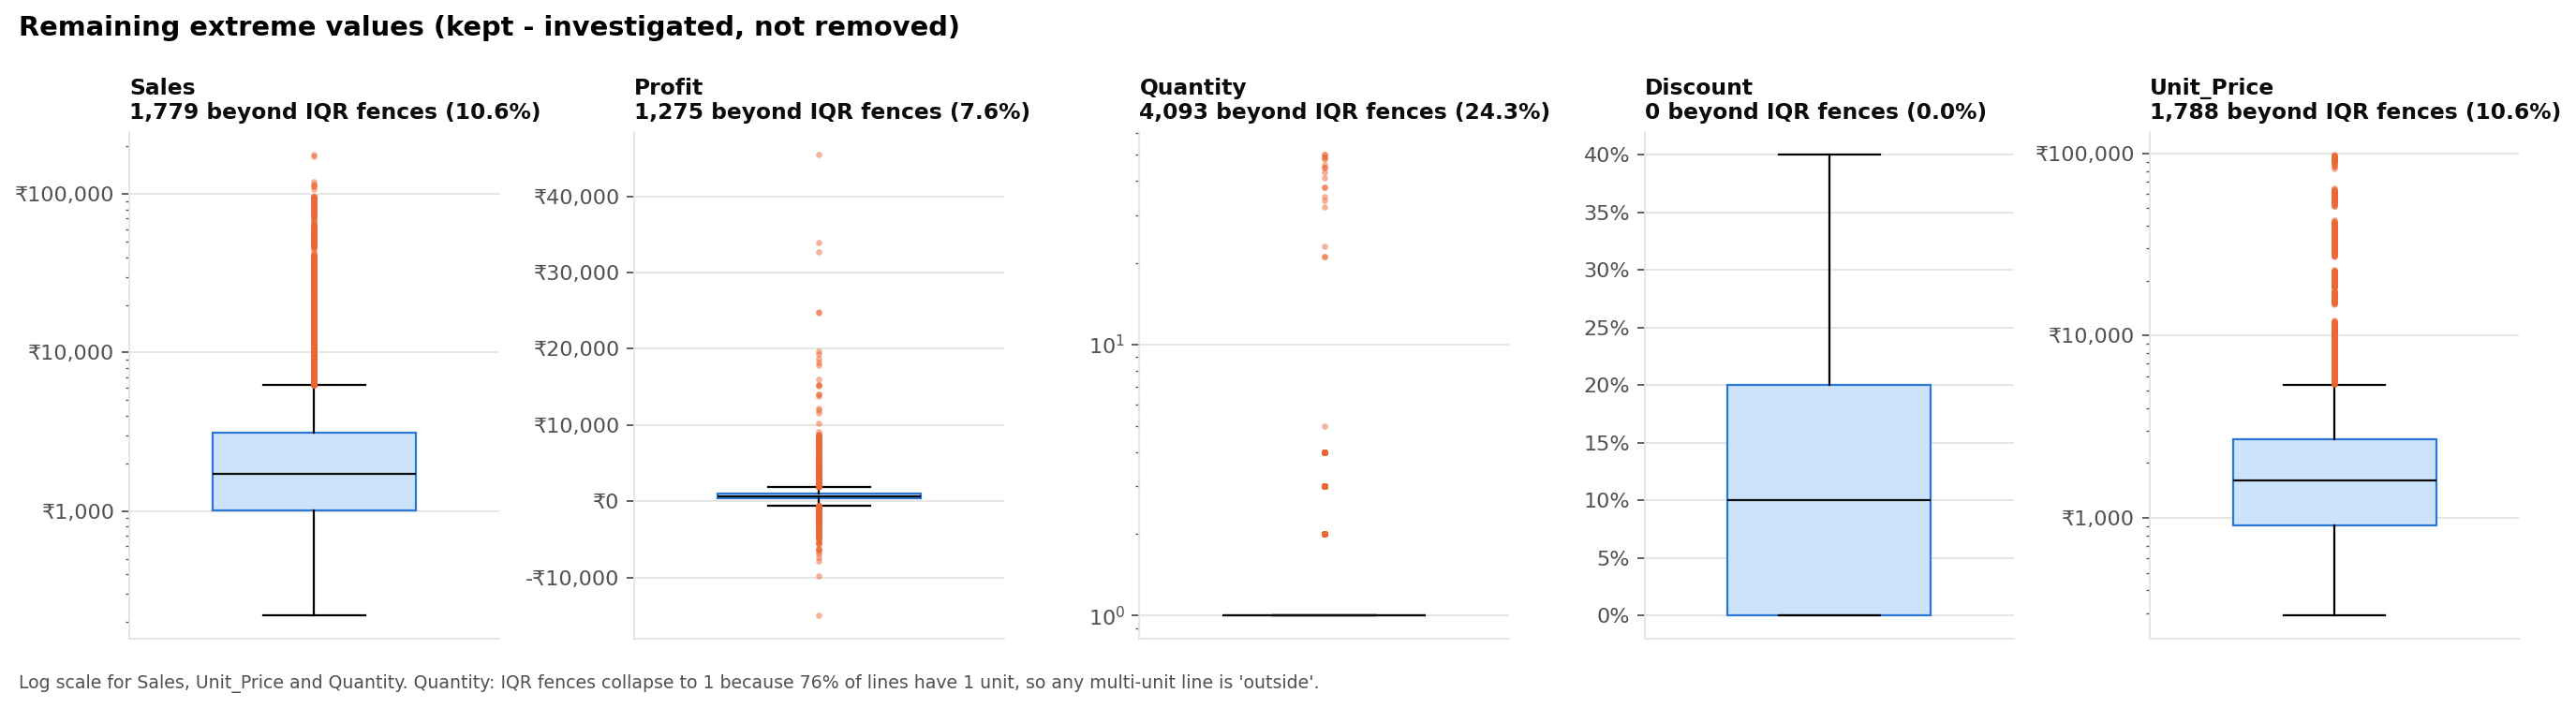

In [69]:
Image(str(FIG / "outlier_boxplots.png"))

In [70]:
display(R['outliers']['top_sales_lines']); display(R['outliers']['worst_profit_lines']); R['outliers']['outlier_classes']

,Order_Line_ID,Order_Date,Customer_ID,Product_Name,Category,Quantity,Unit_Price,Discount,Sales,Profit,Revenue_Check_Pass,Is_Bulk_Order_Line
622,OL-0000623,2023-03-14,CUST-1724,AeroBook Pro 16 Laptop,Electronics,2,"88,471.000",0.000,"176,942.000","15,984.000",True,False
6535,OL-0006536,2024-06-11,CUST-1186,AeroBook Pro 16 Laptop,Electronics,2,"91,110.000",0.050,"173,109.000","5,739.740",True,False
18371,OL-0018372,2025-12-15,CUST-1128,AeroBook 14 Laptop,Electronics,2,"63,415.000",0.050,"120,488.500","11,898.980",True,False
7641,OL-0007642,2024-08-31,CUST-0140,AeroBook 14 Laptop,Electronics,2,"57,829.000",0.000,"115,658.000","15,279.950",True,False
14108,OL-0014109,2025-06-25,CUST-0345,Nova X7 Pro Smartphone 256GB,Electronics,3,"38,050.000",0.000,"114,150.000","15,308.470",True,False
18476,OL-0018477,2025-12-19,CUST-1964,AeroBook 14 Laptop,Electronics,2,"62,364.000",0.100,"112,255.200","3,286.330",True,False
15779,OL-0015780,2025-09-07,CUST-0712,Analog Wrist Watch,Fashion,49,"2,732.000",0.200,"107,094.400","45,435.740",True,True
15961,OL-0015962,2025-09-16,CUST-1230,AeroBook Pro 16 Laptop,Electronics,1,"96,955.000",0.000,"96,955.000","7,987.830",True,False
3072,OL-0003073,2023-10-25,CUST-0652,AeroBook 14 Laptop,Electronics,2,"53,790.000",0.100,"96,822.000","1,534.070",True,False
815,OL-0000816,2023-04-09,CUST-1831,AeroBook 14 Laptop,Electronics,2,"53,691.000",0.100,"96,643.800","3,871.030",True,False


,Order_Line_ID,Product_Name,Category,Quantity,Unit_Price,Discount,Sales,Profit,Revenue_Check_Pass
16610,OL-0016611,AeroBook Pro 16 Laptop,Electronics,1,"95,270.000",0.250,"71,452.500","-14,964.800",True
3159,OL-0003160,AeroBook Pro 16 Laptop,Electronics,1,"84,294.000",0.200,"67,435.200","-9,813.820",True
16151,OL-0016152,43-inch 4K Smart TV,Electronics,1,"32,706.000",0.300,"22,894.200","-7,795.780",True
16692,OL-0016693,43-inch 4K Smart TV,Electronics,1,"33,694.000",0.300,"23,585.800","-7,350.530",True
8895,OL-0008896,43-inch 4K Smart TV,Electronics,1,"31,112.000",0.300,"21,778.400","-6,870.170",True
16897,OL-0016898,AeroBook Pro 16 Laptop,Electronics,1,"98,119.000",0.150,"83,401.150","-6,524.360",True
3013,OL-0003014,43-inch 4K Smart TV,Electronics,1,"29,430.000",0.300,"20,601.000","-6,379.340",True
13952,OL-0013953,43-inch 4K Smart TV,Electronics,3,"32,275.000",0.150,"82,301.250","-6,223.490",True
8587,OL-0008588,Nova X7 Pro Smartphone 256GB,Electronics,2,"39,043.000",0.200,"62,468.800","-6,209.590",True
9084,OL-0009085,43-inch 4K Smart TV,Electronics,1,"31,243.000",0.250,"23,432.250","-5,540.530",True


,Class,Lines,Share_of_Revenue,Assessment
0,Genuine high-value transactions,1777,0.518,Premium items at list price; all pass the Sales formula
1,"Unusual purchases (bulk, >= 10 units)",18,0.014,Formula-consistent; plausible gifting / institutional orders
2,Loss-making lines (Profit < 0),249,0.097,"Business issue (discount on thin margin), not a data error"
3,Data errors (formula failures),0,0.000,None remain after Step 3


**Observation.**
- 10.6% of Sales values lie beyond the upper IQR fence. **All pass the Sales formula**, and they are premium items (laptops, phones, TVs) worth 51.8% of revenue.
- 18 bulk lines (≥ 10 units) are formula-consistent.
- The largest losses are laptops and TVs sold at 15%-30% discount.
- No data errors remain.
- The IQR rule flags 24% of Quantity values only because 76% of lines have 1 unit, so that rule is not meaningful for Quantity.

**Classification.**

| Type | Treatment |
|---|---|
| Genuine high-value transactions | Kept. They are the core of revenue. |
| Unusual purchases (bulk) | Kept and flagged (`Is_Bulk_Order_Line`). |
| Loss-making lines | Kept. They are a business issue, not a data error. |
| Data errors | None found. |

Deleting outliers would remove half of revenue and hide the margin problem. **No rows were removed in this step.**

## 13. Key Business Insights
### 13.1 Business questions (answers computed from the data)

In [71]:
R['business_questions']

,Question,Answer (from data),Evidence table
0,Q1. Which category generates the most revenue?,Electronics: ₹3.01 Cr (50.1% of revenue). Next: Fashion (20.1%).,category_summary.csv
1,Q2. Which category generates the most profit?,"Fashion: ₹51.58 L (36.8% of profit) at a 42.8% margin, although it is only 20.1% of revenue.",category_summary.csv
2,Q3. Which products generate the most revenue?,Nova X7 Pro Smartphone 256GB ₹57.38 L; Nova X5 Smartphone 128GB ₹52.65 L; AeroBook 14 Laptop ₹34.15 L. All three are...,product_summary.csv
3,Q4. Which products generate the most profit?,Running Shoes ₹7.16 L (37.7% margin); Air Fryer 4L ₹5.96 L (23.3% margin); Women's Printed Kurta ₹5.78 L (49.4% marg...,product_summary.csv
4,Q5. Which region generates the most revenue?,South: ₹1.62 Cr (27.0%). Fastest-growing: East (CAGR 52.9% 2023-25).,regional_summary.csv
5,Q6. Which region generates the most profit?,South: ₹37.00 L. Margins are similar across regions (22.2% - 25.3%); highest margin: Central.,regional_summary.csv
6,Q7. What is the monthly revenue trend?,Upward with slowing growth: 2023 ₹1.31 Cr -> 2024 ₹1.98 Cr (+51.4%) -> 2025 ₹2.72 Cr (+37.7%). Month-to-month swings...,monthly_summary.csv
7,Q8. Is there evidence of seasonality?,"Yes, for Q4. The peak month was Oct in all 3 years, and Oct, Nov, Dec were above the year's average month in every y...",seasonal_index.csv
8,Q9. How concentrated is revenue among customers?,"Top 1% of customers -> 9.0%, top 5% -> 30.0%, top 10% -> 45.5%, top 20% -> 64.3% of revenue. Gini = 0.61.",revenue_concentration.csv
9,Q10. What is the relationship between discount and profitability?,"Negative. Line-level Spearman rho(discount, margin) = -0.32; within categories it ranges -0.89 to -0.37. E.g. Fashio...",discount_summary.csv


### 13.2 Insight table
The *Observation* and *Evidence* columns are computed. The *Business Implication* column is interpretation.

In [72]:
R['insights']

,Area,Observation,Evidence,Business Implication (interpretation)
0,Revenue,"Revenue is growing, but growth is slowing",2023 ₹1.31 Cr -> 2024 ₹1.98 Cr (+51.4%) -> 2025 ₹2.72 Cr (+37.7%),Forecasting should model trend plus seasonality; the slowdown is worth diagnosing (fewer new customers or lower freq...
1,Seasonality,October is the peak month every year; Oct-Dec are always above average,"October revenue: 2023 ₹18.48 L, 2024 ₹27.95 L, 2025 ₹30.98 L; Q4 share of year: 2023 37.1%, 2024 35.2%, 2025 29.7%","Plan inventory, staffing and marketing budget around the festive quarter"
2,Seasonality,The festive peak is the least profitable month,October margin 15.3%-16.9% vs overall 23.3%,Festive growth is being bought with discounts; review the depth of festive discounts on thin-margin items
3,Products,Electronics dominates revenue but not profit,"Electronics = 50.1% of revenue, 23.3% of profit, margin 10.9%",Revenue KPIs alone overstate Electronics' contribution; judge categories on profit
4,Products,"Fashion is the profit engine, but has the highest return rate","Fashion = 20.1% of revenue, 36.8% of profit (margin 42.8%); return rate 10.9% vs 4.1% max elsewhere","Reducing Fashion returns (sizing guides, fit tools) could protect the highest-margin revenue"
5,Profitability,Some top-selling items barely break even or lose money,"43-inch 4K Smart TV: revenue ₹24.98 L, profit -₹41,713 (margin -1.7%); AeroBook Pro 16 margin 2.2%; loss-making line...","Review pricing, supplier cost and discount caps for these SKUs"
6,Discount,"Deeper discounts go with lower margins in every category, while quantity barely changes","Within-category Spearman rho(discount, margin): -0.89 to -0.37; rho(discount, quantity) = 0.06",Discounts appear to cost margin without clearly lifting volume; test targeted rather than blanket discounts (associa...
7,Discount,The overall discount-margin table is misleading because of category mix,"Margin by bucket (all categories): 0% 29.3%, 5-10% 19.4%, 15-20% 21.6%, 25-30% 21.4%, 35-40% 20.4%; the 5-10% bucket...",Always compare discount effects within a category (Simpson's paradox)
8,Customers,Revenue is concentrated in a minority of customers,"Top 20% -> 64.3%, top 10% -> 45.5%, top 1% -> 9.0%",Losing a few top customers would hurt disproportionately; they are the priority for retention (RFM/CLV in Steps 5-7)
9,Customers,Frequent buyers drive revenue,"Customers with 11+ orders: 16.2% of buyers, 52.1% of revenue; customer revenue vs order count Spearman rho = 0.842",Growing purchase frequency is a stronger lever than acquiring one-off buyers


## 14. EDA Summary

### 14.1 Data-science quality check

In [73]:
R['quality_checks']

,Check,Value,Pass
0,Dataset is the Step 3 cleaned file,customer_sales_cleaned.csv,True
1,No duplicate Order_Line_ID (no double counting),0,True
2,Order_Date parsed as datetime,datetime64[us],True
3,Dates within 2023-01-01 .. 2025-12-31,2023-01-01 .. 2025-12-31,True
4,"Only Delivered lines in revenue (Revenue column = Sales for Delivered, 0 otherwise)",₹0,True
5,Monthly revenue sums to total revenue,₹6.01 Cr,True
6,Category revenue sums to total revenue,₹6.01 Cr,True
7,Product revenue sums to total revenue,₹6.01 Cr,True
8,Region revenue sums to total revenue,₹6.01 Cr,True
9,Customer-level revenue sums to total revenue,₹6.01 Cr,True


All reconciliation checks pass:
- Monthly, category, product, region and customer totals each sum back to the same ₹6.01 Cr.
- There are no duplicate lines.
- Dates are parsed correctly.
- Only Delivered lines count as revenue.
- No outliers were removed.

### 14.2 Summary
1. **Growth with slowing momentum:** +51% in 2024, then +38% in 2025, with a strong and recurring **Q4 / October peak** that also has the **lowest margin**.
2. **Revenue ≠ profit:** Electronics is half of revenue but under a quarter of profit. Fashion is the profit engine. A few top-selling SKUs lose money.
3. **Discounting erodes margin within every category** without a visible increase in units (association only).
4. **Customer value is concentrated:** the top 20% of customers produce 64% of revenue. Frequency is the strongest correlate of value. About 35% of buyers have lapsed for more than 180 days.
5. **Geography matters for growth, not margin:** South is the largest region and East the fastest-growing.
6. **9.4% of booked sales leak** through cancellations and returns, concentrated in COD orders and Fashion.

### 14.3 Questions for the next steps
- **Step 5 (RFM):** How large are the Champion and At-Risk groups, and how much revenue sits with lapsed buyers?
- **Step 6 (K-Means):** Are there natural behavioural clusters, such as discount-driven buyers or premium Electronics buyers?
- **Step 7 (CLV):** Does a margin-adjusted CLV change who counts as "most valuable"?
- **Step 8 (Prediction):** Can next-6-month revenue be predicted from past frequency, AOV, category mix, discount use and return rate? Features must come from the observation window only, to avoid leakage.
- **Step 9 (Forecasting):** Can a seasonal model beat a seasonal-naive baseline, given the trend, the slowdown and the moving Diwali peak?

The full generated report is `outputs/reports/eda_summary.md`. All tables are in `outputs/tables/` and all figures in `outputs/figures/`.

In [74]:
print("Figures:", len(R["figures_saved"]), "| Tables:", len(R["tables_saved"]))
print("Report :", R["report"].relative_to(config.PROJECT_ROOT))

Figures: 41 | Tables: 33
Report : outputs/reports/eda_summary.md
